### Task Group 0: Reproducible Experiment Setup & Reference Baseline

# Phase 1.5 — Controlled Modeling Experiments

## Task Group 0: Reproducible Experiment Setup & Reference Baseline

### Question

Can Phase 1.5 independently reconstruct the development data, reproduce the
leading Phase 1.4 baseline, and establish a fixed reference condition against
which subsequent modeling changes can be evaluated?

### Why this matters

Phase 1.5 will deliberately change modeling assumptions such as:

- RUL target capping,
- engine weighting,
- feature inclusion,
- temporal representation,
- and model capacity.

These experiments are interpretable only if they begin from a stable reference
condition.

The Phase 1.5 notebook should therefore:

1. reconstruct the modeling data from reusable source code,
2. reproduce the Phase 1.4 train/validation split,
3. reproduce the leading Phase 1.4 baseline,
4. verify that its metrics match the previous phase,
5. and freeze the reference configuration before experimental changes begin.

This prevents later improvements from being confused with accidental changes
to the data split, row population, evaluation metric, or baseline model.

In [1]:
# --- Import dependencies for controlled Phase 1.5 experiments ---
#
# What this does:
# Loads numerical/dataframe tools, the reproducible modeling-data builder,
# evaluation utilities, and the estimator used by the Phase 1.4 reference
# baseline.
#
# Why this matters:
# Phase 1.5 should start from reusable project code rather than variables left
# alive in the Phase 1.4 notebook.
#
# Concept to focus on:
# The experiment notebook should be independently reproducible from a fresh
# kernel.

import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from predictive_maintenance.config import (
    DATASET_NAME,
    RANDOM_STATE,
)

from predictive_maintenance.data.modeling import (
    build_fd001_modeling_data,
)

from predictive_maintenance.models.evaluation import (
    calculate_regression_metrics,
)

from predictive_maintenance.paths import (
    REPORTS_DIR,
)

In [2]:
# --- Confirm the Phase 1.5 notebook is running in the intended environment ---
#
# What this does:
# Displays the active Python interpreter and core reproducibility settings.
#
# Why this matters:
# Reproducibility depends on both the data/code pipeline and the environment in
# which that pipeline executes.
#
# Concept to focus on:
# A new notebook should verify its assumptions rather than inheriting them
# implicitly from an earlier notebook.

print("Python executable:")
print(sys.executable)

print("\nDataset:")
print(DATASET_NAME)

print("\nRandom state:")
print(RANDOM_STATE)

Python executable:
/Users/stuart/repos/ml-predictive-maintenance-mlops/.venv/bin/python3

Dataset:
FD001

Random state:
42


In [3]:
# --- Reconstruct the canonical Phase 1.5 modeling data ---
#
# What this does:
# Rebuilds the same engine-grouped, row-matched modeling representations used
# in Phase 1.4.
#
# Why this matters:
# Phase 1.5 experiments must begin from the same development population as the
# baseline they are intended to improve upon.
#
# Concept to focus on:
# Experimental reproducibility starts with reproducing the DATA contract.

modeling_data = build_fd001_modeling_data()

In [4]:
# --- Create concise aliases for the development datasets ---
#
# What this does:
# Exposes the raw and temporal matrices, targets, and engine groups needed for
# controlled Phase 1.5 experiments.
#
# Why this matters:
# Most Phase 1.5 experiments will deliberately change one component while
# reusing these canonical development objects.
#
# Concept to focus on:
# These objects are the starting condition, not objects to modify in-place.

X_train_raw = modeling_data.X_train_raw
X_validation_raw = modeling_data.X_validation_raw

X_train_temporal = modeling_data.X_train_temporal
X_validation_temporal = modeling_data.X_validation_temporal

y_train = modeling_data.y_train
y_validation = modeling_data.y_validation

groups_train = modeling_data.groups_train
groups_validation = modeling_data.groups_validation

In [5]:
# --- Verify the development population inherited from Phase 1.4 ---
#
# What this does:
# Confirms row alignment, temporal dimensionality, and engine-group isolation.
#
# Why this matters:
# If Phase 1.5 accidentally changes the development population, subsequent
# performance differences cannot be cleanly attributed to the modeling
# experiment itself.
#
# Concept to focus on:
# Before changing an experimental variable, freeze the surrounding conditions.

assert X_train_temporal.shape[1] == 36
assert X_validation_temporal.shape[1] == 36

assert X_train_temporal.index.equals(
    y_train.index
)

assert X_validation_temporal.index.equals(
    y_validation.index
)

assert X_train_temporal.index.equals(
    groups_train.index
)

assert X_validation_temporal.index.equals(
    groups_validation.index
)

assert set(
    groups_train.unique()
).isdisjoint(
    set(groups_validation.unique())
)

print(
    "Training engines:",
    groups_train.nunique(),
)

print(
    "Validation engines:",
    groups_validation.nunique(),
)

print(
    "Train/validation engine overlap:",
    len(
        set(groups_train.unique())
        & set(groups_validation.unique())
    ),
)

Training engines: 80
Validation engines: 20
Train/validation engine overlap: 0


In [6]:
# --- Load the persisted Phase 1.4 baseline results ---
#
# What this does:
# Reads the results table created at the end of the previous modeling phase.
#
# Why this matters:
# Phase 1.5 should be able to verify that its reconstructed reference baseline
# agrees with the documented Phase 1.4 result.
#
# Concept to focus on:
# Saved results provide historical evidence; they do not replace reproducing
# the experiment itself.

phase_14_results_path = (
    REPORTS_DIR
    / "phase_14_baseline_results.csv"
)

phase_14_results = pd.read_csv(
    phase_14_results_path
)

phase_14_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae,rmse_generalization_gap
0,LinearRegression,temporal,36,41.869866,31.197351,32.078035,24.738745,-10.672516
1,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866,17.539716
2,LinearRegression,raw,18,42.002927,31.354520,32.207903,24.895570,-10.648406
3,RandomForestRegressor,temporal,36,11.768613,32.305091,7.811605,23.772653,20.536478
4,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616,-8.395349
5,DummyRegressor(mean),naive,0,68.669077,64.682864,56.378310,54.460967,-3.986213


In [7]:
# --- Identify the recorded leading Phase 1.4 baseline ---
#
# What this does:
# Selects the historical experiment with the lowest validation RMSE.
#
# Why this matters:
# This establishes which completed Phase 1.4 experiment should serve as the
# initial Phase 1.5 reference condition.
#
# Concept to focus on:
# RMSE was declared the primary metric before baseline results were observed.

recorded_leader = (
    phase_14_results
    .sort_values(
        "validation_rmse"
    )
    .iloc[0]
)

print(
    recorded_leader
)

model                      LinearRegression
representation                     temporal
n_features                               36
train_rmse                        41.869866
validation_rmse                   31.197351
train_mae                         32.078035
validation_mae                    24.738745
rmse_generalization_gap          -10.672516
Name: 0, dtype: object


In [8]:
# --- Freeze the Phase 1.5 reference-baseline definition ---
#
# What this does:
# Documents the model and representation that subsequent experiments will use
# as their initial comparison condition.
#
# Why this matters:
# A controlled experiment needs an explicit reference. Otherwise the baseline
# itself can silently drift as experiments accumulate.
#
# Concept to focus on:
# "Baseline" is an experimental condition, not merely whichever previous model
# we happen to remember.

REFERENCE_MODEL = "LinearRegression"
REFERENCE_REPRESENTATION = "temporal"
REFERENCE_FEATURE_COUNT = 36

print(
    "Reference model:",
    REFERENCE_MODEL,
)

print(
    "Reference representation:",
    REFERENCE_REPRESENTATION,
)

print(
    "Reference feature count:",
    REFERENCE_FEATURE_COUNT,
)

Reference model: LinearRegression
Reference representation: temporal
Reference feature count: 36


### Phase 1.5 reference condition

The starting Phase 1.5 reference is the leading Phase 1.4 baseline:

- model: LinearRegression
- representation: simple temporal
- predictors: 36
- target: uncapped RUL
- training weighting: ordinary row weighting
- validation: fixed engine-grouped split
- primary metric: validation RMSE
- secondary metric: validation MAE

Unless an experiment explicitly changes one of these assumptions, it should
remain fixed.

In [9]:
# --- Refit the Phase 1.4 leading baseline from the reconstructed data ---
#
# What this does:
# Fits LinearRegression on the same 36-feature temporal training representation
# used by the Phase 1.4 leader.
#
# Why this matters:
# Before testing improvements, Phase 1.5 should reproduce the reference result
# independently rather than relying on a model object from another notebook.
#
# Concept to focus on:
# Reproduce first. Experiment second.

reference_model = LinearRegression()

reference_model.fit(
    X_train_temporal,
    y_train,
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
# --- Evaluate the reconstructed Phase 1.5 reference baseline ---
#
# What this does:
# Generates training and validation predictions and calculates the same RMSE
# and MAE definitions used throughout Phase 1.4.
#
# Why this matters:
# Every Phase 1.5 experiment needs a stable numerical reference against which
# improvement or degradation can be measured.
#
# Concept to focus on:
# The reference score must be reproduced under the same evaluation contract.

reference_train_predictions = (
    reference_model.predict(
        X_train_temporal
    )
)

reference_validation_predictions = (
    reference_model.predict(
        X_validation_temporal
    )
)

reference_train_metrics = (
    calculate_regression_metrics(
        y_train,
        reference_train_predictions,
    )
)

reference_validation_metrics = (
    calculate_regression_metrics(
        y_validation,
        reference_validation_predictions,
    )
)

print(
    "Reference training metrics:",
    reference_train_metrics,
)

print(
    "Reference validation metrics:",
    reference_validation_metrics,
)

Reference training metrics: RegressionMetrics(rmse=41.869866486512215, mae=32.07803537684641)
Reference validation metrics: RegressionMetrics(rmse=31.197350907736663, mae=24.738744815991875)


In [11]:
# --- Compare the reproduced reference metrics with the saved Phase 1.4 result ---
#
# What this does:
# Finds the recorded temporal LinearRegression result and compares its metrics
# with the independently reconstructed Phase 1.5 baseline.
#
# Why this matters:
# A mismatch would indicate that something changed in the data pipeline,
# experiment configuration, or metric calculation.
#
# Concept to focus on:
# Reproducibility means recreating the result, not merely remembering it.

recorded_reference = (
    phase_14_results
    .loc[
        (
            phase_14_results["model"]
            == REFERENCE_MODEL
        )
        &
        (
            phase_14_results[
                "representation"
            ]
            == REFERENCE_REPRESENTATION
        )
    ]
    .iloc[0]
)

print(
    "Recorded validation RMSE:",
    recorded_reference[
        "validation_rmse"
    ],
)

print(
    "Reproduced validation RMSE:",
    reference_validation_metrics.rmse,
)

print(
    "\nRecorded validation MAE:",
    recorded_reference[
        "validation_mae"
    ],
)

print(
    "Reproduced validation MAE:",
    reference_validation_metrics.mae,
)

Recorded validation RMSE: 31.197350907736663
Reproduced validation RMSE: 31.197350907736663

Recorded validation MAE: 24.738744815991875
Reproduced validation MAE: 24.738744815991875


In [12]:
assert np.isclose(
    reference_validation_metrics.rmse,
    recorded_reference[
        "validation_rmse"
    ],
)

assert np.isclose(
    reference_validation_metrics.mae,
    recorded_reference[
        "validation_mae"
    ],
)

print(
    "Phase 1.4 reference baseline successfully reproduced."
)

Phase 1.4 reference baseline successfully reproduced.


In [13]:
# --- Freeze the reference metrics used for Phase 1.5 comparisons ---
#
# What this does:
# Gives every later experiment the same numerical baseline for calculating
# validation improvement.
#
# Why this matters:
# We do not want each task group quietly redefining what "baseline" means.
#
# Concept to focus on:
# A reference should remain stable until an experiment explicitly establishes
# a new comparison question.

REFERENCE_TRAIN_RMSE = (
    reference_train_metrics.rmse
)

REFERENCE_VALIDATION_RMSE = (
    reference_validation_metrics.rmse
)

REFERENCE_TRAIN_MAE = (
    reference_train_metrics.mae
)

REFERENCE_VALIDATION_MAE = (
    reference_validation_metrics.mae
)

### Reference-baseline rule

The Phase 1.4 temporal LinearRegression result is now the fixed initial
reference condition for Phase 1.5.

A later experiment may become a promising candidate, but the original
reference should not be silently overwritten.

Keeping the reference stable allows us to answer:

"How much did this specific experimental change improve or worsen performance
relative to the established baseline?"

In [14]:
from predictive_maintenance.models.evaluation import (
    calculate_regression_metrics,
    calculate_rmse_reduction,
)

In [15]:
# --- Verify the Phase 1.5 improvement calculation ---
#
# What this does:
# Tests the comparison helper with an easy-to-interpret hypothetical example.
#
# Why this matters:
# Phase 1.5 will repeatedly quantify improvement relative to a reference RMSE.
#
# Concept to focus on:
# Positive RMSE reduction = experiment improved.
# Negative RMSE reduction = experiment worsened.

example_reduction, example_reduction_pct = (
    calculate_rmse_reduction(
        baseline_rmse=20,
        experiment_rmse=18,
    )
)

print(
    example_reduction,
)

print(
    example_reduction_pct,
)

assert np.isclose(
    example_reduction,
    2,
)

assert np.isclose(
    example_reduction_pct,
    10,
)

2.0
10.0


In [16]:
# --- Initialize the Phase 1.5 controlled-experiment registry ---
#
# What this does:
# Creates a consistent structure for recording each experiment, what changed,
# and how performance compared with the reference.
#
# Why this matters:
# Once many experiments have been run, memory is not a reliable record of which
# modeling choices produced which results.
#
# Concept to focus on:
# A useful experiment records both its RESULT and its DESIGN.

PHASE_15_EXPERIMENT_COLUMNS = [
    "experiment",
    "hypothesis",
    "reference",
    "change",
    "train_rmse",
    "validation_rmse",
    "validation_mae",
    "rmse_reduction",
    "rmse_reduction_pct",
    "decision",
    "notes",
]

phase_15_experiments = pd.DataFrame(
    columns=PHASE_15_EXPERIMENT_COLUMNS
)

In [17]:
# --- Register the reference baseline before running experimental changes ---
#
# What this does:
# Records the Phase 1.4 leader as the starting point of the Phase 1.5
# experimental history.
#
# Why this matters:
# Every later result should be interpretable relative to an explicitly recorded
# reference rather than an unstated number.

reference_record = pd.DataFrame(
    [
        {
            "experiment": (
                "Phase 1.4 temporal linear reference"
            ),
            "hypothesis": (
                "Reference condition"
            ),
            "reference": (
                "None"
            ),
            "change": (
                "None"
            ),
            "train_rmse": (
                reference_train_metrics.rmse
            ),
            "validation_rmse": (
                reference_validation_metrics.rmse
            ),
            "validation_mae": (
                reference_validation_metrics.mae
            ),
            "rmse_reduction": 0.0,
            "rmse_reduction_pct": 0.0,
            "decision": (
                "reference"
            ),
            "notes": (
                "Uncapped RUL; ordinary row weighting; "
                "36-feature simple temporal representation."
            ),
        }
    ]
)

phase_15_experiments = pd.concat(
    [
        phase_15_experiments,
        reference_record,
    ],
    ignore_index=True,
)

phase_15_experiments

,experiment,hypothesis,reference,change,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,decision,notes
0,Phase 1.4 temporal linear reference,Reference condition,None,None,41.869866,31.197351,24.738745,0.0,0.0,reference,Uncapped RUL; ordinary row weighting; 36-featu...


### Phase 1.5 experiment decisions

Each experiment should eventually receive one of three broad decisions.

**Keep**

The experimental change produces sufficiently promising validation evidence to
deserve further testing or combination.

**Reject**

The change clearly fails to improve the relevant validation behavior or
introduces an undesirable tradeoff.

**Uncertain**

The result is too small, inconsistent, or dependent on the current validation
split to justify a confident decision.

These decisions remain provisional until stronger grouped cross-validation is
performed later.

A small numerical improvement should not automatically be labeled "keep."

### Controlled-experiment contract

For each Phase 1.5 experiment:

1. State the hypothesis before running the experiment.
2. State exactly which modeling assumption changes.
3. State which important conditions remain fixed.
4. Train under the experimental condition.
5. Evaluate with the same validation contract.
6. Compare against the appropriate reference.
7. Interpret only the change that was actually tested.
8. Record the result as keep, reject, or uncertain.

Examples:

RUL-capping experiment:
- change: target definition
- fixed: model, features, engine split, weighting

Engine-weighting experiment:
- change: training sample weights
- fixed: target, features, model, split

Sensor-6 ablation:
- change: inclusion of Sensor 6
- fixed: target, model, other features, split

This prevents a performance difference from becoming impossible to attribute.

In [18]:
# --- Verify that official test answers remain outside Phase 1.5 development ---
#
# What this does:
# Confirms that the modeling-data object continues to expose inference inputs
# without exposing official endpoint RUL answers.
#
# Why this matters:
# Phase 1.5 will involve substantially more experimentation and therefore an
# even greater risk of overfitting if official test feedback enters the loop.
#
# Concept to focus on:
# More experimentation makes test-label isolation MORE important, not less.

assert not hasattr(
    modeling_data,
    "test_rul_df",
)

assert not hasattr(
    modeling_data,
    "test_rul",
)

print(
    "Official test answers remain outside Phase 1.5 development."
)

Official test answers remain outside Phase 1.5 development.


In [19]:
# --- Run the final Phase 1.5 setup and reference-baseline audit ---
#
# What this does:
# Verifies data alignment, grouping, feature dimensions, reference-model
# reproduction, and experiment-registry initialization.
#
# Why this matters:
# Once this passes, Phase 1.5 can focus entirely on controlled modeling
# hypotheses rather than uncertainty about the reference condition.
#
# Concept to focus on:
# A trustworthy experiment requires a trustworthy baseline.

assert X_train_temporal.shape[1] == 36
assert X_validation_temporal.shape[1] == 36

assert X_train_temporal.index.equals(
    y_train.index
)

assert X_validation_temporal.index.equals(
    y_validation.index
)

assert set(
    groups_train.unique()
).isdisjoint(
    set(groups_validation.unique())
)

assert np.isclose(
    reference_validation_metrics.rmse,
    recorded_reference[
        "validation_rmse"
    ],
)

assert np.isclose(
    reference_validation_metrics.mae,
    recorded_reference[
        "validation_mae"
    ],
)

assert len(
    phase_15_experiments
) == 1

assert (
    phase_15_experiments
    .iloc[0]["decision"]
    == "reference"
)

print(
    "Phase 1.5 Task Group 0 complete:"
    " reference baseline reproduced and experiment contract frozen."
)

Phase 1.5 Task Group 0 complete: reference baseline reproduced and experiment contract frozen.


### Task Group 0 — Interpretation Questions

1. **Why should `04_controlled_experiments.ipynb` independently reproduce the
   Phase 1.4 reference baseline instead of simply trusting the saved validation
   RMSE or relying on a model object left in the previous notebook?**

This is done as a quality control measure. When starting a new notebook, a new set of checks is needed to confirm we are working with a dataset that was as reliable as the one used in the previous notebook. Carry-through errors at this stage of the development process could have significant consequences for our choice of model and its ability to generalize to unseen data.

2. **What exactly constitutes the initial Phase 1.5 reference condition beyond
   simply saying "temporal LinearRegression"?**

There are also several other qualifiers associated with what we are using as the reference condition. It also has uncapped lifecycles, equal row weighting, and more. (I'm not sure how to confidently answer this question beyond that.)

*The reference condition is the entire modeling configuration, not just the estimator: temporal LinearRegression with the 36-feature simple temporal representation, uncapped RUL, ordinary row weighting, the fixed 80/20 engine split, matched cycle 5+, and the established RMSE/MSE evaluation contract.*

3. **If the reconstructed temporal LinearRegression produces a meaningfully
   different validation RMSE from Phase 1.4, why should we investigate that
   discrepancy before running any Phase 1.5 experiments?**

Because that would indicate there is a mistake in either the reconstructed model or the original model. If we were to proceed while knowing there was a mistake and without knowing the details, it could have signficant consequences for our ability to choose a final model. Any time a quality check fails need to either make a correction or be able to provide justification for moving on without correcting it.

4. **In a controlled RUL-capping experiment, what is the experimental variable,
   and which major modeling choices should remain fixed?**

The experimental variable is total lifecycle. All other modeling choices will remain fixed (number of features, family of model, etc.). I'm not sure how to answer this one past that. 

*We aren't changing the engines' lifecycles. The experimental variable is target definition: uncapped RUL vs. capped RUL.*

*The experimental variable is the RUL target definition—uncapped RUL versus a specified capped RUL target. The model family, feature representaion, train/validation engines, weighting policy, preprocessing procedure, and evaluation framework should remain fixed so that any performance change can be attributed as cleanly as possible to target capping.*

5. **Why should a tiny numerical validation improvement not automatically cause
   an experiment to receive a `keep` decision?**

A tiny numerical validation might not effort to keep in the model. If a numerical validation improvement is tiny, it might not be pulling its weight as something that we can think of as relevant to a model predictive abilities. 

*A tiny validation improvement may be sampling noise from the particular held-out engines rather than a robust gain, and it may not justify added model complexity. Small differences should therefore be treated cautiously until they prove consistent across stronger validation such as grouped cross-validation.*

6. **Why does increased experimentation in Phase 1.5 make protection against
   validation overfitting and official-test leakage especially important?**

If we were to miss any leakage from the official test set or if we were to move model decisions in the direction of validation overfitting, then we would potentially wind up choosing a model with inaccurate predictive readings prior to judging its accuracy with the final test. 

*Phase 1.5 involves many more modeling decisions, so repeatedly selecting changes based on the same validation engines increases the risk that the overall pipline becomes specialized to that validation split. Official test leakage would be even more serious because test performance is supposed to remain completely outside the development loop. Validation may guide choices cautiously and the test set must only judge the locked final system.*

**An experimental condition is more than a model name.**

**RUL capping changes the target `y`; it does not change the engine lifecycle or the feature set.**

**A tiny validation win may be split-specific noise; more experimentation increases the chance of overfitting the validation set.**

### Task Group 1: RUL Capping Experiments

## Task Group 1: RUL Capping Experiments

### Question

Does replacing exact high-RUL training targets with capped RUL targets make the
prediction problem more learnable, and what tradeoff does that introduce
relative to predicting exact uncapped RUL?

### Why this matters

Phase 1.2 and Phase 1.4 provided evidence that exact RUL prediction may be
especially difficult when an engine is still far from failure.

At high RUL, two engines may appear similarly healthy even though one
eventually survives substantially longer than the other.

RUL capping changes the modeling assumption.

Instead of requiring the model to distinguish:

180 cycles remaining
from
250 cycles remaining

a cap of 125 would define both targets as:

125

This can be interpreted approximately as:

"At least 125 cycles remain; exact long-horizon RUL is not being modeled."

However, capping changes `y`, not `X`, and therefore changes the prediction
target itself.

A lower RMSE against capped validation labels cannot automatically be described
as an improvement over uncapped RMSE because the two metrics score different
target definitions.

In [20]:
# --- Import the reusable RUL target transformation ---
#
# What this does:
# Loads the function that converts uncapped RUL into a capped target.
#
# Why this matters:
# Each capping experiment should use exactly the same target-transformation
# implementation.
#
# Concept to focus on:
# Capping changes y. It does not change engine history or predictor features.

from predictive_maintenance.data.targets import (
    cap_rul_target,
)

In [21]:
# --- Verify RUL capping on a simple example before applying it to the project ---
#
# What this does:
# Applies a 125-cycle cap to values below, at, and above the threshold.
#
# Why this matters:
# A small known-answer example makes the target transformation explicit before
# it affects thousands of training labels.
#
# Concept to focus on:
# Values below the cap remain unchanged. Values above it collapse to the cap.

example_rul = pd.Series(
    [50, 100, 125, 180, 300]
)

example_capped_rul = cap_rul_target(
    example_rul,
    cap=125,
)

print(
    pd.DataFrame(
        {
            "original_rul": example_rul,
            "capped_rul": example_capped_rul,
        }
    )
)

assert example_capped_rul.tolist() == [
    50,
    100,
    125,
    125,
    125,
]

   original_rul  capped_rul
0            50          50
1           100         100
2           125         125
3           180         125
4           300         125


In [22]:
# --- Predeclare the RUL-cap candidates before observing their model results ---
#
# What this does:
# Defines the small, interpretable target-design search space for this
# experiment.
#
# Why this matters:
# Predeclaring candidate values limits ad-hoc validation optimization.
#
# Concept to focus on:
# Validation should test hypotheses, not become an unrestricted threshold
# search.

RUL_CAP_CANDIDATES = [
    100,
    125,
    150,
]

RUL_CAP_CANDIDATES

[100, 125, 150]

In [23]:
# --- Measure how strongly each candidate cap alters the target distribution ---
#
# What this does:
# Calculates the fraction of training and validation rows whose original RUL
# lies above each candidate threshold.
#
# Why this matters:
# A cap affecting 5% of observations is a much smaller modeling intervention
# than one affecting 50%.
#
# Concept to focus on:
# The cap value controls how much exact long-horizon information is discarded.

cap_impact_records = []

for cap in RUL_CAP_CANDIDATES:
    train_fraction_changed = (
        (y_train > cap).mean()
    )

    validation_fraction_changed = (
        (y_validation > cap).mean()
    )

    cap_impact_records.append(
        {
            "cap": cap,
            "train_fraction_changed": (
                train_fraction_changed
            ),
            "validation_fraction_changed": (
                validation_fraction_changed
            ),
        }
    )

cap_impact_summary = pd.DataFrame(
    cap_impact_records
)

cap_impact_summary

,cap,train_fraction_changed,validation_fraction_changed
0,100,0.502494,0.493734
1,125,0.379472,0.368421
2,150,0.261560,0.248371


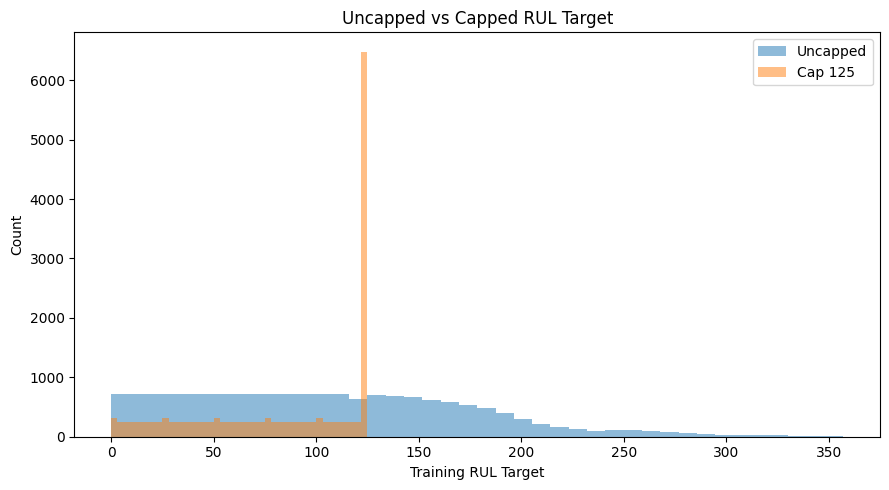

In [24]:
# --- Compare the uncapped and capped training-target distributions ---
#
# What this does:
# Shows how candidate caps collapse high-RUL observations onto fixed upper
# target values.
#
# Why this matters:
# Capping does not simply reduce noise; it intentionally removes distinctions
# between high-RUL observations.
#
# Concept to focus on:
# Target design changes what the model is rewarded for predicting.

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    y_train,
    bins=40,
    alpha=0.5,
    label="Uncapped",
)

plt.hist(
    cap_rul_target(
        y_train,
        cap=125,
    ),
    bins=40,
    alpha=0.5,
    label="Cap 125",
)

plt.xlabel(
    "Training RUL Target"
)

plt.ylabel(
    "Count"
)

plt.title(
    "Uncapped vs Capped RUL Target"
)

plt.legend()

plt.tight_layout()
plt.show()

### Controlled RUL-capping experiment

The experimental variable is:

**RUL target definition**

We will compare:

- uncapped RUL,
- cap = 100,
- cap = 125,
- cap = 150.

The following remain fixed:

- model family: LinearRegression,
- feature representation: 36-feature simple temporal representation,
- training engines,
- validation engines,
- eligible engine-cycle observations,
- ordinary row weighting,
- preprocessing policy,
- RMSE / MAE implementations.

This lets us attribute differences primarily to the target transformation.

### Capped RMSE and uncapped RMSE answer different questions

Suppose:

Model A predicts exact uncapped RUL.

Model B is trained to predict RUL capped at 125.

If an observation has:

actual RUL = 250

then the two possible evaluation targets are:

uncapped target = 250
capped target   = 125

Therefore an RMSE calculated against 125 is not directly interchangeable with
an RMSE calculated against 250.

For each cap, we will therefore inspect two evaluation views:

1. Capped-target evaluation:
   How well does the experiment predict the newly defined capped target?

2. Original-RUL evaluation:
   What happens to exact-RUL accuracy when a model is trained using capped
   labels?

This prevents an easier target from being mistaken automatically for a better
model.

In [25]:
# --- Construct capped training and validation targets for each candidate ---
#
# What this does:
# Applies each predeclared cap while preserving the original row indices.
#
# Why this matters:
# Training and validation must use the same target definition for a particular
# capped-target experiment.
#
# Concept to focus on:
# Validation y may be transformed for scoring, but it still never enters X or
# model fitting.

capped_targets = {}

for cap in RUL_CAP_CANDIDATES:
    y_train_capped = cap_rul_target(
        y_train,
        cap=cap,
    )

    y_validation_capped = cap_rul_target(
        y_validation,
        cap=cap,
    )

    assert y_train_capped.index.equals(
        y_train.index
    )

    assert y_validation_capped.index.equals(
        y_validation.index
    )

    assert (
        y_train_capped
        <= cap
    ).all()

    assert (
        y_validation_capped
        <= cap
    ).all()

    capped_targets[cap] = {
        "train": y_train_capped,
        "validation": y_validation_capped,
    }

print(
    "Capped targets constructed for:",
    list(capped_targets)
)

Capped targets constructed for: [100, 125, 150]


In [26]:
# --- Verify the exact semantics of each RUL cap ---
#
# What this does:
# Confirms that observations at or below the cap remain unchanged and only
# observations above the threshold are altered.
#
# Why this matters:
# A target transformation should change exactly the observations intended by
# the experimental design.

for cap in RUL_CAP_CANDIDATES:
    y_train_capped = (
        capped_targets[cap]["train"]
    )

    below_or_equal_mask = (
        y_train <= cap
    )

    above_mask = (
        y_train > cap
    )

    assert (
        y_train_capped.loc[
            below_or_equal_mask
        ]
        == y_train.loc[
            below_or_equal_mask
        ]
    ).all()

    assert (
        y_train_capped.loc[
            above_mask
        ]
        == cap
    ).all()

print(
    "RUL-cap semantics verified."
)

RUL-cap semantics verified.


In [27]:
# --- Fit identical LinearRegression models under each capped target definition ---
#
# What this does:
# Fits one model per candidate cap using the SAME temporal X but a different
# training target.
#
# Why this matters:
# This isolates target definition as the major experimental variable.
#
# Concept to focus on:
# X stays fixed. y changes.

capped_models = {}
capped_train_predictions = {}
capped_validation_predictions = {}

for cap in RUL_CAP_CANDIDATES:
    model = LinearRegression()

    model.fit(
        X_train_temporal,
        capped_targets[cap]["train"],
    )

    capped_models[cap] = model

    capped_train_predictions[cap] = (
        model.predict(
            X_train_temporal
        )
    )

    capped_validation_predictions[cap] = (
        model.predict(
            X_validation_temporal
        )
    )

print(
    "Capped-target models fitted."
)

Capped-target models fitted.


In [28]:
# --- Evaluate each capped model against its corresponding capped target ---
#
# What this does:
# Calculates validation RMSE and MAE using the target definition associated
# with each cap.
#
# Why this matters:
# This answers whether the newly defined target is learnable under the fixed
# temporal LinearRegression baseline.
#
# Concept to focus on:
# These scores describe different target definitions and should not be treated
# as directly equivalent to uncapped Phase 1.4 RMSE.

capping_records = []

for cap in RUL_CAP_CANDIDATES:
    capped_train_metrics = (
        calculate_regression_metrics(
            capped_targets[cap]["train"],
            capped_train_predictions[cap],
        )
    )

    capped_validation_metrics = (
        calculate_regression_metrics(
            capped_targets[cap]["validation"],
            capped_validation_predictions[cap],
        )
    )

    capping_records.append(
        {
            "cap": cap,
            "train_rmse_capped_target": (
                capped_train_metrics.rmse
            ),
            "validation_rmse_capped_target": (
                capped_validation_metrics.rmse
            ),
            "validation_mae_capped_target": (
                capped_validation_metrics.mae
            ),
        }
    )

capping_results = pd.DataFrame(
    capping_records
)

capping_results

,cap,train_rmse_capped_target,validation_rmse_capped_target,validation_mae_capped_target
0,100,15.550107,14.337627,11.802717
1,125,20.387850,17.757247,14.383085
2,150,25.392441,21.348607,17.008848


In [29]:
# --- Compare capped training with the uncapped reference under the same target ---
#
# What this does:
# Scores the Phase 1.4 reference predictions against each capped validation
# target, then compares them with the model actually trained on that cap.
#
# Why this matters:
# Within a given cap, both models are now judged against exactly the same y,
# making the training-target comparison interpretable.
#
# Concept to focus on:
# Fair metric comparison requires the SAME evaluation target.

reference_on_capped_records = []

for cap in RUL_CAP_CANDIDATES:
    reference_capped_metrics = (
        calculate_regression_metrics(
            capped_targets[cap]["validation"],
            reference_validation_predictions,
        )
    )

    capped_model_metrics = (
        calculate_regression_metrics(
            capped_targets[cap]["validation"],
            capped_validation_predictions[cap],
        )
    )

    rmse_reduction = (
        reference_capped_metrics.rmse
        - capped_model_metrics.rmse
    )

    reference_on_capped_records.append(
        {
            "cap": cap,
            "reference_rmse_on_capped_target": (
                reference_capped_metrics.rmse
            ),
            "capped_model_rmse_on_capped_target": (
                capped_model_metrics.rmse
            ),
            "rmse_reduction_same_target": (
                rmse_reduction
            ),
        }
    )

same_target_comparison = pd.DataFrame(
    reference_on_capped_records
)

same_target_comparison

,cap,reference_rmse_on_capped_target,capped_model_rmse_on_capped_target,rmse_reduction_same_target
0,100,42.719526,14.337627,28.381899
1,125,31.511766,17.757247,13.754519
2,150,26.150226,21.348607,4.801619


In [30]:
# --- Evaluate capped-trained models against the original uncapped RUL target ---
#
# What this does:
# Scores each capped-trained model against the original validation RUL values.
#
# Why this matters:
# This reveals the cost or benefit of target capping if exact RUL remains the
# desired prediction objective.
#
# Concept to focus on:
# A model can become better at the capped task while becoming worse at exact
# long-horizon RUL prediction.

original_rul_records = []

for cap in RUL_CAP_CANDIDATES:
    exact_metrics = (
        calculate_regression_metrics(
            y_validation,
            capped_validation_predictions[cap],
        )
    )

    exact_rmse_change = (
        REFERENCE_VALIDATION_RMSE
        - exact_metrics.rmse
    )

    original_rul_records.append(
        {
            "cap": cap,
            "exact_rul_validation_rmse": (
                exact_metrics.rmse
            ),
            "exact_rul_validation_mae": (
                exact_metrics.mae
            ),
            "exact_rul_rmse_reduction_vs_reference": (
                exact_rmse_change
            ),
        }
    )

original_rul_comparison = pd.DataFrame(
    original_rul_records
)

original_rul_comparison

,cap,exact_rul_validation_rmse,exact_rul_validation_mae,exact_rul_rmse_reduction_vs_reference
0,100,51.967321,37.246186,-20.769970
1,125,41.956210,30.265029,-10.758859
2,150,35.872081,26.587121,-4.674730


### Expected tradeoff from RUL capping

A capped model is deliberately not trained to distinguish exact RUL values
above the cap.

For a 125-cycle cap:

true RUL = 180 → training target = 125
true RUL = 250 → training target = 125

Therefore, if the capped model is later evaluated against original uncapped
RUL, systematic underprediction at high RUL would not be surprising.

That behavior may be a consequence of the target definition rather than an
ordinary model failure.

The target-design decision therefore depends partly on what prediction problem
we actually want the model to solve.

In [31]:
# --- Compare exact prediction performance within each cap's preserved region ---
#
# What this does:
# Evaluates capped and reference predictions only where true validation RUL is
# at or below the candidate cap.
#
# Why this matters:
# These rows retain exactly the same target under both uncapped and capped
# definitions.
#
# Concept to focus on:
# Capping may sacrifice exact high-RUL prediction in exchange for improved
# prediction in the degradation region where exact RUL is retained.

within_cap_records = []

for cap in RUL_CAP_CANDIDATES:
    within_cap_mask = (
        y_validation <= cap
    )

    reference_within_cap_metrics = (
        calculate_regression_metrics(
            y_validation.loc[
                within_cap_mask
            ],
            reference_validation_predictions[
                within_cap_mask.to_numpy()
            ],
        )
    )

    capped_within_cap_metrics = (
        calculate_regression_metrics(
            y_validation.loc[
                within_cap_mask
            ],
            capped_validation_predictions[cap][
                within_cap_mask.to_numpy()
            ],
        )
    )

    within_cap_records.append(
        {
            "cap": cap,
            "n_validation_rows": (
                within_cap_mask.sum()
            ),
            "reference_rmse": (
                reference_within_cap_metrics.rmse
            ),
            "capped_model_rmse": (
                capped_within_cap_metrics.rmse
            ),
            "rmse_reduction": (
                reference_within_cap_metrics.rmse
                - capped_within_cap_metrics.rmse
            ),
        }
    )

within_cap_comparison = pd.DataFrame(
    within_cap_records
)

within_cap_comparison

,cap,n_validation_rows,reference_rmse,capped_model_rmse,rmse_reduction
0,100,2020,29.077457,14.614528,14.462929
1,125,2520,28.160532,17.900770,10.259762
2,150,2999,26.984098,20.957235,6.026862


In [32]:
# --- Measure signed error above each candidate cap using original RUL ---
#
# What this does:
# Calculates whether capped-trained models systematically overpredict or
# underpredict exact RUL in the region they were trained to collapse.
#
# Why this matters:
# Capping should be interpreted partly through the behavior it intentionally
# induces at long prediction horizons.
#
# Concept to focus on:
# Negative signed error above the cap means exact high RUL is being
# underpredicted.

high_rul_bias_records = []

for cap in RUL_CAP_CANDIDATES:
    high_rul_mask = (
        y_validation > cap
    )

    high_rul_errors = (
        capped_validation_predictions[cap][
            high_rul_mask.to_numpy()
        ]
        - y_validation.loc[
            high_rul_mask
        ].to_numpy()
    )

    high_rul_bias_records.append(
        {
            "cap": cap,
            "n_high_rul_rows": (
                high_rul_mask.sum()
            ),
            "mean_signed_error_above_cap": (
                high_rul_errors.mean()
            ),
        }
    )

high_rul_bias_summary = pd.DataFrame(
    high_rul_bias_records
)

high_rul_bias_summary

,cap,n_high_rul_rows,mean_signed_error_above_cap
0,100,1970,-63.223333
1,125,1470,-57.245162
2,150,991,-55.926506


In [33]:
# --- Combine the main RUL-capping evidence into one table ---
#
# What this does:
# Brings together target impact, capped-task performance, original-RUL
# performance, and within-cap exact prediction performance.
#
# Why this matters:
# No single RMSE captures the full target-design tradeoff.

rul_capping_summary = (
    cap_impact_summary
    .merge(
        same_target_comparison,
        on="cap",
    )
    .merge(
        original_rul_comparison,
        on="cap",
    )
    .merge(
        within_cap_comparison,
        on="cap",
    )
)

rul_capping_summary

,cap,train_fraction_changed,validation_fraction_changed,reference_rmse_on_capped_target,capped_model_rmse_on_capped_target,rmse_reduction_same_target,exact_rul_validation_rmse,exact_rul_validation_mae,exact_rul_rmse_reduction_vs_reference,n_validation_rows,reference_rmse,capped_model_rmse,rmse_reduction
0,100,0.502494,0.493734,42.719526,14.337627,28.381899,51.967321,37.246186,-20.769970,2020,29.077457,14.614528,14.462929
1,125,0.379472,0.368421,31.511766,17.757247,13.754519,41.956210,30.265029,-10.758859,2520,28.160532,17.900770,10.259762
2,150,0.261560,0.248371,26.150226,21.348607,4.801619,35.872081,26.587121,-4.674730,2999,26.984098,20.957235,6.026862


### Choosing a target is not the same as choosing the smallest number

A lower capped-target RMSE does not automatically make a more aggressive cap
better.

For example, a cap of 100 changes many more labels than a cap of 150.

An aggressive cap may produce a much easier numerical prediction problem
because substantial long-horizon variation has been deliberately removed.

The target-design decision should therefore consider:

- how much of the target distribution was altered,
- capped-target performance,
- exact-RUL performance,
- performance in the region where exact RUL is retained,
- high-RUL bias,
- and the intended meaning of the prediction.

The question is not merely:

"Which cap produces the smallest RMSE?"

It is:

"Which target definition creates the most useful and defensible RUL prediction
problem?"

In [34]:
# --- Register each cap using exact-RUL validation performance for consistency ---
#
# What this does:
# Adds the target-design experiments to the general Phase 1.5 registry while
# keeping its RMSE column comparable with the original Phase 1.4 reference.
#
# Why this matters:
# Mixing capped-target RMSE and uncapped-target RMSE in one leaderboard would
# create an apples-to-oranges comparison.
#
# Concept to focus on:
# A metric column should preserve one meaning across experiment rows.

for record in original_rul_records:
    cap = record["cap"]

    experiment_record = pd.DataFrame(
        [
            {
                "experiment": (
                    f"RUL cap {cap}"
                ),
                "hypothesis": (
                    "Capping high RUL may improve "
                    "learnability and useful "
                    "degradation-region prediction."
                ),
                "reference": (
                    "Phase 1.4 temporal linear reference"
                ),
                "change": (
                    f"Training target capped at {cap}"
                ),
                "train_rmse": np.nan,
                "validation_rmse": (
                    record[
                        "exact_rul_validation_rmse"
                    ]
                ),
                "validation_mae": (
                    record[
                        "exact_rul_validation_mae"
                    ]
                ),
                "rmse_reduction": (
                    record[
                        "exact_rul_rmse_reduction_vs_reference"
                    ]
                ),
                "rmse_reduction_pct": (
                    record[
                        "exact_rul_rmse_reduction_vs_reference"
                    ]
                    / REFERENCE_VALIDATION_RMSE
                    * 100
                ),
                "decision": (
                    "pending"
                ),
                "notes": (
                    "See rul_capping_summary for "
                    "capped-target and within-cap metrics."
                ),
            }
        ]
    )

    phase_15_experiments = pd.concat(
        [
            phase_15_experiments,
            experiment_record,
        ],
        ignore_index=True,
    )

phase_15_experiments

,experiment,hypothesis,reference,change,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,decision,notes
0,Phase 1.4 temporal linear reference,Reference condition,None,None,41.869866,31.197351,24.738745,0.0,0.0,reference,Uncapped RUL; ordinary row weighting; 36-featu...
1,RUL cap 100,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 100,NaN,51.967321,37.246186,-20.76997,-66.576068,pending,See rul_capping_summary for capped-target and ...
2,RUL cap 125,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 125,NaN,41.95621,30.265029,-10.758859,-34.48645,pending,See rul_capping_summary for capped-target and ...
3,RUL cap 150,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 150,NaN,35.872081,26.587121,-4.67473,-14.984381,pending,See rul_capping_summary for capped-target and ...


### Task Group 1 Findings

#### Cap = 100

Fraction of training targets changed:
[fill]

Capped-target validation RMSE:
[fill]

Exact uncapped-RUL validation RMSE:
[fill]

Exact-RUL RMSE for observations at or below cap:
[fill]

High-RUL signed bias:
[fill]

Interpretation:
[fill]


#### Cap = 125

Fraction of training targets changed:
[fill]

Capped-target validation RMSE:
[fill]

Exact uncapped-RUL validation RMSE:
[fill]

Exact-RUL RMSE for observations at or below cap:
[fill]

High-RUL signed bias:
[fill]

Interpretation:
[fill]


#### Cap = 150

Fraction of training targets changed:
[fill]

Capped-target validation RMSE:
[fill]

Exact uncapped-RUL validation RMSE:
[fill]

Exact-RUL RMSE for observations at or below cap:
[fill]

High-RUL signed bias:
[fill]

Interpretation:
[fill]

### RUL-Capping Decision

Best-supported target design on the current validation split:
[uncapped / cap 100 / cap 125 / cap 150 / uncertain]

Evidence:
[fill]

Tradeoff:
[fill]

Decision:
[keep / reject / uncertain]

Important limitation:
This conclusion is based on the current fixed validation-engine split and
should later be tested across grouped cross-validation folds before the final
target design is locked.

In [35]:
# --- Verify the controlled RUL-capping experiment ---
#
# What this does:
# Confirms that capping altered targets rather than predictors or observation
# populations and that every candidate produced complete validation predictions.
#
# Why this matters:
# Interpretation is valid only if target definition was the major experimental
# variable.
#
# Concept to focus on:
# Same X and rows. Different y.

for cap in RUL_CAP_CANDIDATES:
    assert capped_targets[
        cap
    ]["train"].index.equals(
        y_train.index
    )

    assert capped_targets[
        cap
    ]["validation"].index.equals(
        y_validation.index
    )

    assert len(
        capped_validation_predictions[cap]
    ) == len(
        y_validation
    )

    assert np.isfinite(
        capped_validation_predictions[cap]
    ).all()

assert X_train_temporal.shape[1] == 36
assert X_validation_temporal.shape[1] == 36

assert len(
    RUL_CAP_CANDIDATES
) == 3

print(
    "Task Group 1 RUL-capping experiment checks passed."
)

Task Group 1 RUL-capping experiment checks passed.


### Task Group 1 — Interpretation Questions

1. **What exactly changes in an RUL-capping experiment, and why is it incorrect
   to describe capping as changing the engine lifecycle or feature set?**

We are changing the target of the model, `X` remains unchanged while `y` is calculated as the minimum value of the preexisting target and the predetermined cap. It's incorrect to describe capping as changing the engine lifecycle or the feature set because both of those are associated with `X`. We're not changing `X`, we're changing `y`.

*RUL capping changes only the definition target of `y`. It does not change the engine's actual observed lifecycle, the engine-cycle rows, or the predictor feature set `X`.*

2. **Why can we not simply compare an RMSE calculated against capped RUL with
   the Phase 1.4 uncapped-RUL RMSE and conclude that whichever number is lower
   represents the better model?**

Because, while the feature set might not have changed between those two situations, we did change the target set `y`. This creates an apples-to-oranges kind of comparison. If we changed the type of model while keeping `X` and `y` unchanged, then if one had a significantly lower RMSE we could call that the better model. But that's not quite what's happening here. 

3. **What does a cap of 125 mean for two training observations whose original
   RUL values are 180 and 250, and what information are we deliberately asking
   the model not to learn?**

Each of those values get turned into 125 for the purposes of giving the model a target value to optimize its prediction for. We are deliberately asking the model to not learn that those two engines have a true RUL value that's above 125. 

*We are asking the model to learn something like "at least 125 cycles remain" instead of distinguishing exactly how far beyond 125 the engine is from failure.*

4. **Why is evaluating capped-trained models on the validation observations
   where true RUL is at or below the cap especially informative?**

Because... I'm unsure of how to confidently answer this one. Because those targets for RUL were not put through any sort of data augmentation, so an error or accuracy towards predicting those readings is especially true and not the result of a probabilistic luck/error phenomenon with the model? 

*Evaluating observations at or below the cap is especially informative because their target values are identical under capped or uncapped RUL. Therefore, we can directly test whether capped training improves exact RUL prediction in the region where the target definition itself has not changed.*

5. **If a capped model greatly improves capped-target RMSE but worsens exact
   uncapped-RUL RMSE, how should that result be interpreted rather than simply
   calling the experiment a success or failure?**

This is another one where I'm unsure of how to give a confident answer :(

*Capping improved performance on the capped prediction problem at the cost of long-horizon RUL accuracy. Whether that is desirable depends on whether exact high-RUL prediction is important and whether capping improves performance in the lower-RUL degradation region.*

***Capping doesn't necessarily make the model better or worse. It may make it better at answering a different question.***

6. **Why did we predeclare a small set of caps such as 100, 125, and 150 rather
   than searching dozens of thresholds and choosing the one with the lowest
   validation RMSE?**

Because we are still in the proof of concept part of this experiment. We want to try just a few values before deciding if this process warrants more experimentation. There is a risk of trying dozens of values and finding out that none of them improve model performance relative to the baseline, which would wind up being considered a significant waste of effort. 

*The main statistical reason is validation overfitting.*

*We predeclared a small number of plausible caps to limit validation-driven threshold searching. Trying many thresholds and selecting whichever performs best on the same 20 validation engines would increase the risk of overfitting our target design to that particular split. The small candidate set gives us a controlled initial test of the capping hypothesis.*

**When you change `y`, a lower error number may mean you've made the prediction problem different, not necessarily that you've produced a better solution to the original problem.**

### Task Group 2: Equal-engine Training Weighting

## Task Group 2: Equal-Engine Training Weighting

### Question

Does giving each development-training engine equal total weight during model
fitting improve generalization compared with ordinary row weighting, where
longer-lived engines contribute more training observations and therefore more
total loss?

### Why this matters

The FD001 training engines have different run-to-failure lengths.

Under ordinary row-level model fitting, every observation receives equal
weight.

Therefore, an engine with 300 eligible observations contributes more total
training loss than an engine with 120 eligible observations.

This may be appropriate if every engine-cycle observation should have equal
importance.

However, it also means that longer-lived engines have more total influence on
the fitted population-level model.

Equal-engine weighting tests a different training objective:

"Should each engine contribute approximately equal total sample-weight mass,
regardless of trajectory length?"

This experiment changes the training objective only.

It does not change:

- X,
- y,
- the train/validation engine split,
- the validation observations,
- or the evaluation metrics.

### What equal-engine weighting changes mathematically

Ordinary least squares approximately minimizes:

`sum of squared errors across all training rows`

Because longer engines contain more rows, they contribute more terms to that
sum.

With row weights of:

`1 / number_of_rows_for_that_engine`

the weighted objective becomes proportional to:

`sum of each engine's mean squared error`

rather than allowing trajectory length alone to determine how many equally
weighted loss terms an engine contributes.

The goal is not to guarantee equal accuracy across engines.

The goal is to test whether equalizing total training weight across engines
produces a model that generalizes better to unseen engines.

In [36]:
# --- Construct equal-engine sample weights for the training population ---
#
# What this does:
# Assigns smaller per-row weights to longer trajectories and larger per-row
# weights to shorter trajectories so every engine has the same total weight.
#
# Why this matters:
# This lets us test whether ordinary row weighting overemphasizes engines that
# happen to contribute more observations.
#
# Concept to focus on:
# We are changing the FITTING OBJECTIVE, not X, y, or the number of rows.

from predictive_maintenance.data.weighting import (
    make_equal_engine_sample_weights,
)

equal_engine_weights = (
    make_equal_engine_sample_weights(
        groups_train
    )
)

equal_engine_weights.head()

196    0.003534
197    0.003534
198    0.003534
199    0.003534
200    0.003534
Name: sample_weight, dtype: float64

In [37]:
# --- Verify sample-weight alignment with the canonical training observations ---
#
# What this does:
# Confirms that every training observation receives exactly one correctly
# indexed weight.
#
# Why this matters:
# A valid weighting strategy applied to the wrong rows would create an invalid
# experiment.
#
# Concept to focus on:
# sample_weight is another row-aligned modeling object, just like y and groups.

assert equal_engine_weights.index.equals(
    X_train_temporal.index
)

assert equal_engine_weights.index.equals(
    y_train.index
)

assert equal_engine_weights.index.equals(
    groups_train.index
)

assert len(
    equal_engine_weights
) == len(
    X_train_temporal
)

assert (
    equal_engine_weights > 0
).all()

print(
    "Equal-engine sample weights are aligned."
)

Equal-engine sample weights are aligned.


In [38]:
# --- Inspect how trajectory length affects per-row sample weight ---
#
# What this does:
# Summarizes the number of eligible observations and corresponding per-row
# weight for each training engine.
#
# Why this matters:
# Shorter engines should receive larger weights per observation, while longer
# engines receive smaller weights per observation.
#
# Concept to focus on:
# Per-row weights differ so TOTAL weight per engine can be equal.

weight_inspection = pd.DataFrame(
    {
        "unit_no": groups_train,
        "sample_weight": equal_engine_weights,
    }
)

engine_weight_summary = (
    weight_inspection
    .groupby("unit_no")
    .agg(
        n_rows=(
            "sample_weight",
            "size",
        ),
        per_row_weight=(
            "sample_weight",
            "first",
        ),
        total_weight=(
            "sample_weight",
            "sum",
        ),
    )
)

engine_weight_summary.sort_values(
    "n_rows"
)

,n_rows,per_row_weight,total_weight
unit_no,,,
39,124,0.008065,1.0
57,133,0.007519,1.0
70,133,0.007519,1.0
58,143,0.006993,1.0
24,143,0.006993,1.0
...,...,...,...
83,289,0.003460,1.0
67,309,0.003236,1.0
96,332,0.003012,1.0


In [39]:
# --- Verify that every training engine receives equal total sample weight ---
#
# What this does:
# Confirms the defining property of the weighting policy.
#
# Why this matters:
# The experiment is specifically intended to remove trajectory length as a
# determinant of total sample-weight mass.
#
# Concept to focus on:
# Different row weights, equal engine totals.

assert np.allclose(
    engine_weight_summary[
        "total_weight"
    ].to_numpy(),
    1.0,
)

print(
    "Minimum engine total weight:",
    engine_weight_summary[
        "total_weight"
    ].min(),
)

print(
    "Maximum engine total weight:",
    engine_weight_summary[
        "total_weight"
    ].max(),
)

Minimum engine total weight: 0.9999999999999999
Maximum engine total weight: 1.0


In [40]:
# --- Compare ordinary and equal-engine weight totals for selected engines ---
#
# What this does:
# Shows how ordinary row weighting and equal-engine weighting treat engines with
# different trajectory lengths.
#
# Why this matters:
# The experiment changes total engine contribution without changing the
# underlying observations.

weight_comparison = (
    engine_weight_summary[
        [
            "n_rows",
            "per_row_weight",
            "total_weight",
        ]
    ]
    .copy()
)

weight_comparison[
    "ordinary_total_weight"
] = (
    weight_comparison["n_rows"]
)

weight_comparison = (
    weight_comparison
    .rename(
        columns={
            "total_weight": (
                "equal_engine_total_weight"
            )
        }
    )
)

weight_comparison.sort_values(
    "n_rows"
)

,n_rows,per_row_weight,equal_engine_total_weight,ordinary_total_weight
unit_no,,,,
39,124,0.008065,1.0,124
57,133,0.007519,1.0,133
70,133,0.007519,1.0,133
58,143,0.006993,1.0,143
24,143,0.006993,1.0,143
...,...,...,...,...
83,289,0.003460,1.0,289
67,309,0.003236,1.0,309
96,332,0.003012,1.0,332


### Controlled equal-engine-weighting experiment

Experimental variable:

**training sample-weight policy**

Reference:
- ordinary row weighting

Experiment:
- each row receives `1 / engine_row_count`

Held fixed:

- target: uncapped RUL,
- model: LinearRegression,
- representation: 36-feature simple temporal,
- training engines,
- validation engines,
- eligible cycles 5+,
- preprocessing policy,
- validation RMSE and MAE definitions.

No observations are added, duplicated, removed, or changed.

Only their relative contribution to model fitting changes.

In [41]:
# --- Fit temporal LinearRegression with equal total weight per training engine ---
#
# What this does:
# Fits the same reference estimator on the same temporal features and uncapped
# targets while changing only the relative contribution of training rows.
#
# Why this matters:
# This isolates the training-weighting policy as the experimental variable.
#
# Concept to focus on:
# Same data. Same target. Same model. Different loss emphasis.

equal_engine_model = LinearRegression()

equal_engine_model.fit(
    X_train_temporal,
    y_train,
    sample_weight=equal_engine_weights,
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [42]:
# --- Generate predictions from the equal-engine-weighted model ---
#
# What this does:
# Applies the weighted-fit model to the same training and validation
# observations used by the Phase 1.4 reference.
#
# Why this matters:
# The validation population remains unchanged, so performance can be directly
# compared with the reference model.

equal_engine_train_predictions = (
    equal_engine_model.predict(
        X_train_temporal
    )
)

equal_engine_validation_predictions = (
    equal_engine_model.predict(
        X_validation_temporal
    )
)

In [43]:
# --- Evaluate the weighted-fit model under the existing validation contract ---
#
# What this does:
# Calculates ordinary row-level RMSE and MAE on the same validation population.
#
# Why this matters:
# To determine whether equal-engine TRAINING weights improve generalization,
# the evaluation metric must remain comparable with the reference baseline.
#
# Concept to focus on:
# Training weights can change while validation scoring stays fixed.

equal_engine_train_metrics = (
    calculate_regression_metrics(
        y_train,
        equal_engine_train_predictions,
    )
)

equal_engine_validation_metrics = (
    calculate_regression_metrics(
        y_validation,
        equal_engine_validation_predictions,
    )
)

print(
    "Training:",
    equal_engine_train_metrics,
)

print(
    "Validation:",
    equal_engine_validation_metrics,
)

Training: RegressionMetrics(rmse=42.5821704479511, mae=31.50421536361516)
Validation: RegressionMetrics(rmse=31.19777290764561, mae=24.146088984585695)


### Training objective versus evaluation objective

Equal-engine weighting changes how the model is fitted.

It does not automatically require changing the primary validation metric.

Phase 1.4 established ordinary row-level validation RMSE as the primary metric.

Keeping that metric fixed allows a direct comparison:

"Does changing training influence improve prediction on the same established
validation task?"

If we changed both:

- training weights,
- and the primary validation weighting,

then we would simultaneously change the model-fitting objective and the
definition of success.

Engine-level validation diagnostics can still be inspected separately, but the
primary Phase 1.5 comparison remains the established row-level RMSE and MAE.

In [44]:
# --- Compare equal-engine weighting against the Phase 1.4 reference ---
#
# What this does:
# Measures the absolute and percentage RMSE change produced by weighting while
# leaving the rest of the reference condition fixed.
#
# Why this matters:
# This directly tests whether equalizing engine weight improves generalization.

(
    equal_engine_rmse_reduction,
    equal_engine_rmse_reduction_pct,
) = calculate_rmse_reduction(
    baseline_rmse=(
        REFERENCE_VALIDATION_RMSE
    ),
    experiment_rmse=(
        equal_engine_validation_metrics.rmse
    ),
)

print(
    "Reference validation RMSE:",
    REFERENCE_VALIDATION_RMSE,
)

print(
    "Equal-engine validation RMSE:",
    equal_engine_validation_metrics.rmse,
)

print(
    "RMSE reduction:",
    equal_engine_rmse_reduction,
)

print(
    "RMSE reduction (%):",
    equal_engine_rmse_reduction_pct,
)

Reference validation RMSE: 31.197350907736663
Equal-engine validation RMSE: 31.19777290764561
RMSE reduction: -0.00042199990894786765
RMSE reduction (%): -0.0013526786623514738


### Why ordinary training RMSE may increase under equal-engine weighting

The weighted model is not optimized specifically to minimize ordinary
row-level training RMSE.

It minimizes a weighted squared-error objective in which shorter and longer
engines receive equal total sample-weight mass.

Therefore it is possible for:

- ordinary training RMSE to increase,
- while validation RMSE decreases.

That would not be contradictory.

The model would have sacrificed some fit under the original row-weighted
training objective in exchange for a weighting policy that generalized better
to unseen engines.

In [45]:
# --- Compare per-engine validation RMSE before and after training reweighting ---
#
# What this does:
# Calculates validation RMSE separately for each unseen engine for both the
# reference and weighted models.
#
# Why this matters:
# Equal-engine training weighting may change the consistency of generalization
# across engines even if aggregate row-level RMSE changes only modestly.
#
# Concept to focus on:
# Engine-level diagnostics complement the fixed primary evaluation metric.

engine_comparison_frame = pd.DataFrame(
    {
        "unit_no": groups_validation,
        "actual_rul": y_validation,
        "reference_prediction": (
            reference_validation_predictions
        ),
        "weighted_prediction": (
            equal_engine_validation_predictions
        ),
    },
    index=y_validation.index,
)

engine_comparison_frame[
    "reference_squared_error"
] = (
    engine_comparison_frame[
        "reference_prediction"
    ]
    - engine_comparison_frame[
        "actual_rul"
    ]
) ** 2

engine_comparison_frame[
    "weighted_squared_error"
] = (
    engine_comparison_frame[
        "weighted_prediction"
    ]
    - engine_comparison_frame[
        "actual_rul"
    ]
) ** 2

In [46]:
per_engine_weighting_comparison = (
    engine_comparison_frame
    .groupby("unit_no")
    .agg(
        n_rows=(
            "actual_rul",
            "size",
        ),
        reference_rmse=(
            "reference_squared_error",
            lambda values: float(
                np.sqrt(
                    values.mean()
                )
            ),
        ),
        weighted_rmse=(
            "weighted_squared_error",
            lambda values: float(
                np.sqrt(
                    values.mean()
                )
            ),
        ),
    )
)

per_engine_weighting_comparison[
    "rmse_change"
] = (
    per_engine_weighting_comparison[
        "weighted_rmse"
    ]
    - per_engine_weighting_comparison[
        "reference_rmse"
    ]
)

per_engine_weighting_comparison.sort_values(
    "rmse_change"
)

,n_rows,reference_rmse,weighted_rmse,rmse_change
unit_no,,,,
1,188,30.933670,23.332354,-7.601316
74,162,43.413134,36.555979,-6.857155
45,154,53.423734,46.582124,-6.841611
77,150,36.125293,30.440159,-5.685134
23,164,26.399561,20.875689,-5.523872
19,154,26.356256,21.299038,-5.057218
13,159,27.615132,23.262517,-4.352616
91,131,33.522383,29.301616,-4.220767
78,227,21.159209,17.123910,-4.035299


In [47]:
# --- Count engine-level wins and losses from training reweighting ---
#
# What this does:
# Measures how broadly the weighting change transfers across the 20 held-out
# engines.
#
# Why this matters:
# An aggregate improvement driven by only one or two engines is different from
# a modest improvement shared broadly across the validation population.

n_engines_improved = (
    (
        per_engine_weighting_comparison[
            "rmse_change"
        ]
        < 0
    )
    .sum()
)

n_engines_worsened = (
    (
        per_engine_weighting_comparison[
            "rmse_change"
        ]
        > 0
    )
    .sum()
)

median_engine_rmse_change = (
    per_engine_weighting_comparison[
        "rmse_change"
    ]
    .median()
)

print(
    "Engines improved:",
    n_engines_improved,
)

print(
    "Engines worsened:",
    n_engines_worsened,
)

print(
    "Median per-engine RMSE change:",
    median_engine_rmse_change,
)

Engines improved: 11
Engines worsened: 9
Median per-engine RMSE change: -1.9293576482671453


In [48]:
# --- Compare the typical held-out engine under each training policy ---
#
# What this does:
# Calculates the median per-engine RMSE for reference and equal-engine-weighted
# fitting.
#
# Why this matters:
# Row-level RMSE is influenced more heavily by engines with more validation
# rows. Median per-engine RMSE provides a complementary view of typical engine
# behavior.

reference_median_engine_rmse = (
    per_engine_weighting_comparison[
        "reference_rmse"
    ]
    .median()
)

weighted_median_engine_rmse = (
    per_engine_weighting_comparison[
        "weighted_rmse"
    ]
    .median()
)

print(
    "Reference median engine RMSE:",
    reference_median_engine_rmse,
)

print(
    "Weighted median engine RMSE:",
    weighted_median_engine_rmse,
)

Reference median engine RMSE: 26.377908574005406
Weighted median engine RMSE: 23.297435286162422


### Interpreting the weighting experiment

#### Row-level RMSE improves and most engines improve

This would provide encouraging evidence that equal-engine training weighting
improves generalization broadly rather than merely helping a small subset of
validation engines.


#### Row-level RMSE improves but most engines do not

The aggregate improvement may be concentrated in a few engines or in engines
with many validation observations.

Per-engine diagnostics should be examined carefully.


#### Row-level RMSE is similar but per-engine consistency improves

This may represent a useful tradeoff, but the evidence should probably be
classified as uncertain until grouped cross-validation determines whether the
pattern is robust.


#### Row-level RMSE worsens

Equal-engine weighting did not improve performance under the established
primary evaluation contract on this validation split.

That does not prove engine weighting is universally harmful, but it provides
evidence against this specific weighting strategy under the current baseline.

### Equal-engine weighting is a modeling assumption, not an automatic correction

Ordinary row weighting and equal-engine weighting answer different questions.

Ordinary row weighting approximately says:

"Every eligible engine-cycle observation contributes equally."

Equal-engine weighting approximately says:

"Every engine should receive equal total training weight."

Neither objective is universally correct.

The appropriate choice depends on what form of generalization produces better
and more useful predictions.

Therefore equal-engine weighting should be tested empirically rather than
described automatically as a correction to the dataset.

In [49]:
# --- Register the equal-engine-weighting experiment ---
#
# What this does:
# Adds the controlled training-objective experiment to the Phase 1.5 registry.
#
# Why this matters:
# The registry preserves what changed, the resulting performance, and the
# evidence needed for a later keep/reject/uncertain decision.

equal_engine_record = pd.DataFrame(
    [
        {
            "experiment": (
                "Equal-engine training weighting"
            ),
            "hypothesis": (
                "Equalizing total training weight "
                "across engines may improve "
                "generalization."
            ),
            "reference": (
                "Phase 1.4 temporal linear reference"
            ),
            "change": (
                "sample_weight = 1 / eligible rows "
                "for each engine"
            ),
            "train_rmse": (
                equal_engine_train_metrics.rmse
            ),
            "validation_rmse": (
                equal_engine_validation_metrics.rmse
            ),
            "validation_mae": (
                equal_engine_validation_metrics.mae
            ),
            "rmse_reduction": (
                equal_engine_rmse_reduction
            ),
            "rmse_reduction_pct": (
                equal_engine_rmse_reduction_pct
            ),
            "decision": (
                "pending"
            ),
            "notes": (
                f"{n_engines_improved} validation "
                "engines improved; "
                f"{n_engines_worsened} worsened."
            ),
        }
    ]
)

phase_15_experiments = pd.concat(
    [
        phase_15_experiments,
        equal_engine_record,
    ],
    ignore_index=True,
)

phase_15_experiments

,experiment,hypothesis,reference,change,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,decision,notes
0,Phase 1.4 temporal linear reference,Reference condition,None,None,41.869866,31.197351,24.738745,0.0,0.0,reference,Uncapped RUL; ordinary row weighting; 36-featu...
1,RUL cap 100,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 100,NaN,51.967321,37.246186,-20.76997,-66.576068,pending,See rul_capping_summary for capped-target and ...
2,RUL cap 125,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 125,NaN,41.95621,30.265029,-10.758859,-34.48645,pending,See rul_capping_summary for capped-target and ...
3,RUL cap 150,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 150,NaN,35.872081,26.587121,-4.67473,-14.984381,pending,See rul_capping_summary for capped-target and ...
4,Equal-engine training weighting,Equalizing total training weight across engine...,Phase 1.4 temporal linear reference,sample_weight = 1 / eligible rows for each engine,42.58217,31.197773,24.146089,-0.000422,-0.001353,pending,11 validation engines improved; 9 worsened.


### Task Group 2 Findings

Reference weighting:
Ordinary row weighting

Experimental weighting:
Each training row receives `1 / eligible_engine_rows`, giving each training
engine equal total sample-weight mass.

Reference validation RMSE:
[fill]

Equal-engine validation RMSE:
[fill]

RMSE change:
[fill]

Reference validation MAE:
[fill]

Equal-engine validation MAE:
[fill]

Validation engines improved:
[fill] / 20

Validation engines worsened:
[fill] / 20

Reference median per-engine RMSE:
[fill]

Equal-engine median per-engine RMSE:
[fill]


### Interpretation

[Describe whether weighting demonstrated useful aggregate improvement, whether
the effect was broad across validation engines, and any tradeoffs observed.]


### Decision

[keep / reject / uncertain]

Reason:
[fill]


### Limitation

This result is based on one fixed held-out set of 20 engines. A small or mixed
effect should not be treated as robust until later grouped cross-validation.

In [50]:
# --- Verify the equal-engine-weighting experiment ---
#
# What this does:
# Confirms that observations, target values, feature representation, and
# validation population remained unchanged while the training weighting policy
# changed.
#
# Why this matters:
# A controlled result is interpretable only if sample weighting was the
# deliberate experimental variable.
#
# Concept to focus on:
# Same X. Same y. Same rows. Same model. Different training weights.

assert X_train_temporal.shape[1] == 36

assert X_train_temporal.index.equals(
    y_train.index
)

assert X_train_temporal.index.equals(
    equal_engine_weights.index
)

assert np.allclose(
    engine_weight_summary[
        "total_weight"
    ].to_numpy(),
    1.0,
)

assert len(
    equal_engine_validation_predictions
) == len(
    y_validation
)

assert np.isfinite(
    equal_engine_validation_predictions
).all()

assert set(
    groups_train.unique()
).isdisjoint(
    set(groups_validation.unique())
)

print(
    "Task Group 2 equal-engine-weighting checks passed."
)

Task Group 2 equal-engine-weighting checks passed.


### Task Group 2 — Interpretation Questions

1. **Why do longer training engines have more total influence under ordinary
   row weighting, even though every individual observation receives exactly the
   same weight?**

Because they contribute more overall rows the the feature set. Picture an engine with a lifecycle of 300 cycles and an engine with a lifecycle of 150 cycles. We have 450 rows, each having weight 1, but the first engine contributes twice as much as the second engine to the training data.

2. **How does assigning each row a weight of `1 / engine_row_count` equalize
   total sample-weight mass across engines, and why does a shorter engine
   therefore receive a larger weight per row?**

When calculating `1 / engine_row_count` there is an inverse proportion at play. The more rows an engine has, the smaller that value becomes. The less rows an engine has, the larger that value becomes. 

3. **What exactly changes in the equal-engine-weighting experiment, and which
   major parts of the Phase 1.4 reference condition remain fixed?**

The weight that each row contributes to the model's training is the only thing that changes. They type of model, `X`, and `all` remain fixed.

The `sample_weight` during fitting is the only thing that changes. The type of model, `X`, and `y` all remain fixed, among other parts of the training process that also remain fixed.

4. **Why do we continue using ordinary row-level validation RMSE as the primary
   score instead of changing to a weighted validation metric at the same time
   that we change the training weights?**

Because we want to maintain our capability of making meaningful comparisons between models. If we changed to a weighted validation metric, then we would be comparing two models with different accuracy metrics. 

5. **Why could ordinary training RMSE become worse after introducing
   equal-engine sample weights even if the weighted model ultimately
   generalizes better to the validation engines?**

Because it could fit the training data poorly while fitting the validation data better? I'm unsure of how to confidently answer this one :(

*The weighted model is optimizing a different training objective.*

*Equal-engine weighting changes the optimization objective. The weighted model is not trained specifically to minimize ordinary unweighted training RMSE, so that metric may worsen even if the model fits its weighted objective better. If the new weighting produces that transfer better across engines, validation RMSE can still improve.*

***Change the objective -> don't expect the old training metric necessarily to improve***

6. **If aggregate validation RMSE improves but per-engine diagnostics show that
   only a few of the 20 validation engines improved substantially, why should
   we interpret that result differently from an improvement shared across most
   validation engines?**

Because our goal is to create a model that's good at generalizing to engines that weren't encountered during training or validation. If only a few engines improved, that might be a sign that the model will not generalize well. 

*That would tell us the gain is concentrated, not broad.*

*A broad improvement across many validation engines gives stronger evidence of a generally useful weighting change. An aggregate gain driven by only a few engines is more fragile and should be treated cautiously until grouped cross-validation shows whether it repeats across different held-out engines.*

**Ordinary row weighting gives longer engines more total loss weight because they contribute more rows.**

**`1/n` per row makes each engine's total weight equal to 1.**

**A weighted model can have worse ordinary training RMSE and still be better because it was optimized under a different training objective—and what ultimately matters is whether that changed objective improves generalization.**

### Task Group 3: Sensor 6 Ablation

## Task Group 3: Sensor 6 Ablation

### Question

Does removing the near-constant Sensor 6 improve, worsen, or leave essentially
unchanged the performance of the temporal LinearRegression baseline?

### Why this matters

EDA showed that Sensor 6 has extremely low variability, with only two observed
values.

Low variability suggests that a feature may contain little discriminatory
information, but that does not prove that the feature is useless.

Even a rare second value could potentially contain predictive information.

Rather than deleting Sensor 6 during preprocessing based only on its
distribution, we retained it in the baseline and now test its contribution
through a controlled ablation experiment.

The experiment changes only the inclusion of Sensor 6.

Everything else remains fixed.

In [51]:
# --- Define the Sensor 6 feature name used by the project ---
#
# What this does:
# Stores the exact dataframe-column name representing Sensor 6.
#
# Why this matters:
# Using one explicit variable prevents naming inconsistencies throughout the
# ablation experiment.
#
# Concept to focus on:
# Feature names in code must match the project's actual schema exactly.

SENSOR_6_COLUMN = "sensor_measurement_6"

In [52]:
# --- Inspect Sensor 6 in the canonical temporal training population ---
#
# What this does:
# Reports the number of unique Sensor 6 values and how frequently each value
# occurs among the exact training rows used by the Phase 1.4 reference model.
#
# Why this matters:
# The ablation experiment should be motivated by the feature's behavior in the
# actual modeling population, not only by an earlier EDA observation.
#
# Concept to focus on:
# Near-constant means low variability, not necessarily zero information.

sensor_6_counts = (
    X_train_temporal[SENSOR_6_COLUMN]
    .value_counts(
        dropna=False
    )
    .sort_index()
)

print(
    "Sensor 6 unique values:",
    X_train_temporal[
        SENSOR_6_COLUMN
    ].nunique(),
)

print(
    "\nSensor 6 value counts:"
)

print(
    sensor_6_counts
)

Sensor 6 unique values: 2

Sensor 6 value counts:
sensor_measurement_6
21.60      296
21.61    15945
Name: count, dtype: int64


### Constant versus near-constant features

An exactly constant feature cannot discriminate between observations because
every row contains the same value.

Sensor 6 is different: it is near-constant rather than exactly constant.

That means it could still contain information if its rare value is associated
with a meaningful engine state.

Therefore:

"Sensor 6 has only two values"

does not logically imply:

"Sensor 6 has no predictive value."

The appropriate test is ablation:

remove the feature, refit the model, and determine whether performance on
unseen validation engines changes.

In [53]:
# --- Identify every model column derived from Sensor 6 ---
#
# What this does:
# Searches the complete temporal feature representation for columns associated
# with Sensor 6.
#
# Why this matters:
# A true sensor-level ablation must remove every predictor derived from that
# sensor. We expect only the current Sensor 6 measurement in this representation.
#
# Concept to focus on:
# Before ablating a feature concept, determine exactly how it is represented in X.

sensor_6_related_columns = [
    column
    for column in X_train_temporal.columns
    if SENSOR_6_COLUMN in column
]

sensor_6_related_columns

['sensor_measurement_6']

In [54]:
assert sensor_6_related_columns == [
    SENSOR_6_COLUMN
]

print(
    "Sensor 6 appears exactly once in the temporal representation."
)

Sensor 6 appears exactly once in the temporal representation.


In [55]:
# --- Import the predefined Sensor 6 ablation representation ---
#
# What this does:
# Loads the canonical Sensor 6 feature name and the temporal feature set with
# that predictor removed.
#
# Why this matters:
# Keeping experimental feature definitions in reusable source code makes the
# experiment reproducible and prevents train/validation schema differences.

from predictive_maintenance.features.feature_sets import (
    SENSOR_6_FEATURE,
    SENSOR_6_ABLATION_FEATURES,
)

assert SENSOR_6_FEATURE == SENSOR_6_COLUMN

In [56]:
# --- Verify the exact feature-set difference ---
#
# What this does:
# Compares the original 36-feature representation with the ablation
# representation.
#
# Why this matters:
# If anything besides Sensor 6 changed, this would no longer be a clean
# one-feature ablation experiment.
#
# Concept to focus on:
# Controlled ablation means remove the intended information and nothing else.

reference_features = set(
    X_train_temporal.columns
)

ablation_features = set(
    SENSOR_6_ABLATION_FEATURES
)

removed_features = (
    reference_features
    - ablation_features
)

unexpected_added_features = (
    ablation_features
    - reference_features
)

print(
    "Removed features:",
    removed_features,
)

print(
    "Unexpected added features:",
    unexpected_added_features,
)

assert removed_features == {
    SENSOR_6_COLUMN
}

assert len(
    unexpected_added_features
) == 0

assert len(
    SENSOR_6_ABLATION_FEATURES
) == 35

Removed features: {'sensor_measurement_6'}
Unexpected added features: set()


In [57]:
# --- Construct Sensor 6 ablation matrices ---
#
# What this does:
# Selects the same 35 predictors from both the training and validation
# populations while preserving every engine-cycle observation.
#
# Why this matters:
# We deliberately want different information but identical observations.
#
# Concept to focus on:
# Match observations; intentionally change information.

X_train_without_sensor_6 = (
    X_train_temporal[
        SENSOR_6_ABLATION_FEATURES
    ]
    .copy()
)

X_validation_without_sensor_6 = (
    X_validation_temporal[
        SENSOR_6_ABLATION_FEATURES
    ]
    .copy()
)

In [58]:
# --- Verify that ablation changed columns but not observations ---
#
# What this does:
# Confirms that reference and ablation matrices contain exactly the same rows
# in exactly the same order.
#
# Why this matters:
# If the observation population also changed, any metric difference could no
# longer be attributed cleanly to Sensor 6 removal.

assert X_train_temporal.shape[1] == 36
assert X_validation_temporal.shape[1] == 36

assert X_train_without_sensor_6.shape[1] == 35
assert X_validation_without_sensor_6.shape[1] == 35

assert X_train_without_sensor_6.index.equals(
    X_train_temporal.index
)

assert X_validation_without_sensor_6.index.equals(
    X_validation_temporal.index
)

assert X_train_without_sensor_6.index.equals(
    y_train.index
)

assert X_validation_without_sensor_6.index.equals(
    y_validation.index
)

print(
    "Reference feature count:",
    X_train_temporal.shape[1],
)

print(
    "Ablation feature count:",
    X_train_without_sensor_6.shape[1],
)

print(
    "Training rows:",
    len(X_train_without_sensor_6),
)

print(
    "Validation rows:",
    len(X_validation_without_sensor_6),
)

Reference feature count: 36
Ablation feature count: 35
Training rows: 16241
Validation rows: 3990


### Controlled Sensor 6 ablation

Experimental variable:

**Sensor 6 inclusion**

Reference condition:

- 36-feature simple temporal representation,
- `sensor_measurement_6` included.

Experimental condition:

- identical representation,
- `sensor_measurement_6` removed,
- 35 predictors.

Held fixed:

- model: LinearRegression,
- target: uncapped RUL,
- training weighting: ordinary row weighting,
- training engines,
- validation engines,
- eligible cycles 5+,
- all other predictors,
- preprocessing policy,
- validation RMSE and MAE definitions.

No observations or target values are changed.

### Hypothesis

Because `sensor_measurement_6` is near-constant, it may contribute little
useful incremental information to the temporal LinearRegression model.

Removing it may therefore:

- leave validation performance essentially unchanged,
- slightly improve performance by removing an unhelpful predictor,
- or worsen performance if its rare variation contains useful predictive
  information.

The experiment does not assume in advance that low variance means useless.

In [59]:
# --- Fit the Sensor 6 ablation model ---
#
# What this does:
# Fits the same LinearRegression estimator using the same training rows and
# uncapped RUL targets, but without Sensor 6.
#
# Why this matters:
# Any resulting performance difference can now be attributed primarily to the
# feature-removal experiment.
#
# Concept to focus on:
# Same model. Same rows. Same y. One fewer predictor.

sensor_6_ablation_model = LinearRegression()

sensor_6_ablation_model.fit(
    X_train_without_sensor_6,
    y_train,
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [60]:
# --- Generate predictions from the Sensor 6 ablation model ---
#
# What this does:
# Applies the fitted 35-feature model to the same training and validation
# observations used by the reference model.
#
# Why this matters:
# Direct comparison requires both models to predict the same observations.

sensor_6_ablation_train_predictions = (
    sensor_6_ablation_model.predict(
        X_train_without_sensor_6
    )
)

sensor_6_ablation_validation_predictions = (
    sensor_6_ablation_model.predict(
        X_validation_without_sensor_6
    )
)

In [61]:
# --- Evaluate the Sensor 6 ablation under the established metric contract ---
#
# What this does:
# Calculates ordinary training and validation RMSE/MAE against the same
# uncapped RUL targets used by the reference model.
#
# Why this matters:
# Because y and the validation population remain unchanged, these metrics are
# directly comparable with the Phase 1.4 reference.

sensor_6_ablation_train_metrics = (
    calculate_regression_metrics(
        y_train,
        sensor_6_ablation_train_predictions,
    )
)

sensor_6_ablation_validation_metrics = (
    calculate_regression_metrics(
        y_validation,
        sensor_6_ablation_validation_predictions,
    )
)

print(
    "Reference training metrics:",
    reference_train_metrics,
)

print(
    "\nAblation training metrics:",
    sensor_6_ablation_train_metrics,
)

print(
    "\nReference validation metrics:",
    reference_validation_metrics,
)

print(
    "\nAblation validation metrics:",
    sensor_6_ablation_validation_metrics,
)

Reference training metrics: RegressionMetrics(rmse=41.869866486512215, mae=32.07803537684641)

Ablation training metrics: RegressionMetrics(rmse=41.86991749256379, mae=32.07861833928973)

Reference validation metrics: RegressionMetrics(rmse=31.197350907736663, mae=24.738744815991875)

Ablation validation metrics: RegressionMetrics(rmse=31.20121031725963, mae=24.74236140644507)


In [62]:
# --- Quantify the effect of removing Sensor 6 ---
#
# What this does:
# Calculates absolute and percentage validation-RMSE reduction relative to the
# established reference.
#
# Why this matters:
# This directly measures whether the ablation improved, worsened, or left
# essentially unchanged the original prediction task.

(
    sensor_6_rmse_reduction,
    sensor_6_rmse_reduction_pct,
) = calculate_rmse_reduction(
    baseline_rmse=(
        REFERENCE_VALIDATION_RMSE
    ),
    experiment_rmse=(
        sensor_6_ablation_validation_metrics.rmse
    ),
)

print(
    "Reference validation RMSE:",
    REFERENCE_VALIDATION_RMSE,
)

print(
    "Ablation validation RMSE:",
    sensor_6_ablation_validation_metrics.rmse,
)

print(
    "RMSE reduction:",
    sensor_6_rmse_reduction,
)

print(
    "RMSE reduction (%):",
    sensor_6_rmse_reduction_pct,
)

Reference validation RMSE: 31.197350907736663
Ablation validation RMSE: 31.20121031725963
RMSE reduction: -0.003859409522966928
RMSE reduction (%): -0.01237095269524897


In [63]:
# --- Compare the reference and ablation metrics side by side ---
#
# What this does:
# Places the two directly comparable model configurations in one small table.
#
# Why this matters:
# RMSE remains primary, but MAE tells us whether the secondary error metric
# agrees with the direction of the result.

sensor_6_metric_comparison = pd.DataFrame(
    [
        {
            "configuration": (
                "Reference: Sensor 6 included"
            ),
            "n_features": 36,
            "train_rmse": (
                reference_train_metrics.rmse
            ),
            "validation_rmse": (
                reference_validation_metrics.rmse
            ),
            "validation_mae": (
                reference_validation_metrics.mae
            ),
        },
        {
            "configuration": (
                "Sensor 6 removed"
            ),
            "n_features": 35,
            "train_rmse": (
                sensor_6_ablation_train_metrics.rmse
            ),
            "validation_rmse": (
                sensor_6_ablation_validation_metrics.rmse
            ),
            "validation_mae": (
                sensor_6_ablation_validation_metrics.mae
            ),
        },
    ]
)

sensor_6_metric_comparison

,configuration,n_features,train_rmse,validation_rmse,validation_mae
0,Reference: Sensor 6 included,36,41.869866,31.197351,24.738745
1,Sensor 6 removed,35,41.869917,31.201210,24.742361


In [64]:
# --- Measure how much validation predictions changed after Sensor 6 removal ---
#
# What this does:
# Calculates the difference between each ablated-model prediction and the
# corresponding reference-model prediction.
#
# Why this matters:
# A nearly unchanged RMSE could reflect either genuinely nearly identical
# predictions or different errors that happen to aggregate similarly.
#
# Concept to focus on:
# Similar aggregate metrics do not automatically imply identical behavior.

sensor_6_prediction_delta = (
    sensor_6_ablation_validation_predictions
    - reference_validation_predictions
)

mean_absolute_prediction_change = np.mean(
    np.abs(
        sensor_6_prediction_delta
    )
)

maximum_absolute_prediction_change = np.max(
    np.abs(
        sensor_6_prediction_delta
    )
)

print(
    "Mean absolute prediction change:",
    mean_absolute_prediction_change,
)

print(
    "Maximum absolute prediction change:",
    maximum_absolute_prediction_change,
)

Mean absolute prediction change: 0.021760955746978932
Maximum absolute prediction change: 0.4879122404017835


### Why use ablation instead of coefficient magnitude?

A LinearRegression coefficient describes the fitted relationship conditional on
the other predictors.

Its raw magnitude is also affected by:

- the numerical scale of the predictor,
- correlation with other predictors,
- and the overall feature representation.

Therefore a small raw coefficient does not automatically prove that a feature
is unimportant.

Ablation asks a more direct predictive question:

"What happens to unseen-engine performance when this information is removed
and the model is refitted?"

This still does not establish causal importance.

It provides evidence about Sensor 6's incremental predictive value within this
specific model and representation.

### Interpreting the Sensor 6 ablation

If removing Sensor 6 meaningfully improves validation performance:

Sensor 6 may be contributing unhelpful variation under the current model and
representation. The ablated representation would deserve further testing.

If removing Sensor 6 meaningfully worsens validation performance:

Despite its low variance, Sensor 6 appears to contain useful incremental
predictive information for temporal LinearRegression on the current split.

If performance is essentially unchanged:

Sensor 6 appears to provide little practical incremental predictive value under
the current model and representation.

In that case, removing it may be attractive for parsimony, although the result
should remain provisional until stronger grouped cross-validation.

### Parsimony as a tie-breaker

If predictive performance is effectively indistinguishable, the simpler
35-feature representation may be preferable because it:

- uses fewer predictors,
- slightly simplifies the inference schema,
- removes information that appears unnecessary,
- and is easier to explain and maintain.

Parsimony should not override meaningful predictive evidence.

It is primarily useful as a tie-breaker when performance is essentially
equivalent.

In [65]:
# --- Register the Sensor 6 ablation experiment ---
#
# What this does:
# Adds the feature-removal experiment to the Phase 1.5 registry using the same
# original uncapped-RUL interpretation for its metric columns.
#
# Why this matters:
# The master experiment table should preserve consistent metric semantics
# across directly comparable experiments.

sensor_6_ablation_record = pd.DataFrame(
    [
        {
            "experiment": (
                "Sensor 6 ablation"
            ),
            "hypothesis": (
                "Near-constant Sensor 6 may provide "
                "little useful incremental predictive "
                "information."
            ),
            "reference": (
                "Phase 1.4 temporal linear reference"
            ),
            "change": (
                "Removed sensor_measurement_6; "
                "36 features -> 35"
            ),
            "train_rmse": (
                sensor_6_ablation_train_metrics.rmse
            ),
            "validation_rmse": (
                sensor_6_ablation_validation_metrics.rmse
            ),
            "validation_mae": (
                sensor_6_ablation_validation_metrics.mae
            ),
            "rmse_reduction": (
                sensor_6_rmse_reduction
            ),
            "rmse_reduction_pct": (
                sensor_6_rmse_reduction_pct
            ),
            "decision": (
                "pending"
            ),
            "notes": (
                "Same rows, uncapped target, model, "
                "weighting, and validation contract."
            ),
        }
    ]
)

phase_15_experiments = pd.concat(
    [
        phase_15_experiments,
        sensor_6_ablation_record,
    ],
    ignore_index=True,
)

phase_15_experiments

,experiment,hypothesis,reference,change,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,decision,notes
0,Phase 1.4 temporal linear reference,Reference condition,None,None,41.869866,31.197351,24.738745,0.0,0.0,reference,Uncapped RUL; ordinary row weighting; 36-featu...
1,RUL cap 100,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 100,NaN,51.967321,37.246186,-20.76997,-66.576068,pending,See rul_capping_summary for capped-target and ...
2,RUL cap 125,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 125,NaN,41.95621,30.265029,-10.758859,-34.48645,pending,See rul_capping_summary for capped-target and ...
3,RUL cap 150,Capping high RUL may improve learnability and ...,Phase 1.4 temporal linear reference,Training target capped at 150,NaN,35.872081,26.587121,-4.67473,-14.984381,pending,See rul_capping_summary for capped-target and ...
4,Equal-engine training weighting,Equalizing total training weight across engine...,Phase 1.4 temporal linear reference,sample_weight = 1 / eligible rows for each engine,42.58217,31.197773,24.146089,-0.000422,-0.001353,pending,11 validation engines improved; 9 worsened.
5,Sensor 6 ablation,Near-constant Sensor 6 may provide little usef...,Phase 1.4 temporal linear reference,Removed sensor_measurement_6; 36 features -> 35,41.869917,31.20121,24.742361,-0.003859,-0.012371,pending,"Same rows, uncapped target, model, weighting, ..."


In [66]:
# --- Generate a compact Sensor 6 ablation summary ---
#
# What this does:
# Prints the important experimental results directly from calculated objects.
#
# Why this matters:
# Numerical evidence remains synchronized with notebook execution instead of
# being manually copied into Markdown.

print(
    "SENSOR 6 ABLATION SUMMARY"
)

print(
    "-" * 45
)

print(
    f"Features: "
    f"{X_train_temporal.shape[1]} -> "
    f"{X_train_without_sensor_6.shape[1]}"
)

print(
    f"Reference validation RMSE: "
    f"{REFERENCE_VALIDATION_RMSE:.6f}"
)

print(
    f"Ablation validation RMSE: "
    f"{sensor_6_ablation_validation_metrics.rmse:.6f}"
)

print(
    f"RMSE reduction: "
    f"{sensor_6_rmse_reduction:.6f}"
)

print(
    f"RMSE reduction (%): "
    f"{sensor_6_rmse_reduction_pct:.6f}%"
)

print(
    f"Reference validation MAE: "
    f"{REFERENCE_VALIDATION_MAE:.6f}"
)

print(
    f"Ablation validation MAE: "
    f"{sensor_6_ablation_validation_metrics.mae:.6f}"
)

print(
    f"Mean absolute prediction change: "
    f"{mean_absolute_prediction_change:.6f}"
)

print(
    f"Maximum absolute prediction change: "
    f"{maximum_absolute_prediction_change:.6f}"
)

SENSOR 6 ABLATION SUMMARY
---------------------------------------------
Features: 36 -> 35
Reference validation RMSE: 31.197351
Ablation validation RMSE: 31.201210
RMSE reduction: -0.003859
RMSE reduction (%): -0.012371%
Reference validation MAE: 24.738745
Ablation validation MAE: 24.742361
Mean absolute prediction change: 0.021761
Maximum absolute prediction change: 0.487912


In [67]:
# --- Run the final Sensor 6 ablation integrity audit ---
#
# What this does:
# Confirms that Sensor 6 was removed while the observations, targets, grouping,
# and all other predictors remained unchanged.
#
# Why this matters:
# The result is interpretable only if Sensor 6 inclusion was the substantive
# experimental variable.
#
# Concept to focus on:
# Same model. Same y. Same population. Exactly one predictor removed.

assert SENSOR_6_COLUMN in (
    X_train_temporal.columns
)

assert SENSOR_6_COLUMN not in (
    X_train_without_sensor_6.columns
)

assert (
    set(X_train_temporal.columns)
    - set(X_train_without_sensor_6.columns)
) == {
    SENSOR_6_COLUMN
}

assert len(
    X_train_temporal.columns
) == 36

assert len(
    X_train_without_sensor_6.columns
) == 35

assert X_train_without_sensor_6.index.equals(
    X_train_temporal.index
)

assert X_validation_without_sensor_6.index.equals(
    X_validation_temporal.index
)

assert X_train_without_sensor_6.index.equals(
    y_train.index
)

assert X_validation_without_sensor_6.index.equals(
    y_validation.index
)

assert np.isfinite(
    sensor_6_ablation_train_predictions
).all()

assert np.isfinite(
    sensor_6_ablation_validation_predictions
).all()

assert set(
    groups_train.unique()
).isdisjoint(
    set(groups_validation.unique())
)

print(
    "Task Group 3 Sensor 6 ablation checks passed."
)

Task Group 3 Sensor 6 ablation checks passed.


### Task Group 3 — Interpretation Questions

1. **Why does `sensor_measurement_6` having only two unique values motivate an
   ablation experiment without proving in advance that the feature is useless?**

Because a switch from one value to another could be an important indicator that an engine is about to fail. 

*Having only two unique values means low variability, not zero information. The rare value could still be systematically associated with RUL or degradation statea, which is why its usefulness should be tested rather than assumed.*

2. **What exactly changes in the Sensor 6 ablation experiment, and why is it
   important that the same engine-cycle rows, targets, model family, weighting
   policy, and validation split remain fixed?**

We switch from having 36 features in `X` to having 35 features in `X` without `sensor_measurement_6` included. It is important to keep everything else fixed so we can maintain our ability to compare the two resulting models, otherwise we would be confounding our hypothesis.

*Otherwise we would confound the experiment and wouldn't know which change caused the observed performance difference.*

3. **Why is removing Sensor 6, refitting the model, and measuring validation
   performance stronger evidence of its predictive usefulness than simply
   inspecting the magnitude of its LinearRegression coefficient?**

The magnitude of a LinearRegression coefficient can be dependent on other factors, such as scale of the variable in question and colinearity with other variables. This makes validation performance the superior choice to gauge the importance of Sensor 6 for predictive capability.

*Ablation gives stronger evidence about Sensor 6's incremental predictive value within this model.*

4. **If removing Sensor 6 produces essentially identical validation
   performance, why might we prefer the 35-feature representation, and what
   would we not be justified in concluding about Sensor 6?**

We might prefer the 35-feature representation because less features is better when accuracy stays the same. It will require less computational resources to actually use the model. We would not be justified in... not sure how to confidently answer past there.

*Simplicity and maitainability are stronger arguments.*

*If validation performance is essentially identical, I would generally prefer the 35-feature representation because it is more parsimonious and removes a predictor that has not demonstrated incremental value. However, I could not conclude that Sensor 6 is universally useless. The experiment only tells me that Sensor 6 provided little practical incremental benefit under this particular model, feature representation, and validation split.*

**Near-constant does not mean information-free, but exact constant does.**

**A clean ablation changes one source of information while keeping observations, target, model, and evaluation contract fixed.**

**Remove -> refit -> validate is stronger evidence of incremental predictive value than raw coefficient magnitude.**

**If an ablation changes nothing, conclude "little incremental value under this configuration," not "this feature is universally useless."**

### Task Group 4: Expanded Causal Temporal Features

## 4A — Expanded Causal Temporal Features: Question and Motivation

### Question

Does adding richer causal information about recent sensor history improve RUL
prediction beyond the original 36-feature simple temporal representation?

### Why this matters

The Phase 1.4 temporal baseline represented recent history using:

- one-cycle lagged sensor values,
- one-cycle differences,
- and five-cycle rolling means

for six priority sensors.

Those features capture only short-horizon temporal behavior.

Additional history may contain useful information about:

- prior sensor state,
- longer-term recent level,
- recent instability,
- and direction or rate of change.

Task Group 4 therefore tests four additional causal feature families:

- 5-cycle lag,
- 10-cycle rolling mean,
- 10-cycle rolling standard deviation,
- 10-cycle rolling slope.

The model family, target definition, weighting policy, engine split, and
evaluation metrics remain fixed.

Because longer-history features are unavailable during early cycles, all
representations will be compared on one common eligible row population.

## 4B — What Each New Temporal Feature Represents

For a sensor value observed at cycle t:

### 5-cycle lag

`sensor(t - 5)`

This gives the model an earlier sensor state for comparison with the current
state.

### 10-cycle rolling mean

The mean of:

`t-9, t-8, ..., t`

This estimates the sensor's recent longer-horizon level and can smooth
cycle-to-cycle noise.

### 10-cycle rolling standard deviation

The standard deviation over:

`t-9, t-8, ..., t`

This measures recent instability or variability rather than recent level.

### 10-cycle rolling slope

A linear slope fitted across:

`t-9, t-8, ..., t`

This summarizes recent directional trend.

A positive slope indicates that the sensor has generally been increasing over
the window, while a negative slope indicates that it has generally been
decreasing.

These features describe different aspects of recent history:

- lag -> prior state,
- rolling mean -> recent level,
- rolling standard deviation -> recent instability,
- rolling slope -> recent direction/rate of change.

## 4E — Why the Expanded Features Remain Causal

At prediction cycle t, the model may use:

- the current observation at t,
- and any observation from cycles earlier than t.

It may not use observations from t+1 or later.

The expanded features obey this rule:

- lag 5 uses t-5,
- rolling mean 10 uses t-9 through t,
- rolling std 10 uses t-9 through t,
- rolling slope 10 uses t-9 through t.

The rolling windows are trailing rather than centered.

Features are also calculated separately within each engine group, preventing
the final rows of one engine from becoming historical information for the next
engine.

The mental test remains:

"At cycle t, pretend the universe ends at t."

In [68]:
# 4F — Import the expanded temporal feature definitions and builder
#
# What this does:
# Loads the predeclared feature families and reusable causal feature-engineering
# implementation.
#
# Why this matters:
# Training and validation must use exactly the same feature definitions.

from predictive_maintenance.features.feature_sets import (
    SIMPLE_TEMPORAL_MODEL_FEATURES,
    EXPANDED_TEMPORAL_SOURCE_FEATURES,
    EXPANDED_TEMPORAL_LAG,
    EXPANDED_TEMPORAL_WINDOW,
    EXPANDED_LAG_5_FEATURES,
    EXPANDED_ROLLING_MEAN_10_FEATURES,
    EXPANDED_ROLLING_STD_10_FEATURES,
    EXPANDED_ROLLING_SLOPE_10_FEATURES,
    EXPANDED_TEMPORAL_EXTENSION_FEATURES,
)

from predictive_maintenance.features.temporal import (
    add_expanded_temporal_features,
)

print(
    "Baseline temporal features:",
    len(SIMPLE_TEMPORAL_MODEL_FEATURES),
)

print(
    "New candidate features:",
    len(EXPANDED_TEMPORAL_EXTENSION_FEATURES),
)

print(
    "Combined feature count:",
    (
        len(SIMPLE_TEMPORAL_MODEL_FEATURES)
        + len(EXPANDED_TEMPORAL_EXTENSION_FEATURES)
    ),
)

Baseline temporal features: 36
New candidate features: 24
Combined feature count: 60


In [69]:
# 4J — Load full-history development partitions for expanded temporal engineering
#
# What this does:
# Retrieves the same grouped development engines before early-history rows were
# removed by the original five-cycle temporal baseline.
#
# Why this matters:
# Task Group 4 can now use every legally available prior cycle when constructing
# longer temporal features.

X_train_full_raw = (
    modeling_data.X_train_full_raw
)

X_validation_full_raw = (
    modeling_data.X_validation_full_raw
)

y_train_full = (
    modeling_data.y_train_full
)

y_validation_full = (
    modeling_data.y_validation_full
)

groups_train_full = (
    modeling_data.groups_train_full
)

groups_validation_full = (
    modeling_data.groups_validation_full
)

## 4K — Why Task Group 4 Needs a Matched Reference

The original Phase 1.4 temporal model was trained and evaluated on every row
with enough history for the five-cycle baseline features.

The expanded representation requires more history.

Therefore its eligible row population is smaller.

Comparing:

Phase 1.4 RMSE on the original cycles-5+ population

directly with:

expanded-feature RMSE on a later-history population

would confound two changes:

1. feature representation,
2. observation population.

Task Group 4 therefore creates a local matched reference.

The 36-feature temporal LinearRegression is refitted on exactly the same
training rows used by the expanded models and evaluated on exactly the same
validation rows.

Within Task Group 4:

same rows + same y + same model + different features

produces the cleanest representation comparison.

In [70]:
# 4K — Verify that early legal engine history is available again
#
# What this does:
# Confirms that the full-history representation contains more observations than
# the Phase 1.4 cycles-5+ representation while preserving the same engine split.
#
# Why this matters:
# The correction only works if cycles discarded from the baseline modeling rows
# are still available as historical inputs.

print(
    "Full-history training rows:",
    len(X_train_full_raw),
)

print(
    "Phase 1.4 temporal training rows:",
    len(X_train_temporal),
)

print(
    "\nFull-history validation rows:",
    len(X_validation_full_raw),
)

print(
    "Phase 1.4 temporal validation rows:",
    len(X_validation_temporal),
)

assert len(
    X_train_full_raw
) > len(
    X_train_temporal
)

assert len(
    X_validation_full_raw
) > len(
    X_validation_temporal
)

assert groups_train_full.nunique() == 80
assert groups_validation_full.nunique() == 20

assert set(
    groups_train_full.unique()
).isdisjoint(
    set(
        groups_validation_full.unique()
    )
)

print(
    "\nFull-history development population verified."
)

Full-history training rows: 16561
Phase 1.4 temporal training rows: 16241

Full-history validation rows: 4070
Phase 1.4 temporal validation rows: 3990

Full-history development population verified.


In [71]:
# 4L — Rebuild simple temporal features from complete legal history
#
# What this does:
# Reconstructs dataframe inputs containing both raw predictors and engine-group
# identifiers, then builds the original simple temporal representation before
# any history-based prediction rows are removed.
#
# Why this matters:
# Early observations can remain legal historical inputs even when they are not
# themselves eligible prediction rows.
#
# Concept to focus on:
# Engineer history first; filter prediction rows afterward.

from predictive_maintenance.features.feature_sets import (
    GROUP_COLUMN,
)

from predictive_maintenance.features.temporal import (
    add_simple_temporal_features,
    add_expanded_temporal_features,
)

train_tg4_source = (
    X_train_full_raw
    .copy()
)

train_tg4_source[
    GROUP_COLUMN
] = groups_train_full

validation_tg4_source = (
    X_validation_full_raw
    .copy()
)

validation_tg4_source[
    GROUP_COLUMN
] = groups_validation_full

X_train_tg4_full = (
    add_simple_temporal_features(
        train_tg4_source
    )
)

X_validation_tg4_full = (
    add_simple_temporal_features(
        validation_tg4_source
    )
)

assert X_train_tg4_full.index.equals(
    y_train_full.index
)

assert X_validation_tg4_full.index.equals(
    y_validation_full.index
)

print(
    "Simple temporal features rebuilt from full histories."
)

Simple temporal features rebuilt from full histories.


In [72]:
# 4M — Add expanded temporal features using the complete observed trajectories
#
# What this does:
# Calculates lag-5 and 10-cycle rolling features after restoring cycles 1–4 as
# legal historical inputs.
#
# Why this matters:
# A prediction at cycle 10 can now correctly use cycles 1 through 10 when
# constructing a trailing 10-cycle summary.

X_train_temporal_expanded = (
    add_expanded_temporal_features(
        X=X_train_tg4_full,
        groups=groups_train_full,
        sensor_columns=(
            EXPANDED_TEMPORAL_SOURCE_FEATURES
        ),
        lag=EXPANDED_TEMPORAL_LAG,
        window=EXPANDED_TEMPORAL_WINDOW,
    )
)

X_validation_temporal_expanded = (
    add_expanded_temporal_features(
        X=X_validation_tg4_full,
        groups=groups_validation_full,
        sensor_columns=(
            EXPANDED_TEMPORAL_SOURCE_FEATURES
        ),
        lag=EXPANDED_TEMPORAL_LAG,
        window=EXPANDED_TEMPORAL_WINDOW,
    )
)

In [73]:
# 4M-A — Define the corrected common TG4 eligibility population
#
# What this does:
# Keeps only observations for which every feature in the largest Task Group 4
# representation is available.
#
# Why this matters:
# All feature representations must be compared on identical prediction rows.
#
# Concept to focus on:
# Early rows may contribute history without being eligible prediction rows.

tg4_required_features = (
    SIMPLE_TEMPORAL_MODEL_FEATURES
    + EXPANDED_TEMPORAL_EXTENSION_FEATURES
)

train_tg4_complete_mask = (
    X_train_temporal_expanded[
        tg4_required_features
    ]
    .notna()
    .all(axis=1)
)

validation_tg4_complete_mask = (
    X_validation_temporal_expanded[
        tg4_required_features
    ]
    .notna()
    .all(axis=1)
)

print(
    "TG4 training rows retained:",
    train_tg4_complete_mask.sum(),
)

print(
    "TG4 training rows excluded:",
    (~train_tg4_complete_mask).sum(),
)

print(
    "\nTG4 validation rows retained:",
    validation_tg4_complete_mask.sum(),
)

print(
    "TG4 validation rows excluded:",
    (~validation_tg4_complete_mask).sum(),
)

TG4 training rows retained: 15841
TG4 training rows excluded: 720

TG4 validation rows retained: 3890
TG4 validation rows excluded: 180


In [74]:
# 4M-B — Align targets and engine groups with the common TG4 population
#
# What this does:
# Restricts the full-history y and group objects to exactly the prediction rows
# eligible for every Task Group 4 representation.
#
# Why this matters:
# X, y, and groups must describe exactly the same engine-cycle observations.

y_train_tg4 = (
    y_train_full.loc[
        train_tg4_complete_mask
    ]
)

y_validation_tg4 = (
    y_validation_full.loc[
        validation_tg4_complete_mask
    ]
)

groups_train_tg4 = (
    groups_train_full.loc[
        train_tg4_complete_mask
    ]
)

groups_validation_tg4 = (
    groups_validation_full.loc[
        validation_tg4_complete_mask
    ]
)

assert y_train_tg4.index.equals(
    groups_train_tg4.index
)

assert y_validation_tg4.index.equals(
    groups_validation_tg4.index
)

assert groups_train_tg4.nunique() == 80
assert groups_validation_tg4.nunique() == 20

assert set(
    groups_train_tg4.unique()
).isdisjoint(
    set(
        groups_validation_tg4.unique()
    )
)

print(
    "TG4 targets and groups aligned."
)

TG4 targets and groups aligned.


In [75]:
# 4M-C — Define the controlled Task Group 4 representation candidates
#
# What this does:
# Defines the original matched temporal representation, four individual temporal
# extensions, and the complete 60-feature representation.
#
# Why this matters:
# Individual feature-family tests help identify what kind of additional history
# provides incremental predictive value.

TG4_REPRESENTATIONS = {
    "Matched temporal reference": (
        SIMPLE_TEMPORAL_MODEL_FEATURES
    ),

    "Temporal + lag 5": (
        SIMPLE_TEMPORAL_MODEL_FEATURES
        + EXPANDED_LAG_5_FEATURES
    ),

    "Temporal + rolling mean 10": (
        SIMPLE_TEMPORAL_MODEL_FEATURES
        + EXPANDED_ROLLING_MEAN_10_FEATURES
    ),

    "Temporal + rolling std 10": (
        SIMPLE_TEMPORAL_MODEL_FEATURES
        + EXPANDED_ROLLING_STD_10_FEATURES
    ),

    "Temporal + rolling slope 10": (
        SIMPLE_TEMPORAL_MODEL_FEATURES
        + EXPANDED_ROLLING_SLOPE_10_FEATURES
    ),

    "Temporal + all extensions": (
        SIMPLE_TEMPORAL_MODEL_FEATURES
        + EXPANDED_TEMPORAL_EXTENSION_FEATURES
    ),
}

for (
    representation_name,
    feature_names,
) in TG4_REPRESENTATIONS.items():
    print(
        representation_name,
        "->",
        len(feature_names),
        "features",
    )

Matched temporal reference -> 36 features
Temporal + lag 5 -> 42 features
Temporal + rolling mean 10 -> 42 features
Temporal + rolling std 10 -> 42 features
Temporal + rolling slope 10 -> 42 features
Temporal + all extensions -> 60 features


In [76]:
# 4M-D — Verify that rolling-10 features use the full legal history
#
# What this does:
# Checks that the first complete 10-cycle rolling feature for one engine occurs
# at cycle 10.
#
# Why this matters:
# Under the incorrect implementation, cycles 1–4 had already been discarded,
# so the first rolling-10 value appeared unnecessarily later.
#
# Concept to focus on:
# A row can be historical input before it becomes an eligible prediction row.

example_engine = (
    groups_train_full.iloc[0]
)

example_engine_mask = (
    groups_train_full
    == example_engine
)

example_engine_frame = (
    X_train_temporal_expanded
    .loc[
        example_engine_mask
    ]
    .sort_values(
        "cycles"
    )
)

example_rolling_column = (
    EXPANDED_ROLLING_MEAN_10_FEATURES[0]
)

first_complete_index = (
    example_engine_frame[
        example_rolling_column
    ]
    .first_valid_index()
)

first_complete_cycle = (
    example_engine_frame.loc[
        first_complete_index,
        "cycles",
    ]
)

print(
    "First complete rolling-10 cycle:",
    first_complete_cycle,
)

assert first_complete_cycle == 10

First complete rolling-10 cycle: 10


In [77]:
# 4N — Construct matched train/validation matrices for every representation
#
# What this does:
# Selects each candidate feature set from the same expanded dataframe while
# enforcing the single common eligibility population.
#
# Why this matters:
# Every representation now differs in columns but not in observations.

tg4_matrices = {}

for (
    representation_name,
    feature_names,
) in TG4_REPRESENTATIONS.items():

    X_train_candidate = (
        X_train_temporal_expanded
        .loc[
            train_tg4_complete_mask,
            feature_names,
        ]
        .copy()
    )

    X_validation_candidate = (
        X_validation_temporal_expanded
        .loc[
            validation_tg4_complete_mask,
            feature_names,
        ]
        .copy()
    )

    assert X_train_candidate.index.equals(
        y_train_tg4.index
    )

    assert X_validation_candidate.index.equals(
        y_validation_tg4.index
    )

    assert np.isfinite(
        X_train_candidate.to_numpy()
    ).all()

    assert np.isfinite(
        X_validation_candidate.to_numpy()
    ).all()

    tg4_matrices[
        representation_name
    ] = {
        "train": X_train_candidate,
        "validation": X_validation_candidate,
    }

print(
    "Matched TG4 representations constructed."
)

Matched TG4 representations constructed.


## 4O — Controlled Expanded-Temporal Experiment

The experimental variable is:

**temporal feature representation**

Held fixed:

- estimator: LinearRegression,
- target: uncapped RUL,
- weighting: ordinary row weighting,
- development-training engines,
- validation engines,
- common full-history observation population,
- preprocessing policy,
- primary metric: validation RMSE,
- secondary metric: validation MAE.

The candidate changes are:

- add lag-5 information,
- add rolling-mean-10 information,
- add rolling-std-10 information,
- add rolling-slope-10 information,
- add all four families together.

The local 36-feature temporal model is refitted on the same common observation
population and serves as the Task Group 4 reference.

In [78]:
# 4P — Fit LinearRegression on every matched temporal representation
#
# What this does:
# Fits exactly the same estimator independently on each candidate feature set.
#
# Why this matters:
# Holding the estimator fixed isolates representation as the major changed
# variable.
#
# Concept to focus on:
# Same model family; different information.

tg4_models = {}
tg4_train_predictions = {}
tg4_validation_predictions = {}

for (
    representation_name,
    matrices,
) in tg4_matrices.items():

    model = LinearRegression()

    model.fit(
        matrices["train"],
        y_train_tg4,
    )

    tg4_models[
        representation_name
    ] = model

    tg4_train_predictions[
        representation_name
    ] = model.predict(
        matrices["train"]
    )

    tg4_validation_predictions[
        representation_name
    ] = model.predict(
        matrices["validation"]
    )

print(
    "All TG4 temporal representations fitted."
)

All TG4 temporal representations fitted.


In [79]:
# 4Q — Evaluate all TG4 representations under one matched validation contract
#
# What this does:
# Calculates train RMSE, validation RMSE, and validation MAE for every candidate
# using the exact same target and observation populations.
#
# Why this matters:
# Metric differences are now directly interpretable as evidence about the
# temporal representations under LinearRegression.

tg4_result_records = []

for (
    representation_name,
    feature_names,
) in TG4_REPRESENTATIONS.items():

    train_metrics = (
        calculate_regression_metrics(
            y_train_tg4,
            tg4_train_predictions[
                representation_name
            ],
        )
    )

    validation_metrics = (
        calculate_regression_metrics(
            y_validation_tg4,
            tg4_validation_predictions[
                representation_name
            ],
        )
    )

    tg4_result_records.append(
        {
            "representation": (
                representation_name
            ),
            "n_features": (
                len(feature_names)
            ),
            "train_rmse": (
                train_metrics.rmse
            ),
            "validation_rmse": (
                validation_metrics.rmse
            ),
            "validation_mae": (
                validation_metrics.mae
            ),
        }
    )

tg4_results = pd.DataFrame(
    tg4_result_records
)

tg4_results.sort_values(
    "validation_rmse"
)

,representation,n_features,train_rmse,validation_rmse,validation_mae
0,Matched temporal reference,36,41.427588,30.866486,24.441812
1,Temporal + lag 5,42,41.411103,30.909466,24.485670
4,Temporal + rolling slope 10,42,41.196803,31.071308,24.654134
3,Temporal + rolling std 10,42,41.347602,31.107974,24.774076
2,Temporal + rolling mean 10,42,41.238294,31.111734,24.677218
5,Temporal + all extensions,60,41.131310,31.279023,24.946108


In [80]:
# 4R — Quantify representation improvement relative to the TG4 matched reference
#
# What this does:
# Uses the locally matched 36-feature temporal model as the baseline for all
# richer feature representations.
#
# Why this matters:
# The original Phase 1.4 RMSE used a different row population, so the correct
# reference for this experiment is the 36-feature model refitted on TG4 rows.

tg4_reference_rmse = (
    tg4_results
    .loc[
        tg4_results[
            "representation"
        ]
        == "Matched temporal reference",
        "validation_rmse",
    ]
    .iloc[0]
)

tg4_results[
    "rmse_reduction_vs_matched_reference"
] = (
    tg4_reference_rmse
    - tg4_results[
        "validation_rmse"
    ]
)

tg4_results[
    "rmse_reduction_pct"
] = (
    tg4_results[
        "rmse_reduction_vs_matched_reference"
    ]
    / tg4_reference_rmse
    * 100
)

tg4_results[
    "train_validation_gap"
] = (
    tg4_results[
        "validation_rmse"
    ]
    - tg4_results[
        "train_rmse"
    ]
)

tg4_results.sort_values(
    "validation_rmse"
)

,representation,n_features,train_rmse,validation_rmse,validation_mae,rmse_reduction_vs_matched_reference,rmse_reduction_pct,train_validation_gap
0,Matched temporal reference,36,41.427588,30.866486,24.441812,0.000000,0.000000,-10.561102
1,Temporal + lag 5,42,41.411103,30.909466,24.485670,-0.042980,-0.139246,-10.501637
4,Temporal + rolling slope 10,42,41.196803,31.071308,24.654134,-0.204823,-0.663576,-10.125495
3,Temporal + rolling std 10,42,41.347602,31.107974,24.774076,-0.241488,-0.782363,-10.239628
2,Temporal + rolling mean 10,42,41.238294,31.111734,24.677218,-0.245248,-0.794545,-10.126560
5,Temporal + all extensions,60,41.131310,31.279023,24.946108,-0.412537,-1.336521,-9.852288


In [81]:
# 4S — Identify the leading temporal representation on the current split
#
# What this does:
# Finds the representation with the lowest matched validation RMSE.
#
# Why this matters:
# This summarizes the current evidence without manually transcribing notebook
# results.
#
# Concept to focus on:
# "Leading on this split" is not the same as "proven best."

tg4_leader = (
    tg4_results
    .sort_values(
        "validation_rmse"
    )
    .iloc[0]
)

print(
    "TG4 leading representation:"
)

print(
    tg4_leader
)

TG4 leading representation:
representation                         Matched temporal reference
n_features                                                     36
train_rmse                                              41.427588
validation_rmse                                         30.866486
validation_mae                                          24.441812
rmse_reduction_vs_matched_reference                           0.0
rmse_reduction_pct                                            0.0
train_validation_gap                                   -10.561102
Name: 0, dtype: object


In [82]:
# 4T — Print the controlled temporal-expansion results
#
# What this does:
# Produces a compact human-readable summary of every representation and its
# performance relative to the matched 36-feature reference.
#
# Why this matters:
# The evidence remains synchronized with the executed notebook rather than
# requiring manual result transcription.

print(
    "EXPANDED TEMPORAL FEATURE SUMMARY"
)

print(
    "-" * 60
)

for _, row in (
    tg4_results
    .sort_values(
        "validation_rmse"
    )
    .iterrows()
):
    print(
        f"{row['representation']}"
    )

    print(
        f"  Features: "
        f"{int(row['n_features'])}"
    )

    print(
        f"  Validation RMSE: "
        f"{row['validation_rmse']:.6f}"
    )

    print(
        f"  Validation MAE: "
        f"{row['validation_mae']:.6f}"
    )

    print(
        f"  RMSE reduction vs matched reference: "
        f"{row['rmse_reduction_vs_matched_reference']:.6f}"
    )

    print()

EXPANDED TEMPORAL FEATURE SUMMARY
------------------------------------------------------------
Matched temporal reference
  Features: 36
  Validation RMSE: 30.866486
  Validation MAE: 24.441812
  RMSE reduction vs matched reference: 0.000000

Temporal + lag 5
  Features: 42
  Validation RMSE: 30.909466
  Validation MAE: 24.485670
  RMSE reduction vs matched reference: -0.042980

Temporal + rolling slope 10
  Features: 42
  Validation RMSE: 31.071308
  Validation MAE: 24.654134
  RMSE reduction vs matched reference: -0.204823

Temporal + rolling std 10
  Features: 42
  Validation RMSE: 31.107974
  Validation MAE: 24.774076
  RMSE reduction vs matched reference: -0.241488

Temporal + rolling mean 10
  Features: 42
  Validation RMSE: 31.111734
  Validation MAE: 24.677218
  RMSE reduction vs matched reference: -0.245248

Temporal + all extensions
  Features: 60
  Validation RMSE: 31.279023
  Validation MAE: 24.946108
  RMSE reduction vs matched reference: -0.412537



## 4U — Interpreting the Feature-Family Experiments

Each single-family experiment asks a different temporal question.

### Lag 5 improves

This suggests that the sensor state several cycles earlier contains useful
information beyond the current value and one-cycle history already present in
the baseline.

### Rolling mean 10 improves

This suggests that a longer recent sensor level contains useful information
beyond the existing five-cycle rolling mean.

### Rolling standard deviation 10 improves

This suggests that recent sensor instability contains incremental predictive
information beyond recent sensor levels.

### Rolling slope 10 improves

This suggests that explicit recent trend or direction contains useful
information beyond the existing current, lag, difference, and rolling-mean
features.

### Combined representation improves more than individual families

Different temporal feature families may provide complementary information.

### Combined representation fails to improve despite individual improvements

The added features may be redundant, correlated, or difficult for the current
model to exploit effectively when used together.

These experiments establish predictive evidence, not causal explanations.

## 4V — Redundancy, Multicollinearity, and Leakage Are Different Problems

Temporal features can be highly related without being leakage.

For example:

- current sensor value,
- lagged sensor value,
- rolling mean,
- rolling slope

may contain overlapping information.

That can create redundancy or multicollinearity for LinearRegression.

However, if every feature uses only same-engine information available at or
before the prediction cycle, it is not future-data leakage merely because the
features are correlated.

Leakage asks:

"Did information enter the model that would not legally be available at
prediction time?"

Multicollinearity asks:

"Are predictors strongly linearly related to one another?"

These are different problems.

Multicollinearity can make coefficient interpretation unstable, but the
features can still be perfectly legal predictors.

## 4W — Why More Temporal Information Does Not Guarantee Better Performance

Adding legitimate features does not guarantee better validation performance.

New predictors can be:

- redundant with existing predictors,
- noisy,
- weakly informative,
- difficult for the current model family to exploit,
- or helpful on the training population without generalizing to unseen engines.

Therefore:

more features != automatically better model

A 60-feature model that performs worse than the 36-feature matched reference
would provide evidence that this particular combined expansion did not improve
generalization under LinearRegression.

It would not prove that temporal history is useless.

It might instead indicate that:

- some individual temporal families are useful and others are not,
- the representation contains substantial redundancy,
- or a different model family or regularization strategy is needed.

In [83]:
# 4X — Add evaluation-population metadata to the Phase 1.5 registry
#
# What this does:
# Adds an explicit field describing which observation population produced each
# experiment's metrics.
#
# Why this matters:
# Metric values calculated on different row populations should not be silently
# treated as if they were directly comparable.

if (
    "evaluation_population"
    not in phase_15_experiments.columns
):
    phase_15_experiments[
        "evaluation_population"
    ] = (
        "Phase 1.4 matched cycles 5+ population"
    )

phase_15_experiments[
    [
        "experiment",
        "validation_rmse",
        "evaluation_population",
    ]
]

,experiment,validation_rmse,evaluation_population
0,Phase 1.4 temporal linear reference,31.197351,Phase 1.4 matched cycles 5+ population
1,RUL cap 100,51.967321,Phase 1.4 matched cycles 5+ population
2,RUL cap 125,41.95621,Phase 1.4 matched cycles 5+ population
3,RUL cap 150,35.872081,Phase 1.4 matched cycles 5+ population
4,Equal-engine training weighting,31.197773,Phase 1.4 matched cycles 5+ population
5,Sensor 6 ablation,31.20121,Phase 1.4 matched cycles 5+ population


In [84]:
# 4Y — Register the Task Group 4 local matched reference
#
# What this does:
# Records the 36-feature reference refitted on the exact full-history population
# used by all expanded temporal candidates.
#
# Why this matters:
# Expanded-feature experiments should reference this local control rather than
# the original Phase 1.4 RMSE from a different observation population.

matched_reference_row = (
    tg4_results
    .loc[
        tg4_results[
            "representation"
        ]
        == "Matched temporal reference"
    ]
    .iloc[0]
)

tg4_reference_record = pd.DataFrame(
    [
        {
            "experiment": (
                "TG4 matched temporal reference"
            ),
            "hypothesis": (
                "Local reference condition"
            ),
            "reference": (
                "Phase 1.4 temporal linear reference"
            ),
            "change": (
                "Restricted to common expanded-history "
                "eligible rows"
            ),
            "train_rmse": (
                matched_reference_row[
                    "train_rmse"
                ]
            ),
            "validation_rmse": (
                matched_reference_row[
                    "validation_rmse"
                ]
            ),
            "validation_mae": (
                matched_reference_row[
                    "validation_mae"
                ]
            ),
            "rmse_reduction": 0.0,
            "rmse_reduction_pct": 0.0,
            "decision": (
                "local reference"
            ),
            "notes": (
                "36-feature temporal LinearRegression "
                "refit on TG4 common-history rows."
            ),
            "evaluation_population": (
                "TG4 common expanded-history population"
            ),
        }
    ]
)

phase_15_experiments = pd.concat(
    [
        phase_15_experiments,
        tg4_reference_record,
    ],
    ignore_index=True,
)

In [85]:
# 4Z — Register the expanded temporal representation experiments
#
# What this does:
# Adds each richer representation to the Phase 1.5 registry using the TG4
# matched reference as its comparison condition.
#
# Why this matters:
# The registry now records both what information changed and which evaluation
# population produced the result.

for _, row in tg4_results.iterrows():

    if (
        row["representation"]
        == "Matched temporal reference"
    ):
        continue

    experiment_record = pd.DataFrame(
        [
            {
                "experiment": (
                    row["representation"]
                ),
                "hypothesis": (
                    "Richer causal temporal history may "
                    "provide incremental predictive value."
                ),
                "reference": (
                    "TG4 matched temporal reference"
                ),
                "change": (
                    row["representation"]
                ),
                "train_rmse": (
                    row["train_rmse"]
                ),
                "validation_rmse": (
                    row["validation_rmse"]
                ),
                "validation_mae": (
                    row["validation_mae"]
                ),
                "rmse_reduction": (
                    row[
                        "rmse_reduction_vs_matched_reference"
                    ]
                ),
                "rmse_reduction_pct": (
                    row[
                        "rmse_reduction_pct"
                    ]
                ),
                "decision": (
                    "pending"
                ),
                "notes": (
                    "LinearRegression; uncapped RUL; "
                    "ordinary row weighting."
                ),
                "evaluation_population": (
                    "TG4 common expanded-history population"
                ),
            }
        ]
    )

    phase_15_experiments = pd.concat(
        [
            phase_15_experiments,
            experiment_record,
        ],
        ignore_index=True,
    )

phase_15_experiments.tail(6)

,experiment,hypothesis,reference,change,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,decision,notes,evaluation_population
6,TG4 matched temporal reference,Local reference condition,Phase 1.4 temporal linear reference,Restricted to common expanded-history eligible...,41.427588,30.866486,24.441812,0.0,0.0,local reference,36-feature temporal LinearRegression refit on ...,TG4 common expanded-history population
7,Temporal + lag 5,Richer causal temporal history may provide inc...,TG4 matched temporal reference,Temporal + lag 5,41.411103,30.909466,24.48567,-0.04298,-0.139246,pending,LinearRegression; uncapped RUL; ordinary row w...,TG4 common expanded-history population
8,Temporal + rolling mean 10,Richer causal temporal history may provide inc...,TG4 matched temporal reference,Temporal + rolling mean 10,41.238294,31.111734,24.677218,-0.245248,-0.794545,pending,LinearRegression; uncapped RUL; ordinary row w...,TG4 common expanded-history population
9,Temporal + rolling std 10,Richer causal temporal history may provide inc...,TG4 matched temporal reference,Temporal + rolling std 10,41.347602,31.107974,24.774076,-0.241488,-0.782363,pending,LinearRegression; uncapped RUL; ordinary row w...,TG4 common expanded-history population
10,Temporal + rolling slope 10,Richer causal temporal history may provide inc...,TG4 matched temporal reference,Temporal + rolling slope 10,41.196803,31.071308,24.654134,-0.204823,-0.663576,pending,LinearRegression; uncapped RUL; ordinary row w...,TG4 common expanded-history population
11,Temporal + all extensions,Richer causal temporal history may provide inc...,TG4 matched temporal reference,Temporal + all extensions,41.13131,31.279023,24.946108,-0.412537,-1.336521,pending,LinearRegression; uncapped RUL; ordinary row w...,TG4 common expanded-history population


In [86]:
# 4AA — Run the final expanded-temporal experiment integrity audit
#
# What this does:
# Confirms feature counts, row matching, target alignment, engine isolation,
# finite model inputs, and common evaluation populations.
#
# Why this matters:
# We should interpret representation results only after verifying that the
# intended temporal-feature change was the substantive experimental difference.

assert len(
    SIMPLE_TEMPORAL_MODEL_FEATURES
) == 36

assert len(
    EXPANDED_TEMPORAL_EXTENSION_FEATURES
) == 24

assert len(
    TG4_REPRESENTATIONS[
        "Temporal + all extensions"
    ]
) == 60

for (
    representation_name,
    matrices,
) in tg4_matrices.items():

    assert matrices[
        "train"
    ].index.equals(
        y_train_tg4.index
    )

    assert matrices[
        "validation"
    ].index.equals(
        y_validation_tg4.index
    )

    assert np.isfinite(
        matrices[
            "train"
        ].to_numpy()
    ).all()

    assert np.isfinite(
        matrices[
            "validation"
        ].to_numpy()
    ).all()

assert set(
    groups_train_tg4.unique()
).isdisjoint(
    set(
        groups_validation_tg4.unique()
    )
)

assert groups_train_tg4.nunique() == 80
assert groups_validation_tg4.nunique() == 20

print(
    "Task Group 4 expanded-temporal checks passed."
)

Task Group 4 expanded-temporal checks passed.


## 4AB — What Task Group 4 Is Really Testing

The original temporal model asks the model to reason mostly from current state
and very short recent history.

Task Group 4 asks whether additional aspects of recent history provide useful
information:

current + short history
        |
        +-- state five cycles earlier
        |
        +-- longer recent level
        |
        +-- recent instability
        |
        +-- recent trend
        |
        v
richer temporal representation

The experiment does not ask whether temporal information is useful in general.

Phase 1.4 already provided evidence about the simple temporal representation.

Task Group 4 asks whether these specific additional temporal summaries provide
incremental predictive value beyond information the baseline already contains.

## 4AC — Task Group 4 Interpretation Questions

1. **What different information are a 5-cycle lag, 10-cycle rolling mean,
   10-cycle rolling standard deviation, and 10-cycle rolling slope intended to
   capture?**

   **Best section to review:** 4B — What Each New Temporal Feature Represents

5-cycle lag intends to give the model the ability to compare a current sensor state with an earlier sensor state. 10-cycle rolling mean estimates the sensor's recent average value and can smooth cycle-to-cycle noise. 10-cycle rolling standard deviation measures recent instability or variability rather than recent average. 10-cycle rolling slope measures the recent direction that the sensor values are changing in and their rate of change. 

2. **What two properties must a temporal feature satisfy to avoid temporal
   leakage or cross-engine contamination, and how do our expanded features
   satisfy them?**

   **Best section to review:** 4E — Why the Expanded Features Remain Causal

A temporal feature must be causal (only has access to current and past information) and group-bounded by engine number (only has access to its own engine history). All rolling windows are trailing rather than centered to satisfy the first rule. Features are also calculated separately within each engine group to statisfy the second rule.

*At cycle t, pretend the universe ends at t.*

*And make sure the universe contains only this engine's history.*

3. **Why do the expanded temporal experiments require a common row-eligibility
   population rather than letting each representation use every row for which
   its own features happen to be available?**

   **Best section to review:** 4J — Create One Common Eligibility Population

(My comprehension on this one is not good, but I'll still paraphrase the contents of Section J so I'm learning at least a little.) We need to keep only rows where every candidate extended temporal feature is available (i.e., rows 1-9 need to be removed if we're going to use 10-feature mean trailing mean calculations). Every representation in this task group must be trained and evaluated on the same observations. This ensures that performance differences reflect feature information rather than different row populations. In the context of an experiment like this we want to match observations while varying representations. 

*Match observations while varying representations.*

*The earliest observations without the full required 10-cycle history are excluded.*

4. **Why should the expanded-feature models be compared with the Task Group 4
   matched temporal reference rather than directly using the original Phase
   1.4 validation RMSE as the baseline?**

   **Best section to review:** 4K — Why Task Group 4 Needs a Matched Reference

The original Phase 1.4 models were trained on different representations of features, i.e., 5-cycle trailing windows instead of 10-cycle trailing windows. We want to produce the cleanest representation comparison. Therefore the expanded feature models should be compared with the Task Group 4 matched temporal reference, otherwise we would confound feature representation and observation population. 

*The confound we need to eliminate is the row-population difference.*

*If RMSE improves, we don't know whether it happened because the new features helped or simply because the later cycle subset is easier to predict.*

*The expanded features require more historical observations, so they have a smaller eligible row population than the orignal Phase 1.4 temporal model. We therefore refit the original 36-feature representation on exactly the same Task Group 4 rows. Otherwise, representation and observation population would both change, making the RMSE difference confounded.*

5. **If rolling standard deviation improves validation RMSE while rolling mean
   does not, what would that suggest about the incremental information available
   in recent sensor history?**

   **Best section to review:** 4U — Interpreting the Feature-Family Experiments

That would suggest recent instability or recent heightened variation is a more meaningful predictor of engine failure than the recent mean of sensor measurements. 

*The result would suggest that recent sensor variability provides incremental predictive information about RUL beyond what the baseline already contains, while the longer rolling mean did not demonstrate comparable incremental value under this model and validation split.*

6. **If the 60-feature combined representation fails to outperform the
   36-feature matched reference, why would that not prove that additional
   temporal history is useless?**

   **Best section to review:** 4W — Why More Temporal Information Does Not
   Guarantee Better Performance

That would only indicate the representations that we experimented with do not provide additional useful information. It is plausible that there are types of representations that we didn't use that could boost predictive accuracy. 

**Temporal features must be both causal and engine-bounded.**

**When a new feature requires more history, match the observation population before comparing representations.**

**A matched reference controls for row-population difficulty so the experiment isolates feature information.**

**Incremental temporal value means new history adds predictive information beyond what the existing 36 features already provide.**

**Failure of one expanded representation does not prove richer temporal history is useless.**

### Task Group 5: Model Capacity & Regularization Experiments

## 5A — Model Capacity & Regularization: Question and Motivation

### Question

With the temporal representation fixed, can changing model capacity or applying
regularization improve RUL prediction on unseen validation engines?

### Why this matters

Task Group 4 changed the information available to LinearRegression.

Task Group 5 now holds the selected representation and observation population
fixed while testing different assumptions about how predictors relate to RUL.

We will investigate two possibilities.

### Regularization

The temporal representation contains related predictors such as:

- current sensor values,
- lagged values,
- differences,
- rolling means,
- rolling standard deviations,
- and rolling slopes.

These predictors can be correlated or redundant.

Ridge regression constrains coefficient magnitude and may improve generalization
when ordinary least squares is fitting unstable or unnecessarily large
coefficients.

### Nonlinear model capacity

LinearRegression and Ridge both represent RUL as a linear combination of
features.

A RandomForest can instead model nonlinear relationships and interactions.

For example, it can represent behavior such as:

"Sensor 4 is concerning only when Sensor 11 is also high."

Task Group 5 therefore asks whether either:

1. stronger regularization,
2. or greater nonlinear model capacity

provides useful predictive improvement beyond the current linear reference.

In [87]:
# 5B — Freeze the Task Group 5 representation and observation population
#
# What this does:
# Selects the leading Task Group 4 representation and retrieves its already
# matched training and validation matrices.
#
# Why this matters:
# Task Group 5 is intended to test modeling assumptions rather than feature
# representation. X and the row population therefore need to remain fixed.
#
# Concept to focus on:
# Task Group 4 varied information.
# Task Group 5 varies how the model uses that information.

TG5_REPRESENTATION_NAME = str(
    tg4_leader["representation"]
)

TG5_FEATURES = (
    TG4_REPRESENTATIONS[
        TG5_REPRESENTATION_NAME
    ]
)

X_train_tg5 = (
    tg4_matrices[
        TG5_REPRESENTATION_NAME
    ]["train"]
    .copy()
)

X_validation_tg5 = (
    tg4_matrices[
        TG5_REPRESENTATION_NAME
    ]["validation"]
    .copy()
)

print(
    "TG5 representation:",
    TG5_REPRESENTATION_NAME,
)

print(
    "TG5 feature count:",
    len(TG5_FEATURES),
)

print(
    "TG5 training rows:",
    len(X_train_tg5),
)

print(
    "TG5 validation rows:",
    len(X_validation_tg5),
)

TG5 representation: Matched temporal reference
TG5 feature count: 36
TG5 training rows: 15841
TG5 validation rows: 3890


In [88]:
# 5C — Verify that Task Group 5 inherits the matched Task Group 4 population
#
# What this does:
# Confirms that the fixed representation remains aligned with the existing TG4
# targets and engine groups.
#
# Why this matters:
# If model candidates were trained or evaluated on different observations,
# model-family comparisons would become confounded.

assert X_train_tg5.index.equals(
    y_train_tg4.index
)

assert X_validation_tg5.index.equals(
    y_validation_tg4.index
)

assert X_train_tg5.index.equals(
    groups_train_tg4.index
)

assert X_validation_tg5.index.equals(
    groups_validation_tg4.index
)

assert list(
    X_train_tg5.columns
) == list(
    X_validation_tg5.columns
)

assert np.isfinite(
    X_train_tg5.to_numpy()
).all()

assert np.isfinite(
    X_validation_tg5.to_numpy()
).all()

assert set(
    groups_train_tg4.unique()
).isdisjoint(
    set(
        groups_validation_tg4.unique()
    )
)

print(
    "Task Group 5 population and feature schema verified."
)

Task Group 5 population and feature schema verified.


## 5D — Model Capacity Versus Regularization

Model capacity describes how flexible a model is in the kinds of relationships
it can represent.

### Ordinary LinearRegression

LinearRegression assumes that prediction is an additive linear combination:

RUL =
b0
+ b1*x1
+ b2*x2
+ ...
+ bp*xp

It has comparatively limited functional flexibility.

### Ridge Regression

Ridge retains the same linear functional form but adds a penalty for large
coefficients.

It therefore does not introduce nonlinear relationships.

Instead, it constrains the fitted linear model.

The Ridge objective can be written conceptually as:

prediction error
+
alpha * coefficient-size penalty

As alpha increases, stronger coefficient shrinkage is imposed.

### Random Forest

A RandomForest has substantially greater functional capacity.

Decision trees can create:

- nonlinear thresholds,
- conditional relationships,
- and feature interactions.

For example, a tree can represent:

IF sensor_4 > threshold
AND rolling_std_sensor_11 > threshold
THEN predict substantially lower RUL.

LinearRegression cannot represent that conditional interaction automatically.

Greater capacity can improve prediction when the underlying pattern is complex,
but greater capacity can also overfit the training engines.

## 5E — Predeclared Task Group 5 Candidate Set

To limit repeated adaptation to the current validation split, Task Group 5 uses
a small candidate set declared before the results are examined.

### Ridge candidates

- alpha = 0.1
- alpha = 1
- alpha = 10
- alpha = 100

These span progressively stronger L2 regularization.

### Random Forest candidates

All RandomForest settings remain fixed except maximum tree depth:

- max_depth = 5
- max_depth = 10
- max_depth = None

This creates a simple progression from constrained trees toward substantially
greater tree capacity.

These experiments are intended to identify promising modeling directions.

They are not an exhaustive hyperparameter search.

Promising candidates will later face grouped cross-validation in Phase 1.6.

In [89]:
# 5F — Import regularized and nonlinear modeling tools
#
# What this does:
# Adds Ridge regression, StandardScaler, Pipeline, and RandomForestRegressor.
#
# Why this matters:
# Ridge requires scale-aware preprocessing, while RandomForest provides the
# nonlinear capacity experiment.
#
# Concept to focus on:
# Anything that learns from the data must respect the training boundary.

from sklearn.ensemble import (
    RandomForestRegressor,
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
)

from sklearn.pipeline import (
    Pipeline,
)

from sklearn.preprocessing import (
    StandardScaler,
)

In [90]:
# 5G — Fit the Task Group 5 ordinary least-squares reference
#
# What this does:
# Fits unregularized LinearRegression using the exact representation and
# observation population frozen for Task Group 5.
#
# Why this matters:
# Every Task Group 5 candidate needs one explicit local comparison condition.
#
# Concept to focus on:
# Reference means the complete experimental condition, not merely a model name.

tg5_reference_model = (
    LinearRegression()
)

tg5_reference_model.fit(
    X_train_tg5,
    y_train_tg4,
)

tg5_reference_train_predictions = (
    tg5_reference_model.predict(
        X_train_tg5
    )
)

tg5_reference_validation_predictions = (
    tg5_reference_model.predict(
        X_validation_tg5
    )
)

tg5_reference_train_metrics = (
    calculate_regression_metrics(
        y_train_tg4,
        tg5_reference_train_predictions,
    )
)

tg5_reference_validation_metrics = (
    calculate_regression_metrics(
        y_validation_tg4,
        tg5_reference_validation_predictions,
    )
)

print(
    "TG5 reference train:",
    tg5_reference_train_metrics,
)

print(
    "\nTG5 reference validation:",
    tg5_reference_validation_metrics,
)

TG5 reference train: RegressionMetrics(rmse=41.42758801566677, mae=31.676290568194876)

TG5 reference validation: RegressionMetrics(rmse=30.86648558073323, mae=24.441812003891577)


## 5H — Why Ridge Is Paired with StandardScaler

Ridge regression penalizes coefficient magnitude.

Therefore feature scale matters.

Suppose two predictors contain similar information but use very different
numerical units.

Without standardization, the same predictive effect could require:

- a large coefficient for one feature,
- and a tiny coefficient for another.

A penalty applied directly to those raw coefficients would therefore treat the
features differently partly because of their units.

StandardScaler transforms each training feature approximately to:

mean = 0
standard deviation = 1

before Ridge applies its coefficient penalty.

The scaler must learn its mean and standard deviation from the training data
only.

A Pipeline guarantees the sequence:

training X
    -> fit scaler on training X
    -> transform training X
    -> fit Ridge

validation X
    -> use already-fitted training scaler
    -> Ridge prediction

Validation statistics are never used to fit the scaler.

In [91]:
# 5I — Audit the effect of scaling without regularization
#
# What this does:
# Fits StandardScaler + ordinary LinearRegression and compares its predictions
# with the unscaled OLS reference.
#
# Why this matters:
# Ridge requires scaling. This audit helps separate the effect of scaling from
# the effect of coefficient regularization.
#
# Concept to focus on:
# Unpenalized OLS predictions are effectively invariant to linear rescaling of X.

scaled_ols_model = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "model",
            LinearRegression(),
        ),
    ]
)

scaled_ols_model.fit(
    X_train_tg5,
    y_train_tg4,
)

scaled_ols_validation_predictions = (
    scaled_ols_model.predict(
        X_validation_tg5
    )
)

scaled_ols_validation_metrics = (
    calculate_regression_metrics(
        y_validation_tg4,
        scaled_ols_validation_predictions,
    )
)

maximum_ols_prediction_difference = (
    np.max(
        np.abs(
            scaled_ols_validation_predictions
            - tg5_reference_validation_predictions
        )
    )
)

print(
    "Unscaled OLS validation RMSE:",
    tg5_reference_validation_metrics.rmse,
)

print(
    "Scaled OLS validation RMSE:",
    scaled_ols_validation_metrics.rmse,
)

print(
    "Maximum prediction difference:",
    maximum_ols_prediction_difference,
)

assert abs(
    scaled_ols_validation_metrics.rmse
    - tg5_reference_validation_metrics.rmse
) < 1e-4

Unscaled OLS validation RMSE: 30.86648558073323
Scaled OLS validation RMSE: 30.866485580732803
Maximum prediction difference: 4.388311936054379e-11


In [92]:
# 5J — Predeclare Ridge regularization strengths
#
# What this does:
# Defines a small set of progressively stronger L2 penalties.
#
# Why this matters:
# We want a controlled regularization experiment rather than an open-ended
# validation-driven hyperparameter search.

RIDGE_ALPHAS = [
    0.1,
    1.0,
    10.0,
    100.0,
]

RIDGE_ALPHAS

[0.1, 1.0, 10.0, 100.0]

In [93]:
# 5K — Fit standardized Ridge models
#
# What this does:
# Fits one StandardScaler + Ridge pipeline for every predeclared alpha.
#
# Why this matters:
# Only regularization strength changes within this Ridge experiment.
#
# Concept to focus on:
# Ridge changes the training objective, not the target or evaluation metric.

ridge_models = {}
ridge_train_predictions = {}
ridge_validation_predictions = {}

for alpha in RIDGE_ALPHAS:

    ridge_model = Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler(),
            ),
            (
                "model",
                Ridge(
                    alpha=alpha
                ),
            ),
        ]
    )

    ridge_model.fit(
        X_train_tg5,
        y_train_tg4,
    )

    ridge_models[
        alpha
    ] = ridge_model

    ridge_train_predictions[
        alpha
    ] = ridge_model.predict(
        X_train_tg5
    )

    ridge_validation_predictions[
        alpha
    ] = ridge_model.predict(
        X_validation_tg5
    )

print(
    "All Ridge candidates fitted."
)

All Ridge candidates fitted.


In [94]:
# 5L — Evaluate Ridge regularization strength
#
# What this does:
# Measures train RMSE, validation RMSE, and validation MAE for each alpha.
#
# Why this matters:
# Regularization is useful only if its increased constraint improves
# generalization enough to justify the loss of training fit.

ridge_result_records = []

for alpha in RIDGE_ALPHAS:

    train_metrics = (
        calculate_regression_metrics(
            y_train_tg4,
            ridge_train_predictions[
                alpha
            ],
        )
    )

    validation_metrics = (
        calculate_regression_metrics(
            y_validation_tg4,
            ridge_validation_predictions[
                alpha
            ],
        )
    )

    (
        rmse_reduction,
        rmse_reduction_pct,
    ) = calculate_rmse_reduction(
        baseline_rmse=(
            tg5_reference_validation_metrics.rmse
        ),
        experiment_rmse=(
            validation_metrics.rmse
        ),
    )

    ridge_result_records.append(
        {
            "model": (
                f"Ridge alpha={alpha:g}"
            ),
            "model_family": (
                "Ridge"
            ),
            "capacity_setting": (
                f"alpha={alpha:g}"
            ),
            "train_rmse": (
                train_metrics.rmse
            ),
            "validation_rmse": (
                validation_metrics.rmse
            ),
            "validation_mae": (
                validation_metrics.mae
            ),
            "rmse_reduction": (
                rmse_reduction
            ),
            "rmse_reduction_pct": (
                rmse_reduction_pct
            ),
        }
    )

ridge_results = pd.DataFrame(
    ridge_result_records
)

ridge_results.sort_values(
    "validation_rmse"
)

,model,model_family,capacity_setting,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct
3,Ridge alpha=100,Ridge,alpha=100,41.431645,30.858184,24.427353,0.008302,0.026895
2,Ridge alpha=10,Ridge,alpha=10,41.427764,30.861597,24.436047,0.004888,0.015837
1,Ridge alpha=1,Ridge,alpha=1,41.427590,30.865873,24.441122,0.000612,0.001983
0,Ridge alpha=0.1,Ridge,alpha=0.1,41.427588,30.866423,24.441742,0.000063,0.000203


In [95]:
# 5M — Inspect Ridge coefficient shrinkage
#
# What this does:
# Calculates the L2 norm of the fitted standardized Ridge coefficient vector
# for every alpha.
#
# Why this matters:
# Stronger Ridge regularization should generally produce a smaller overall
# coefficient magnitude.
#
# Concept to focus on:
# Ridge deliberately trades some training flexibility for smaller coefficients.

ridge_coefficient_summary = []

for alpha in RIDGE_ALPHAS:

    fitted_ridge = (
        ridge_models[
            alpha
        ]
        .named_steps[
            "model"
        ]
    )

    coefficient_l2_norm = (
        np.linalg.norm(
            fitted_ridge.coef_
        )
    )

    ridge_coefficient_summary.append(
        {
            "alpha": alpha,
            "coefficient_l2_norm": (
                coefficient_l2_norm
            ),
        }
    )

ridge_coefficient_summary = (
    pd.DataFrame(
        ridge_coefficient_summary
    )
)

ridge_coefficient_summary

,alpha,coefficient_l2_norm
0,0.1,28.258919
1,1.0,28.161196
2,10.0,27.369560
3,100.0,24.951761


## 5N — Why Regularization Can Worsen Training RMSE but Improve Validation RMSE

Ordinary least squares directly minimizes squared training error among linear
models.

Ridge solves a different optimization problem:

training error
+
coefficient penalty

Because Ridge accepts some additional training error in exchange for smaller
coefficients, its ordinary training RMSE can be worse than OLS.

That is not automatically a failure.

For example:

OLS:
train RMSE = 25
validation RMSE = 32

Ridge:
train RMSE = 26
validation RMSE = 30

The Ridge model fits the training engines less closely but predicts unseen
engines better.

That is the bias-variance tradeoff:

adding some constraint can increase bias while reducing variance enough to
improve generalization.

In [96]:
# 5O — Predeclare Random Forest capacity settings
#
# What this does:
# Defines a small progression of maximum tree depths while fixing the remaining
# major RandomForest settings.
#
# Why this matters:
# Tree depth provides an intuitive capacity control: deeper trees can represent
# increasingly detailed conditional relationships.

RF_MAX_DEPTHS = [
    5,
    10,
    None,
]

RF_N_ESTIMATORS = 300

print(
    "Random Forest depths:",
    RF_MAX_DEPTHS,
)

print(
    "Trees per forest:",
    RF_N_ESTIMATORS,
)

Random Forest depths: [5, 10, None]
Trees per forest: 300


## 5P — How Random Forest Tree Depth Controls Model Capacity

A decision tree recursively divides the predictor space.

A shallow tree can represent only a limited number of broad conditions.

For example:

IF sensor_4 > threshold:
    predict lower RUL
ELSE:
    predict higher RUL

A deeper tree can create increasingly specific combinations:

IF sensor_4 > threshold:
    IF rolling_std_sensor_11 > threshold:
        IF sensor_14_lag_5 < threshold:
            predict much lower RUL

Increasing maximum depth therefore increases the complexity of relationships
that each tree can represent.

This creates a capacity tradeoff.

Too little capacity:

- underfitting,
- similar train and validation performance,
- but both may be poor.

Too much capacity:

- extremely good training fit,
- substantially worse validation fit,
- evidence of overfitting.

Random Forest reduces some individual-tree variance by averaging many trees,
but tree capacity still matters.

In [97]:
# 5Q — Fit Random Forest models at three capacity levels
#
# What this does:
# Fits RandomForestRegressor using identical data and hyperparameters except
# for maximum tree depth.
#
# Why this matters:
# This tests whether increased nonlinear capacity improves unseen-engine
# prediction.
#
# Concept to focus on:
# Random Forest requires no StandardScaler because tree splits depend on value
# ordering and thresholds rather than coefficient magnitude.

rf_models = {}
rf_train_predictions = {}
rf_validation_predictions = {}

for max_depth in RF_MAX_DEPTHS:

    rf_model = RandomForestRegressor(
        n_estimators=RF_N_ESTIMATORS,
        max_depth=max_depth,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    rf_model.fit(
        X_train_tg5,
        y_train_tg4,
    )

    rf_models[
        max_depth
    ] = rf_model

    rf_train_predictions[
        max_depth
    ] = rf_model.predict(
        X_train_tg5
    )

    rf_validation_predictions[
        max_depth
    ] = rf_model.predict(
        X_validation_tg5
    )

print(
    "All Random Forest candidates fitted."
)

All Random Forest candidates fitted.


In [98]:
# 5R — Evaluate Random Forest capacity
#
# What this does:
# Calculates directly comparable train and validation metrics for each tree
# depth and measures improvement against the same TG5 OLS reference.
#
# Why this matters:
# Train/validation behavior helps distinguish useful capacity from overfitting.

rf_result_records = []

for max_depth in RF_MAX_DEPTHS:

    train_metrics = (
        calculate_regression_metrics(
            y_train_tg4,
            rf_train_predictions[
                max_depth
            ],
        )
    )

    validation_metrics = (
        calculate_regression_metrics(
            y_validation_tg4,
            rf_validation_predictions[
                max_depth
            ],
        )
    )

    (
        rmse_reduction,
        rmse_reduction_pct,
    ) = calculate_rmse_reduction(
        baseline_rmse=(
            tg5_reference_validation_metrics.rmse
        ),
        experiment_rmse=(
            validation_metrics.rmse
        ),
    )

    depth_label = (
        "None"
        if max_depth is None
        else str(max_depth)
    )

    rf_result_records.append(
        {
            "model": (
                f"RandomForest depth={depth_label}"
            ),
            "model_family": (
                "RandomForest"
            ),
            "capacity_setting": (
                f"max_depth={depth_label}"
            ),
            "train_rmse": (
                train_metrics.rmse
            ),
            "validation_rmse": (
                validation_metrics.rmse
            ),
            "validation_mae": (
                validation_metrics.mae
            ),
            "rmse_reduction": (
                rmse_reduction
            ),
            "rmse_reduction_pct": (
                rmse_reduction_pct
            ),
        }
    )

rf_results = pd.DataFrame(
    rf_result_records
)

rf_results.sort_values(
    "validation_rmse"
)

,model,model_family,capacity_setting,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct
0,RandomForest depth=5,RandomForest,max_depth=5,35.551586,30.309479,23.287632,0.557007,1.804569
1,RandomForest depth=10,RandomForest,max_depth=10,25.054767,31.337552,23.287606,-0.471067,-1.526143
2,RandomForest depth=None,RandomForest,max_depth=None,11.635028,31.823341,23.426123,-0.956855,-3.099981


In [99]:
# 5S — Combine the OLS, Ridge, and Random Forest results
#
# What this does:
# Creates one directly comparable model-capacity table.
#
# Why this matters:
# Every row uses the same representation, observations, target, and validation
# population.

tg5_reference_record = pd.DataFrame(
    [
        {
            "model": (
                "OLS reference"
            ),
            "model_family": (
                "LinearRegression"
            ),
            "capacity_setting": (
                "unregularized linear"
            ),
            "train_rmse": (
                tg5_reference_train_metrics.rmse
            ),
            "validation_rmse": (
                tg5_reference_validation_metrics.rmse
            ),
            "validation_mae": (
                tg5_reference_validation_metrics.mae
            ),
            "rmse_reduction": 0.0,
            "rmse_reduction_pct": 0.0,
        }
    ]
)

tg5_results = pd.concat(
    [
        tg5_reference_record,
        ridge_results,
        rf_results,
    ],
    ignore_index=True,
)

tg5_results = (
    tg5_results
    .sort_values(
        "validation_rmse"
    )
    .reset_index(
        drop=True
    )
)

tg5_results

,model,model_family,capacity_setting,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct
0,RandomForest depth=5,RandomForest,max_depth=5,35.551586,30.309479,23.287632,0.557007,1.804569
1,Ridge alpha=100,Ridge,alpha=100,41.431645,30.858184,24.427353,0.008302,0.026895
2,Ridge alpha=10,Ridge,alpha=10,41.427764,30.861597,24.436047,0.004888,0.015837
3,Ridge alpha=1,Ridge,alpha=1,41.427590,30.865873,24.441122,0.000612,0.001983
4,Ridge alpha=0.1,Ridge,alpha=0.1,41.427588,30.866423,24.441742,0.000063,0.000203
5,OLS reference,LinearRegression,unregularized linear,41.427588,30.866486,24.441812,0.000000,0.000000
6,RandomForest depth=10,RandomForest,max_depth=10,25.054767,31.337552,23.287606,-0.471067,-1.526143
7,RandomForest depth=None,RandomForest,max_depth=None,11.635028,31.823341,23.426123,-0.956855,-3.099981


In [100]:
# 5T — Calculate the train-validation RMSE gap
#
# What this does:
# Measures how much validation RMSE exceeds training RMSE for every candidate.
#
# Why this matters:
# A large gap can be evidence that additional model capacity is fitting the
# training engines substantially better than it generalizes to unseen engines.
#
# Concept to focus on:
# Training fit tells us optimization success.
# Validation fit tells us generalization.

tg5_results[
    "train_validation_gap"
] = (
    tg5_results[
        "validation_rmse"
    ]
    - tg5_results[
        "train_rmse"
    ]
)

tg5_results

,model,model_family,capacity_setting,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,train_validation_gap
0,RandomForest depth=5,RandomForest,max_depth=5,35.551586,30.309479,23.287632,0.557007,1.804569,-5.242108
1,Ridge alpha=100,Ridge,alpha=100,41.431645,30.858184,24.427353,0.008302,0.026895,-10.573461
2,Ridge alpha=10,Ridge,alpha=10,41.427764,30.861597,24.436047,0.004888,0.015837,-10.566167
3,Ridge alpha=1,Ridge,alpha=1,41.427590,30.865873,24.441122,0.000612,0.001983,-10.561717
4,Ridge alpha=0.1,Ridge,alpha=0.1,41.427588,30.866423,24.441742,0.000063,0.000203,-10.561165
5,OLS reference,LinearRegression,unregularized linear,41.427588,30.866486,24.441812,0.000000,0.000000,-10.561102
6,RandomForest depth=10,RandomForest,max_depth=10,25.054767,31.337552,23.287606,-0.471067,-1.526143,6.282785
7,RandomForest depth=None,RandomForest,max_depth=None,11.635028,31.823341,23.426123,-0.956855,-3.099981,20.188313


In [101]:
# 5U — Identify the leading Task Group 5 candidate
#
# What this does:
# Finds the candidate with the lowest validation RMSE under the fixed TG5
# experimental contract.
#
# Why this matters:
# It summarizes the current split while preserving cautious language.
#
# Concept to focus on:
# "Leading on this validation split" is provisional evidence.

tg5_leader = (
    tg5_results
    .sort_values(
        "validation_rmse"
    )
    .iloc[0]
)

print(
    "TG5 leading candidate:"
)

print(
    tg5_leader
)

TG5 leading candidate:
model                   RandomForest depth=5
model_family                    RandomForest
capacity_setting                 max_depth=5
train_rmse                         35.551586
validation_rmse                    30.309479
validation_mae                     23.287632
rmse_reduction                      0.557007
rmse_reduction_pct                  1.804569
train_validation_gap               -5.242108
Name: 0, dtype: object


In [102]:
# 5V — Compare per-engine RMSE for the TG5 leader and OLS reference
#
# What this does:
# Calculates validation RMSE separately for each engine and measures whether the
# leading model improves broadly or only on a small subset.
#
# Why this matters:
# Aggregate row-level RMSE can hide engine-specific failures.

tg5_leader_name = (
    tg5_leader[
        "model"
    ]
)

if (
    tg5_leader_name
    == "OLS reference"
):
    tg5_leader_validation_predictions = (
        tg5_reference_validation_predictions
    )

elif (
    tg5_leader_name.startswith(
        "Ridge"
    )
):
    leader_alpha = float(
        tg5_leader_name.split("=")[1]
    )

    tg5_leader_validation_predictions = (
        ridge_validation_predictions[
            leader_alpha
        ]
    )

else:
    depth_text = (
        tg5_leader_name
        .split("=")[1]
    )

    leader_depth = (
        None
        if depth_text == "None"
        else int(depth_text)
    )

    tg5_leader_validation_predictions = (
        rf_validation_predictions[
            leader_depth
        ]
    )

tg5_engine_comparison = pd.DataFrame(
    {
        "actual_rul": (
            y_validation_tg4
        ),
        "engine": (
            groups_validation_tg4
        ),
        "reference_prediction": (
            tg5_reference_validation_predictions
        ),
        "leader_prediction": (
            tg5_leader_validation_predictions
        ),
    },
    index=y_validation_tg4.index,
)

tg5_engine_comparison[
    "reference_squared_error"
] = (
    tg5_engine_comparison[
        "reference_prediction"
    ]
    - tg5_engine_comparison[
        "actual_rul"
    ]
) ** 2

tg5_engine_comparison[
    "leader_squared_error"
] = (
    tg5_engine_comparison[
        "leader_prediction"
    ]
    - tg5_engine_comparison[
        "actual_rul"
    ]
) ** 2

tg5_per_engine = (
    tg5_engine_comparison
    .groupby(
        "engine"
    )
    .agg(
        reference_mse=(
            "reference_squared_error",
            "mean",
        ),
        leader_mse=(
            "leader_squared_error",
            "mean",
        ),
    )
)

tg5_per_engine[
    "reference_rmse"
] = np.sqrt(
    tg5_per_engine[
        "reference_mse"
    ]
)

tg5_per_engine[
    "leader_rmse"
] = np.sqrt(
    tg5_per_engine[
        "leader_mse"
    ]
)

tg5_per_engine[
    "rmse_improvement"
] = (
    tg5_per_engine[
        "reference_rmse"
    ]
    - tg5_per_engine[
        "leader_rmse"
    ]
)

engines_improved = int(
    (
        tg5_per_engine[
            "rmse_improvement"
        ]
        > 0
    ).sum()
)

print(
    "TG5 leader:",
    tg5_leader_name,
)

print(
    "Validation engines improved:",
    engines_improved,
    "/",
    len(tg5_per_engine),
)

print(
    "Median per-engine RMSE improvement:",
    tg5_per_engine[
        "rmse_improvement"
    ].median(),
)

tg5_per_engine.sort_values(
    "rmse_improvement",
    ascending=False,
)

TG5 leader: RandomForest depth=5
Validation engines improved: 13 / 20
Median per-engine RMSE improvement: 1.7664476478558164


,reference_mse,leader_mse,reference_rmse,leader_rmse,rmse_improvement
engine,,,,,
34,330.008728,33.629150,18.166142,5.799065,12.367078
71,357.362074,89.209290,18.904023,9.445067,9.458956
40,293.561953,76.728422,17.133650,8.759476,8.374174
11,452.020520,196.767932,21.260774,14.027399,7.233375
32,247.679792,82.272543,15.737846,9.070421,6.667425
45,2782.632963,2128.016963,52.750668,46.130434,6.620234
84,3485.078826,2852.426232,59.034556,53.408110,5.626446
74,1843.057011,1393.934758,42.930840,37.335436,5.595404
81,931.114115,650.036435,30.514163,25.495812,5.018350


## 5W — Interpreting the Ridge Experiments

### Ridge improves validation RMSE

This would suggest that the unregularized linear model may benefit from
coefficient shrinkage.

The temporal representation may contain enough correlated or redundant
information that a more constrained linear fit generalizes better.

### Ridge changes almost nothing

This would suggest that coefficient regularization provides little incremental
benefit under the current representation and split.

It would not prove that multicollinearity is absent.

### Strong Ridge performs worse

Excessive coefficient shrinkage may introduce too much bias.

A model can become too constrained to capture useful relationships.

### Moderate alpha wins

This is the classic regularization tradeoff:

enough constraint to reduce unstable fitting,
but not enough to erase useful signal.

## 5X — Interpreting the Random Forest Capacity Experiments

### Random Forest improves meaningfully

This would provide evidence that nonlinear thresholds or interactions may offer
predictive value beyond the fixed linear representation.

It would not prove which nonlinear mechanism caused the improvement.

### Shallow Random Forest performs best

Some nonlinear capacity may help, while additional depth may overfit the
development-training engines.

### Deep Random Forest has extremely low train RMSE but worse validation RMSE

This is a classic pattern consistent with excessive capacity and overfitting.

The model has enough flexibility to fit idiosyncrasies of the training engines
that do not generalize well to unseen engines.

### All Random Forest models underperform OLS/Ridge

This would suggest that greater nonlinear capacity did not provide useful
incremental benefit under the current representation, candidate settings, and
validation split.

It would not establish that the true degradation process is literally linear.

## 5Y — Why the Lowest Validation RMSE Is Not Yet the Final Model

Task Groups 1 through 5 have repeatedly used the same validation engines to
guide development decisions.

Every time we inspect validation performance and use it to influence the next
experiment, information about that validation split enters the development
process.

Eventually, we can overfit the development process to those particular
validation engines even though none of the estimators directly trains on them.

This is validation overfitting.

Therefore Task Group 5 results should identify promising candidates, not
declare a final production model.

Phase 1.6 will narrow the candidate set and evaluate it using grouped
cross-validation across multiple engine partitions.

Only after model-selection decisions are locked should the official FD001 test
labels be used for final evaluation.

In [103]:
# 5Z — Register the Task Group 5 OLS reference
#
# What this does:
# Records the fixed representation + OLS configuration used as the local
# comparison condition for regularization and capacity experiments.

tg5_registry_reference = pd.DataFrame(
    [
        {
            "experiment": (
                "TG5 OLS reference"
            ),
            "hypothesis": (
                "Local model-capacity reference"
            ),
            "reference": (
                f"TG4 representation: "
                f"{TG5_REPRESENTATION_NAME}"
            ),
            "change": (
                "None; local OLS control"
            ),
            "train_rmse": (
                tg5_reference_train_metrics.rmse
            ),
            "validation_rmse": (
                tg5_reference_validation_metrics.rmse
            ),
            "validation_mae": (
                tg5_reference_validation_metrics.mae
            ),
            "rmse_reduction": 0.0,
            "rmse_reduction_pct": 0.0,
            "decision": (
                "local reference"
            ),
            "notes": (
                f"{len(TG5_FEATURES)} fixed features; "
                "uncapped RUL; ordinary row weighting."
            ),
            "evaluation_population": (
                "TG4 common expanded-history population"
            ),
        }
    ]
)

phase_15_experiments = pd.concat(
    [
        phase_15_experiments,
        tg5_registry_reference,
    ],
    ignore_index=True,
)

In [104]:
# 5AA — Register Task Group 5 model experiments
#
# What this does:
# Adds Ridge and Random Forest candidates to the master experiment registry.
#
# Why this matters:
# Model changes remain traceable to the same fixed representation and
# evaluation population.

for _, row in (
    tg5_results
    .loc[
        tg5_results[
            "model"
        ]
        != "OLS reference"
    ]
    .iterrows()
):

    if (
        row["model_family"]
        == "Ridge"
    ):
        hypothesis = (
            "Coefficient regularization may improve "
            "linear-model generalization."
        )

    else:
        hypothesis = (
            "Greater nonlinear capacity may capture "
            "useful thresholds or interactions."
        )

    experiment_record = pd.DataFrame(
        [
            {
                "experiment": (
                    row["model"]
                ),
                "hypothesis": (
                    hypothesis
                ),
                "reference": (
                    "TG5 OLS reference"
                ),
                "change": (
                    row[
                        "capacity_setting"
                    ]
                ),
                "train_rmse": (
                    row[
                        "train_rmse"
                    ]
                ),
                "validation_rmse": (
                    row[
                        "validation_rmse"
                    ]
                ),
                "validation_mae": (
                    row[
                        "validation_mae"
                    ]
                ),
                "rmse_reduction": (
                    row[
                        "rmse_reduction"
                    ]
                ),
                "rmse_reduction_pct": (
                    row[
                        "rmse_reduction_pct"
                    ]
                ),
                "decision": (
                    "pending"
                ),
                "notes": (
                    f"Fixed TG5 representation: "
                    f"{TG5_REPRESENTATION_NAME}"
                ),
                "evaluation_population": (
                    "TG4 common expanded-history population"
                ),
            }
        ]
    )

    phase_15_experiments = pd.concat(
        [
            phase_15_experiments,
            experiment_record,
        ],
        ignore_index=True,
    )

phase_15_experiments.tail(
    len(tg5_results)
)

,experiment,hypothesis,reference,change,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,decision,notes,evaluation_population
12,TG5 OLS reference,Local model-capacity reference,TG4 representation: Matched temporal reference,None; local OLS control,41.427588,30.866486,24.441812,0.0,0.0,local reference,36 fixed features; uncapped RUL; ordinary row ...,TG4 common expanded-history population
13,RandomForest depth=5,Greater nonlinear capacity may capture useful ...,TG5 OLS reference,max_depth=5,35.551586,30.309479,23.287632,0.557007,1.804569,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
14,Ridge alpha=100,Coefficient regularization may improve linear-...,TG5 OLS reference,alpha=100,41.431645,30.858184,24.427353,0.008302,0.026895,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
15,Ridge alpha=10,Coefficient regularization may improve linear-...,TG5 OLS reference,alpha=10,41.427764,30.861597,24.436047,0.004888,0.015837,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
16,Ridge alpha=1,Coefficient regularization may improve linear-...,TG5 OLS reference,alpha=1,41.42759,30.865873,24.441122,0.000612,0.001983,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
17,Ridge alpha=0.1,Coefficient regularization may improve linear-...,TG5 OLS reference,alpha=0.1,41.427588,30.866423,24.441742,0.000063,0.000203,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
18,RandomForest depth=10,Greater nonlinear capacity may capture useful ...,TG5 OLS reference,max_depth=10,25.054767,31.337552,23.287606,-0.471067,-1.526143,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
19,RandomForest depth=None,Greater nonlinear capacity may capture useful ...,TG5 OLS reference,max_depth=None,11.635028,31.823341,23.426123,-0.956855,-3.099981,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population


In [105]:
# 5AB — Automatically summarize model capacity and regularization results
#
# What this does:
# Prints the fixed representation, reference performance, leader, and complete
# candidate ranking directly from calculated results.
#
# Why this matters:
# The notebook summary remains synchronized with executed evidence.

print(
    "TASK GROUP 5 — MODEL CAPACITY & REGULARIZATION"
)

print(
    "=" * 65
)

print(
    "Fixed representation:",
    TG5_REPRESENTATION_NAME,
)

print(
    "Feature count:",
    len(TG5_FEATURES),
)

print(
    "\nOLS reference validation RMSE:",
    f"{tg5_reference_validation_metrics.rmse:.6f}",
)

print(
    "OLS reference validation MAE:",
    f"{tg5_reference_validation_metrics.mae:.6f}",
)

print(
    "\nCurrent TG5 leader:",
    tg5_leader["model"],
)

print(
    "Leader validation RMSE:",
    f"{tg5_leader['validation_rmse']:.6f}",
)

print(
    "RMSE reduction vs OLS:",
    f"{tg5_leader['rmse_reduction']:.6f}",
)

print(
    "\nValidation ranking:"
)

for _, row in (
    tg5_results
    .sort_values(
        "validation_rmse"
    )
    .iterrows()
):

    print(
        f"  {row['model']}: "
        f"RMSE={row['validation_rmse']:.6f}, "
        f"MAE={row['validation_mae']:.6f}, "
        f"gap={row['train_validation_gap']:.6f}"
    )

print(
    "\nValidation engines improved by leader:",
    f"{engines_improved}/{len(tg5_per_engine)}",
)

TASK GROUP 5 — MODEL CAPACITY & REGULARIZATION
Fixed representation: Matched temporal reference
Feature count: 36

OLS reference validation RMSE: 30.866486
OLS reference validation MAE: 24.441812

Current TG5 leader: RandomForest depth=5
Leader validation RMSE: 30.309479
RMSE reduction vs OLS: 0.557007

Validation ranking:
  RandomForest depth=5: RMSE=30.309479, MAE=23.287632, gap=-5.242108
  Ridge alpha=100: RMSE=30.858184, MAE=24.427353, gap=-10.573461
  Ridge alpha=10: RMSE=30.861597, MAE=24.436047, gap=-10.566167
  Ridge alpha=1: RMSE=30.865873, MAE=24.441122, gap=-10.561717
  Ridge alpha=0.1: RMSE=30.866423, MAE=24.441742, gap=-10.561165
  OLS reference: RMSE=30.866486, MAE=24.441812, gap=-10.561102
  RandomForest depth=10: RMSE=31.337552, MAE=23.287606, gap=6.282785
  RandomForest depth=None: RMSE=31.823341, MAE=23.426123, gap=20.188313

Validation engines improved by leader: 13/20


In [106]:
# 5AC — Run the final Task Group 5 integrity audit
#
# What this does:
# Confirms that every model used identical observations, targets, and feature
# dimensionality and that all generated predictions are finite.
#
# Why this matters:
# Task Group 5 should vary model behavior, not the data contract.

assert X_train_tg5.index.equals(
    y_train_tg4.index
)

assert X_validation_tg5.index.equals(
    y_validation_tg4.index
)

assert X_train_tg5.shape[1] == (
    len(TG5_FEATURES)
)

assert X_validation_tg5.shape[1] == (
    len(TG5_FEATURES)
)

assert np.isfinite(
    tg5_reference_train_predictions
).all()

assert np.isfinite(
    tg5_reference_validation_predictions
).all()

for alpha in RIDGE_ALPHAS:

    assert np.isfinite(
        ridge_train_predictions[
            alpha
        ]
    ).all()

    assert np.isfinite(
        ridge_validation_predictions[
            alpha
        ]
    ).all()

for max_depth in RF_MAX_DEPTHS:

    assert np.isfinite(
        rf_train_predictions[
            max_depth
        ]
    ).all()

    assert np.isfinite(
        rf_validation_predictions[
            max_depth
        ]
    ).all()

assert len(
    tg5_results
) == (
    1
    + len(RIDGE_ALPHAS)
    + len(RF_MAX_DEPTHS)
)

assert set(
    groups_train_tg4.unique()
).isdisjoint(
    set(
        groups_validation_tg4.unique()
    )
)

print(
    "Task Group 5 integrity checks passed."
)

Task Group 5 integrity checks passed.


## 5AD — What Task Group 5 Is Really Testing

Task Group 4 asked:

"What information should the model receive?"

Task Group 5 asks:

"How much flexibility should the model have when using that information?"

The experiments span two directions:

                    stronger constraint
                           |
                           v
                     Ridge regression
                           |
                           |
                       OLS reference
                           |
                           |
                           v
                    Random Forest
                    greater nonlinear
                       capacity

Ridge tests whether a simpler, more constrained linear solution generalizes
better.

Random Forest tests whether greater nonlinear flexibility captures useful
relationships that linear models cannot represent.

Neither greater capacity nor stronger regularization is inherently better.

The appropriate amount of model flexibility is an empirical generalization
question.

## 5AE — Task Group 5 Interpretation Questions

1. **Why do we freeze the Task Group 4 representation and common row population
   before testing Ridge and Random Forest models?**

   **Best section to review:** 5B — Freeze the Task Group 5 Representation and
   Population

This goes back to not wanting to confound our variables when running experiments and risk getting an important result that we can't explain. In Task Group 4 we varied the information that gets fed to the models. In Task Group 5 we're now varying how the model uses that information (i.e., by changing the family of model or changing the type of model within a family we were already using). If our intention is to test modeling assumtions (e.g., "linear models will work best for this kind of desired prediction"), then `X` and the row population must remain fixed.

*testing whether regularization or greater nonlinear model capacity improves predictive generalization under the fixed representation*

2. **Why does Ridge require feature standardization, and why must the scaler be
   fitted using only the training population?**

   **Best section to review:** 5H — Why Ridge Requires Standardization

Ridge regressions are built to penalize coefficient magnitude. If we were to run ridge without having standardized all our features to similar scales, then ridge could wrongfully punish a large coefficient that got that way as a result of that feature having a larger scale than all the others. Conversely, it could also fail to punish a small coefficient just because the scale of that feature was smaller than all the others. Also, a scaler must learn its mean a standard deviation from the training data only. Otherwise situations could arise such as validation data leaking into the process used to scale the training data. 

*For the same predictive effect, a feature with a smaller numerical scale generally needs a larger coefficient, while a feature with a larger numerical scale needs a smaller coefficient.*

*Ridge penalizes coefficient magnitude, and raw coefficient magnitude depends partly on feature scale. A small-scale feature may require a large coefficient to hav ethe same predictive effect as a large-scale feature with a small coefficient. Standardization places features on comparable scales so the L2 penalty is not driven primarily by their units. The scaler must be fit only on training data to prevent validation information from leaking into preprocessing.*

3. **What does increasing Ridge's `alpha` do, and why could a Ridge model have
   worse training RMSE than OLS while still being a better model for unseen
   engines?**

   **Best sections to review:** 5M — Inspect Ridge Coefficient Shrinkage and
   5N — Why Regularization Can Worsen Training RMSE but Improve Validation RMSE

Increases Ridge's `alpha` can generally be expected to produce a smaller overall coefficient magnitude. It's worth noting that this process exchanges some training flexibility for smaller coefficients. As for why a ridge model can worsen training RMSE while still being a better model for unseen engines, this comes form the fact that ridge and OLS are solving different optimization problems. OLS just with lowering training error. Ridge works with lowering training error and penalizing large coefficients. Sometimes this can lead to increasing bias while reducing variance enough to improve generalization. (But it's worth noting that I've forgotten a lot of my knowledge of how bias and variance work and what their definitions are.)

4. **How does increasing `max_depth` increase Random Forest capacity, and what
   train-versus-validation pattern would make you suspect that the additional
   capacity is overfitting?**

   **Best sections to review:** 5P — How Random Forest Tree Depth Controls
   Model Capacity and 5T — Add the Train–Validation Gap

This comes from the fact that a decision tree recursively divides the predictor space. A shallow tree can only represent a limited number of stacked "IF-ELSE" statements. The deeper the tree, the more its predictions can account for a specialized sequence of circumstances in the training data. If training error is very low while validation error is very high, then the additional capacity is probably hurting more than helping and overfitting is occurring. 

*A large train-validation gap is evidence consistent with overfitting, not proof that overfitting is the only possible explanation.*

5. **If a Random Forest substantially beats both OLS and Ridge, what would that
   suggest, and what would it *not* prove about the underlying degradation
   process?**

   **Best section to review:** 5X — How to Interpret Random Forest Results

That would suggest that there are nonlinear relationships among the features that can be used to create more accurate predictions than OLS and Ridge. But it would not suggest that it's impossible to create an accurate linear model, just that the current set of feature representations is not sufficient to create a highly accurate linear model.

*A substantial Random Forest improvement would tell us that the greater nonlinear/interaction capacity of the Random Forest was useful under this feature representation and validation split.*

*We cannot say the physical degradation process has bee proven nonlinear.*

*A substantial Random Forest improvement would provide evidence that additional nonlinear threshold and/or interaction capacity is predively useful beyond what OLS and Ridge can represent with the current features. It would not prove that the underlying physical degradation process itself is nonlinear or that no linear formulation could perform equally well with a different representation.*

*mode behavior != proof of physical mechanism*

6. **Why should the candidate with the lowest Task Group 5 validation RMSE be
   described as the current leader rather than immediately declared the final
   model?**

   **Best section to review:** 5Y — Why the Lowest Validation RMSE Is Not Yet
   the Final Model

Because we have not performed cross-validation with multiple folds. All we can concluded about the current leader is that it performed the best with the particular fold that we used for the experiments. 

*The Task Group 5 leader has only demonstrated the lowest RMSE on our current held-out validation engines. We've also repeatedly used this same validation split to guide development, which creates validation-overfitting risk. Grouped cross-validation will test whether the candidate's advantage persists across different held-out engines before we lock the model and use the official test set.*

**For equivalent predictive effects, smaller-scale features generally require larger coefficients. This is why Ridge needs standardized predictors.**

**Bias = systematic error from restrictive assertions. Variance = sensitivity to which training sample you happened to observe.**

**Ridge intentionlly increases constraint/bias in exchange for potentially lower variance and better generalization.**

**Very low train error plus substantially worse validation error is a classic pattern consistent with excessive model capacity.**

**Random Forest beating linear models means nonlinear/interation capacity helped prediction under this experiment—not that the physical degradation mechanism has been proven nonlinear.**

**Repeatedly consulting one validation split can overfit the development process even though the estimator never trains directly on validation rows.**

### Task Group 6: Combine Individually Promising Changes

## 6A — Combine Individually Promising Changes: Question and Motivation

### Question

Do the individually promising modeling decisions from earlier Task Groups remain
useful when combined into one candidate configuration?

### Why this matters

Controlled one-factor-at-a-time experiments help identify the effect of
individual modeling decisions.

However, the final model must eventually use one complete combination of:

- feature representation,
- feature inclusion,
- model family,
- model capacity or regularization,
- target definition,
- weighting policy,
- and preprocessing.

Changes that appear useful individually may interact.

For example:

- two useful feature families may become redundant when combined,
- a feature that was unnecessary for LinearRegression may become useful for a
  RandomForest,
- regularization may behave differently with a richer feature representation,
- and multiple individually small improvements may either reinforce or cancel
  one another.

Task Group 6 therefore tests whether the strongest current modeling
configuration remains competitive when combined with the Sensor 6 parsimony
change.

## 6B — Selecting Changes for the Combination Experiment

Task Group 6 should combine only changes that have a reasonable development
case based on earlier controlled experiments.

### RUL capping — excluded

RUL caps of 100, 125, and 150 all substantially worsened performance when
evaluated against the original exact uncapped RUL target.

Capping also changes the definition of y itself.

Because the current project objective remains exact uncapped RUL prediction,
RUL capping will not be combined into the current candidate.

### Equal-engine weighting — excluded

Equal-engine weighting produced essentially no improvement in the primary
validation RMSE metric.

Although it changed the optimization objective and affected MAE, it did not
demonstrate sufficient evidence under our declared primary metric to justify
adding another modeling assumption to the combined candidate.

### Expanded temporal representation — retained through the TG5 leader

Task Group 5 already froze the leading Task Group 4 representation before
testing model capacity and regularization.

Therefore the Task Group 5 leader already incorporates whichever temporal
representation led Task Group 4.

### Model capacity / regularization — retained through the TG5 leader

The Task Group 5 leader supplies the currently leading model family and
capacity/regularization configuration for the fixed temporal representation.

### Sensor 6 ablation — retained as a parsimony candidate

Sensor 6 had very low variability and its earlier ablation experiment tested
whether removing it materially harmed predictive performance.

If its removal was essentially performance-neutral, it remains interesting as
a parsimony change.

Task Group 6 therefore tests whether Sensor 6 can still be removed when the
current leading representation and model are used together.

## 6C — Why Earlier Ablation Evidence Does Not Automatically Transfer

The original Sensor 6 ablation experiment used the simple temporal
LinearRegression reference.

That experiment answered:

"Does Sensor 6 provide incremental predictive value to this particular linear
model and representation?"

Task Group 6 may now involve:

- a richer temporal representation,
- Ridge regularization,
- a RandomForest,
- or another configuration selected during Task Group 5.

Therefore Sensor 6's usefulness must be retested.

Feature value is conditional on the surrounding model and representation.

A feature that appears redundant for one estimator may be useful for another.

Likewise, a feature that helped individually can become redundant once richer
information is available.

Task Group 6 therefore tests compatibility rather than assuming that earlier
effects transfer unchanged.

In [107]:
# 6D — Freeze the Task Group 6 local reference
#
# What this does:
# Defines the leading Task Group 5 configuration as the starting condition for
# the combination experiment.
#
# Why this matters:
# Task Group 6 asks whether an additional promising change improves or preserves
# performance relative to the strongest configuration currently available.
#
# Concept to focus on:
# The appropriate reference evolves as controlled evidence accumulates.

TG6_REFERENCE_MODEL_NAME = str(
    tg5_leader["model"]
)

TG6_REFERENCE_MODEL_FAMILY = str(
    tg5_leader["model_family"]
)

TG6_REFERENCE_CAPACITY_SETTING = str(
    tg5_leader["capacity_setting"]
)

TG6_REFERENCE_REPRESENTATION = (
    TG5_REPRESENTATION_NAME
)

TG6_REFERENCE_FEATURES = list(
    TG5_FEATURES
)

print(
    "TG6 reference model:",
    TG6_REFERENCE_MODEL_NAME,
)

print(
    "TG6 reference family:",
    TG6_REFERENCE_MODEL_FAMILY,
)

print(
    "TG6 capacity setting:",
    TG6_REFERENCE_CAPACITY_SETTING,
)

print(
    "TG6 representation:",
    TG6_REFERENCE_REPRESENTATION,
)

print(
    "TG6 reference feature count:",
    len(TG6_REFERENCE_FEATURES),
)

TG6 reference model: RandomForest depth=5
TG6 reference family: RandomForest
TG6 capacity setting: max_depth=5
TG6 representation: Matched temporal reference
TG6 reference feature count: 36


In [108]:
# 6E — Verify the Task Group 6 observation population
#
# What this does:
# Confirms that Task Group 6 inherits exactly the same training and validation
# observations used for Task Group 5.
#
# Why this matters:
# We are intentionally changing feature inclusion, not which engine-cycle rows
# are used for training or evaluation.

X_train_tg6_reference = (
    X_train_tg5.copy()
)

X_validation_tg6_reference = (
    X_validation_tg5.copy()
)

y_train_tg6 = (
    y_train_tg4.copy()
)

y_validation_tg6 = (
    y_validation_tg4.copy()
)

groups_train_tg6 = (
    groups_train_tg4.copy()
)

groups_validation_tg6 = (
    groups_validation_tg4.copy()
)

assert X_train_tg6_reference.index.equals(
    y_train_tg6.index
)

assert X_validation_tg6_reference.index.equals(
    y_validation_tg6.index
)

assert X_train_tg6_reference.index.equals(
    groups_train_tg6.index
)

assert X_validation_tg6_reference.index.equals(
    groups_validation_tg6.index
)

assert set(
    groups_train_tg6.unique()
).isdisjoint(
    set(
        groups_validation_tg6.unique()
    )
)

print(
    "Task Group 6 observation population verified."
)

Task Group 6 observation population verified.


In [109]:
# 6F — Reconstruct the Task Group 5 leading estimator
#
# What this does:
# Builds a fresh estimator matching whichever configuration led Task Group 5.
#
# Why this matters:
# The reference and combined candidates must use identical model assumptions.
# Only Sensor 6 inclusion should differ.
#
# Concept to focus on:
# Fresh model objects prevent one experiment from accidentally reusing fitted
# state from another.

def make_tg5_leader_estimator():

    if (
        TG6_REFERENCE_MODEL_FAMILY
        == "LinearRegression"
    ):
        return LinearRegression()

    if (
        TG6_REFERENCE_MODEL_FAMILY
        == "Ridge"
    ):
        alpha = float(
            TG6_REFERENCE_CAPACITY_SETTING
            .split("=")[1]
        )

        return Pipeline(
            steps=[
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    Ridge(
                        alpha=alpha
                    ),
                ),
            ]
        )

    if (
        TG6_REFERENCE_MODEL_FAMILY
        == "RandomForest"
    ):
        depth_text = (
            TG6_REFERENCE_CAPACITY_SETTING
            .split("=")[1]
        )

        max_depth = (
            None
            if depth_text == "None"
            else int(depth_text)
        )

        return RandomForestRegressor(
            n_estimators=RF_N_ESTIMATORS,
            max_depth=max_depth,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

    raise ValueError(
        "Unrecognized TG5 leader model family: "
        f"{TG6_REFERENCE_MODEL_FAMILY}"
    )

In [110]:
# 6G — Refit the Task Group 6 reference configuration
#
# What this does:
# Reconstructs and refits the TG5 leader using the frozen TG6 data contract.
#
# Why this matters:
# We should reproduce the reference locally before comparing a combined
# candidate against it.

tg6_reference_model = (
    make_tg5_leader_estimator()
)

tg6_reference_model.fit(
    X_train_tg6_reference,
    y_train_tg6,
)

tg6_reference_train_predictions = (
    tg6_reference_model.predict(
        X_train_tg6_reference
    )
)

tg6_reference_validation_predictions = (
    tg6_reference_model.predict(
        X_validation_tg6_reference
    )
)

tg6_reference_train_metrics = (
    calculate_regression_metrics(
        y_train_tg6,
        tg6_reference_train_predictions,
    )
)

tg6_reference_validation_metrics = (
    calculate_regression_metrics(
        y_validation_tg6,
        tg6_reference_validation_predictions,
    )
)

print(
    "TG6 reference validation RMSE:",
    tg6_reference_validation_metrics.rmse,
)

print(
    "Recorded TG5 leader validation RMSE:",
    tg5_leader["validation_rmse"],
)

assert np.isclose(
    tg6_reference_validation_metrics.rmse,
    tg5_leader["validation_rmse"],
    atol=1e-5,
)

TG6 reference validation RMSE: 30.309478547040204
Recorded TG5 leader validation RMSE: 30.309478547040204


In [111]:
# 6H — Define the TG6 combined feature representation
#
# What this does:
# Removes Sensor 6 from the already-selected TG5 feature representation.
#
# Why this matters:
# This combines the leading temporal/model configuration with the earlier
# parsimony hypothesis from the Sensor 6 ablation experiment.

from predictive_maintenance.features.feature_sets import (
    SENSOR_6_FEATURE,
)

assert SENSOR_6_FEATURE in (
    TG6_REFERENCE_FEATURES
)

TG6_COMBINED_FEATURES = [
    feature
    for feature in TG6_REFERENCE_FEATURES
    if feature != SENSOR_6_FEATURE
]

removed_tg6_features = (
    set(TG6_REFERENCE_FEATURES)
    - set(TG6_COMBINED_FEATURES)
)

assert removed_tg6_features == {
    SENSOR_6_FEATURE
}

assert len(
    TG6_COMBINED_FEATURES
) == (
    len(TG6_REFERENCE_FEATURES)
    - 1
)

print(
    "Reference feature count:",
    len(TG6_REFERENCE_FEATURES),
)

print(
    "Combined feature count:",
    len(TG6_COMBINED_FEATURES),
)

print(
    "Removed feature:",
    SENSOR_6_FEATURE,
)

Reference feature count: 36
Combined feature count: 35
Removed feature: sensor_measurement_6


In [112]:
# 6I — Build the combined TG6 train and validation matrices
#
# What this does:
# Selects the current leading feature representation without Sensor 6.
#
# Why this matters:
# This creates an apples-to-apples compatibility experiment between the TG5
# leader and the same configuration with one predictor removed.

X_train_tg6_combined = (
    X_train_tg6_reference[
        TG6_COMBINED_FEATURES
    ]
    .copy()
)

X_validation_tg6_combined = (
    X_validation_tg6_reference[
        TG6_COMBINED_FEATURES
    ]
    .copy()
)

assert X_train_tg6_combined.index.equals(
    X_train_tg6_reference.index
)

assert X_validation_tg6_combined.index.equals(
    X_validation_tg6_reference.index
)

assert X_train_tg6_combined.index.equals(
    y_train_tg6.index
)

assert X_validation_tg6_combined.index.equals(
    y_validation_tg6.index
)

assert np.isfinite(
    X_train_tg6_combined.to_numpy()
).all()

assert np.isfinite(
    X_validation_tg6_combined.to_numpy()
).all()

print(
    "Combined TG6 matrices constructed."
)

Combined TG6 matrices constructed.


## 6J — Task Group 6 Controlled Combination Contract

### Reference

The Task Group 5 leading configuration:

- leading Task Group 4 temporal representation,
- leading Task Group 5 estimator/capacity configuration,
- uncapped RUL,
- ordinary row weighting,
- common expanded-history population.

### Combined candidate

Exactly the same configuration except:

- `sensor_measurement_6` is removed.

### Held fixed

- training engines,
- validation engines,
- engine-cycle observations,
- target definition,
- temporal-history eligibility,
- model family,
- model hyperparameters,
- weighting policy,
- preprocessing policy,
- primary metric: validation RMSE,
- secondary metric: validation MAE.

This experiment asks whether the earlier Sensor 6 parsimony result remains
compatible with the stronger current model configuration.

In [113]:
# 6K — Fit the combined Task Group 6 candidate
#
# What this does:
# Fits a fresh copy of the TG5 leading estimator using the same data but without
# Sensor 6.
#
# Why this matters:
# Any performance change can now be attributed primarily to Sensor 6's inclusion
# under the current leading configuration.

tg6_combined_model = (
    make_tg5_leader_estimator()
)

tg6_combined_model.fit(
    X_train_tg6_combined,
    y_train_tg6,
)

tg6_combined_train_predictions = (
    tg6_combined_model.predict(
        X_train_tg6_combined
    )
)

tg6_combined_validation_predictions = (
    tg6_combined_model.predict(
        X_validation_tg6_combined
    )
)

print(
    "TG6 combined candidate fitted."
)

TG6 combined candidate fitted.


In [114]:
# 6L — Evaluate the combined TG6 candidate
#
# What this does:
# Measures train RMSE, validation RMSE, and validation MAE against exactly the
# same uncapped RUL target used by the TG6 reference.

tg6_combined_train_metrics = (
    calculate_regression_metrics(
        y_train_tg6,
        tg6_combined_train_predictions,
    )
)

tg6_combined_validation_metrics = (
    calculate_regression_metrics(
        y_validation_tg6,
        tg6_combined_validation_predictions,
    )
)

(
    tg6_combined_rmse_reduction,
    tg6_combined_rmse_reduction_pct,
) = calculate_rmse_reduction(
    baseline_rmse=(
        tg6_reference_validation_metrics.rmse
    ),
    experiment_rmse=(
        tg6_combined_validation_metrics.rmse
    ),
)

print(
    "Reference validation RMSE:",
    tg6_reference_validation_metrics.rmse,
)

print(
    "Combined validation RMSE:",
    tg6_combined_validation_metrics.rmse,
)

print(
    "RMSE reduction:",
    tg6_combined_rmse_reduction,
)

print(
    "RMSE reduction (%):",
    tg6_combined_rmse_reduction_pct,
)

Reference validation RMSE: 30.309478547040204
Combined validation RMSE: 30.313186009698253
RMSE reduction: -0.00370746265804911
RMSE reduction (%): -0.01223202389409353


In [115]:
# 6M — Compare the TG6 reference and combined candidate
#
# What this does:
# Places both complete configurations in one directly comparable table.
#
# Why this matters:
# Feature count, training fit, and validation performance can be evaluated
# together.

tg6_results = pd.DataFrame(
    [
        {
            "candidate": (
                "TG5 leader reference"
            ),
            "model": (
                TG6_REFERENCE_MODEL_NAME
            ),
            "representation": (
                TG6_REFERENCE_REPRESENTATION
            ),
            "n_features": (
                len(TG6_REFERENCE_FEATURES)
            ),
            "train_rmse": (
                tg6_reference_train_metrics.rmse
            ),
            "validation_rmse": (
                tg6_reference_validation_metrics.rmse
            ),
            "validation_mae": (
                tg6_reference_validation_metrics.mae
            ),
            "rmse_reduction": 0.0,
            "rmse_reduction_pct": 0.0,
        },
        {
            "candidate": (
                "TG5 leader + Sensor 6 ablation"
            ),
            "model": (
                TG6_REFERENCE_MODEL_NAME
            ),
            "representation": (
                TG6_REFERENCE_REPRESENTATION
            ),
            "n_features": (
                len(TG6_COMBINED_FEATURES)
            ),
            "train_rmse": (
                tg6_combined_train_metrics.rmse
            ),
            "validation_rmse": (
                tg6_combined_validation_metrics.rmse
            ),
            "validation_mae": (
                tg6_combined_validation_metrics.mae
            ),
            "rmse_reduction": (
                tg6_combined_rmse_reduction
            ),
            "rmse_reduction_pct": (
                tg6_combined_rmse_reduction_pct
            ),
        },
    ]
)

tg6_results[
    "train_validation_gap"
] = (
    tg6_results[
        "validation_rmse"
    ]
    - tg6_results[
        "train_rmse"
    ]
)

tg6_results

,candidate,model,representation,n_features,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,train_validation_gap
0,TG5 leader reference,RandomForest depth=5,Matched temporal reference,36,35.551586,30.309479,23.287632,0.000000,0.000000,-5.242108
1,TG5 leader + Sensor 6 ablation,RandomForest depth=5,Matched temporal reference,35,35.551142,30.313186,23.289803,-0.003707,-0.012232,-5.237956


## 6N — Why Individually Promising Changes May Behave Differently Together

Suppose two separate experiments produce:

Change A:
validation RMSE improves by 1.0

Change B:
validation RMSE improves by 0.5

We should not assume:

A + B:
validation RMSE improves by 1.5

The effects may interact.

### Redundancy

Change A may already provide information that makes Change B unnecessary.

### Complementarity

Change A may make Change B more useful than it was alone.

### Model dependence

A predictor that is redundant for LinearRegression might support a useful
RandomForest split.

### Regularization dependence

Removing one correlated feature may change how Ridge distributes coefficient
weight across the remaining predictors.

Therefore combination experiments answer:

"Are these changes compatible?"

They do not merely add together the RMSE improvements from earlier experiments.

In [116]:
# 6O — Measure how much the Sensor 6 combination changes predictions
#
# What this does:
# Quantifies row-level prediction differences between the TG6 reference and
# combined candidate.
#
# Why this matters:
# Nearly identical aggregate RMSE does not necessarily imply identical
# predictions.

tg6_prediction_delta = (
    tg6_combined_validation_predictions
    - tg6_reference_validation_predictions
)

tg6_mean_absolute_prediction_change = (
    np.mean(
        np.abs(
            tg6_prediction_delta
        )
    )
)

tg6_maximum_absolute_prediction_change = (
    np.max(
        np.abs(
            tg6_prediction_delta
        )
    )
)

print(
    "Mean absolute prediction change:",
    tg6_mean_absolute_prediction_change,
)

print(
    "Maximum absolute prediction change:",
    tg6_maximum_absolute_prediction_change,
)

Mean absolute prediction change: 0.004481962086093205
Maximum absolute prediction change: 1.3161565656565415


In [117]:
# 6P — Compare TG6 performance engine by engine
#
# What this does:
# Calculates separate RMSE values for the reference and combined candidate on
# each validation engine.
#
# Why this matters:
# Aggregate RMSE can hide a change that strongly helps some engines while
# harming others.

tg6_engine_comparison = pd.DataFrame(
    {
        "engine": (
            groups_validation_tg6
        ),
        "actual_rul": (
            y_validation_tg6
        ),
        "reference_prediction": (
            tg6_reference_validation_predictions
        ),
        "combined_prediction": (
            tg6_combined_validation_predictions
        ),
    },
    index=y_validation_tg6.index,
)

tg6_engine_comparison[
    "reference_squared_error"
] = (
    tg6_engine_comparison[
        "reference_prediction"
    ]
    - tg6_engine_comparison[
        "actual_rul"
    ]
) ** 2

tg6_engine_comparison[
    "combined_squared_error"
] = (
    tg6_engine_comparison[
        "combined_prediction"
    ]
    - tg6_engine_comparison[
        "actual_rul"
    ]
) ** 2

tg6_per_engine = (
    tg6_engine_comparison
    .groupby(
        "engine"
    )
    .agg(
        reference_mse=(
            "reference_squared_error",
            "mean",
        ),
        combined_mse=(
            "combined_squared_error",
            "mean",
        ),
    )
)

tg6_per_engine[
    "reference_rmse"
] = np.sqrt(
    tg6_per_engine[
        "reference_mse"
    ]
)

tg6_per_engine[
    "combined_rmse"
] = np.sqrt(
    tg6_per_engine[
        "combined_mse"
    ]
)

tg6_per_engine[
    "rmse_improvement"
] = (
    tg6_per_engine[
        "reference_rmse"
    ]
    - tg6_per_engine[
        "combined_rmse"
    ]
)

tg6_engines_improved = int(
    (
        tg6_per_engine[
            "rmse_improvement"
        ]
        > 0
    ).sum()
)

print(
    "Validation engines improved:",
    tg6_engines_improved,
    "/",
    len(tg6_per_engine),
)

print(
    "Median per-engine RMSE improvement:",
    tg6_per_engine[
        "rmse_improvement"
    ].median(),
)

tg6_per_engine.sort_values(
    "rmse_improvement",
    ascending=False,
)

Validation engines improved: 7 / 20
Median per-engine RMSE improvement: -7.105427357601002e-15


,reference_mse,combined_mse,reference_rmse,combined_rmse,rmse_improvement
engine,,,,,
19,855.505513,855.243018,29.249026,29.244538,4.487591e-03
77,1262.131814,1261.818311,35.526495,35.522082,4.412513e-03
31,738.477916,738.477916,27.174950,27.174950,1.421085e-14
13,667.180237,667.180237,25.829832,25.829832,3.552714e-15
46,923.527952,923.527952,30.389603,30.389603,3.552714e-15
54,912.050987,912.050987,30.200182,30.200182,3.552714e-15
32,82.272543,82.272543,9.070421,9.070421,1.776357e-15
11,196.767932,196.767932,14.027399,14.027399,0.000000e+00
78,440.707047,440.707047,20.993024,20.993024,0.000000e+00


## 6Q — Interpreting the Combined Candidate

### Combined candidate improves validation RMSE

This suggests that Sensor 6 remained unnecessary or mildly harmful even under
the current leading model and temporal representation.

The lower-dimensional configuration would become a strong candidate for
Phase 1.6.

### Combined candidate is essentially unchanged

This would strengthen the parsimony case.

Sensor 6 appears to contribute little practical incremental value under both:

- the earlier simple temporal LinearRegression,
- and the current leading configuration.

The lower-feature representation may therefore be preferable if grouped
cross-validation confirms that the performance difference remains negligible.

### Combined candidate worsens meaningfully

The earlier Sensor 6 ablation result did not transfer to the current
configuration.

This would demonstrate that feature usefulness depends on the surrounding
representation and estimator.

Sensor 6 may contain information that the current model can exploit even though
the earlier model could not.

### Improvement occurs on only a few engines

The aggregate gain should be treated cautiously.

A broad improvement across many engines is stronger development evidence than
an aggregate RMSE reduction driven by only a small subset.

In [118]:
# 6R — Register the Task Group 6 combined experiment
#
# What this does:
# Records the combined Sensor 6 ablation experiment relative to the TG5 leader.
#
# Why this matters:
# The experiment registry should preserve both the final configuration and its
# immediate reference condition.

tg6_registry_record = pd.DataFrame(
    [
        {
            "experiment": (
                "TG6 combined candidate"
            ),
            "hypothesis": (
                "Sensor 6 can be removed without sacrificing "
                "the leading TG5 configuration's predictive performance."
            ),
            "reference": (
                "TG5 leading candidate"
            ),
            "change": (
                f"Removed {SENSOR_6_FEATURE} from "
                f"{TG6_REFERENCE_MODEL_NAME} using "
                f"{TG6_REFERENCE_REPRESENTATION}"
            ),
            "train_rmse": (
                tg6_combined_train_metrics.rmse
            ),
            "validation_rmse": (
                tg6_combined_validation_metrics.rmse
            ),
            "validation_mae": (
                tg6_combined_validation_metrics.mae
            ),
            "rmse_reduction": (
                tg6_combined_rmse_reduction
            ),
            "rmse_reduction_pct": (
                tg6_combined_rmse_reduction_pct
            ),
            "decision": (
                "pending"
            ),
            "notes": (
                f"{len(TG6_REFERENCE_FEATURES)} -> "
                f"{len(TG6_COMBINED_FEATURES)} features; "
                "same model, rows, uncapped target, and "
                "ordinary row weighting."
            ),
            "evaluation_population": (
                "TG4 common expanded-history population"
            ),
        }
    ]
)

phase_15_experiments = pd.concat(
    [
        phase_15_experiments,
        tg6_registry_record,
    ],
    ignore_index=True,
)

phase_15_experiments.tail()

,experiment,hypothesis,reference,change,train_rmse,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,decision,notes,evaluation_population
16,Ridge alpha=1,Coefficient regularization may improve linear-...,TG5 OLS reference,alpha=1,41.42759,30.865873,24.441122,0.000612,0.001983,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
17,Ridge alpha=0.1,Coefficient regularization may improve linear-...,TG5 OLS reference,alpha=0.1,41.427588,30.866423,24.441742,0.000063,0.000203,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
18,RandomForest depth=10,Greater nonlinear capacity may capture useful ...,TG5 OLS reference,max_depth=10,25.054767,31.337552,23.287606,-0.471067,-1.526143,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
19,RandomForest depth=None,Greater nonlinear capacity may capture useful ...,TG5 OLS reference,max_depth=None,11.635028,31.823341,23.426123,-0.956855,-3.099981,pending,Fixed TG5 representation: Matched temporal ref...,TG4 common expanded-history population
20,TG6 combined candidate,Sensor 6 can be removed without sacrificing th...,TG5 leading candidate,Removed sensor_measurement_6 from RandomForest...,35.551142,30.313186,23.289803,-0.003707,-0.012232,pending,"36 -> 35 features; same model, rows, uncapped ...",TG4 common expanded-history population


In [119]:
# 6S — Automatically summarize the combination experiment
#
# What this does:
# Prints the complete reference/candidate comparison and engine-level evidence.
#
# Why this matters:
# The interpretation remains synchronized with computed notebook results.

print(
    "TASK GROUP 6 — COMBINED PROMISING CHANGES"
)

print(
    "=" * 65
)

print(
    "Reference model:",
    TG6_REFERENCE_MODEL_NAME,
)

print(
    "Representation:",
    TG6_REFERENCE_REPRESENTATION,
)

print(
    "\nReference features:",
    len(TG6_REFERENCE_FEATURES),
)

print(
    "Combined features:",
    len(TG6_COMBINED_FEATURES),
)

print(
    "\nReference validation RMSE:",
    f"{tg6_reference_validation_metrics.rmse:.6f}",
)

print(
    "Combined validation RMSE:",
    f"{tg6_combined_validation_metrics.rmse:.6f}",
)

print(
    "Combined validation MAE:",
    f"{tg6_combined_validation_metrics.mae:.6f}",
)

print(
    "\nRMSE reduction:",
    f"{tg6_combined_rmse_reduction:.6f}",
)

print(
    "RMSE reduction (%):",
    f"{tg6_combined_rmse_reduction_pct:.6f}",
)

print(
    "\nValidation engines improved:",
    f"{tg6_engines_improved}/{len(tg6_per_engine)}",
)

print(
    "Median per-engine RMSE improvement:",
    f"{tg6_per_engine['rmse_improvement'].median():.6f}",
)

print(
    "\nMean absolute prediction change:",
    f"{tg6_mean_absolute_prediction_change:.6f}",
)

print(
    "Maximum absolute prediction change:",
    f"{tg6_maximum_absolute_prediction_change:.6f}",
)

TASK GROUP 6 — COMBINED PROMISING CHANGES
Reference model: RandomForest depth=5
Representation: Matched temporal reference

Reference features: 36
Combined features: 35

Reference validation RMSE: 30.309479
Combined validation RMSE: 30.313186
Combined validation MAE: 23.289803

RMSE reduction: -0.003707
RMSE reduction (%): -0.012232

Validation engines improved: 7/20
Median per-engine RMSE improvement: -0.000000

Mean absolute prediction change: 0.004482
Maximum absolute prediction change: 1.316157


In [120]:
# 6T — Run the final Task Group 6 integrity audit
#
# What this does:
# Confirms that the combination experiment changed exactly one predictor while
# preserving the target, observations, engine split, and model assumptions.
#
# Why this matters:
# Combination experiments remain useful only if we know exactly what changed.

assert SENSOR_6_FEATURE in (
    TG6_REFERENCE_FEATURES
)

assert SENSOR_6_FEATURE not in (
    TG6_COMBINED_FEATURES
)

assert (
    set(TG6_REFERENCE_FEATURES)
    - set(TG6_COMBINED_FEATURES)
) == {
    SENSOR_6_FEATURE
}

assert len(
    TG6_COMBINED_FEATURES
) == (
    len(TG6_REFERENCE_FEATURES)
    - 1
)

assert X_train_tg6_combined.index.equals(
    X_train_tg6_reference.index
)

assert X_validation_tg6_combined.index.equals(
    X_validation_tg6_reference.index
)

assert X_train_tg6_combined.index.equals(
    y_train_tg6.index
)

assert X_validation_tg6_combined.index.equals(
    y_validation_tg6.index
)

assert np.isfinite(
    tg6_reference_validation_predictions
).all()

assert np.isfinite(
    tg6_combined_validation_predictions
).all()

assert set(
    groups_train_tg6.unique()
).isdisjoint(
    set(
        groups_validation_tg6.unique()
    )
)

assert np.isclose(
    tg6_reference_validation_metrics.rmse,
    tg5_leader["validation_rmse"],
    atol=1e-5,
)

print(
    "Task Group 6 integrity checks passed."
)

Task Group 6 integrity checks passed.


## 6U — What Task Group 6 Is Really Testing

Earlier controlled experiments asked whether individual changes were useful.

Task Group 6 asks whether those conclusions remain valid once modeling decisions
begin to interact.

The current candidate can be thought of as:

leading temporal representation
        +
leading estimator / capacity choice
        +
Sensor 6 parsimony decision
        |
        v
one complete development candidate

An individual experiment provides evidence about one change under one
configuration.

A combination experiment provides evidence about whether multiple decisions can
coexist successfully.

Neither guarantees that the configuration will generalize across different
engine splits.

That question is reserved for grouped cross-validation.

## 6V — Task Group 6 Interpretation Questions

1. **Why is the Task Group 5 leader, rather than the original Phase 1.4
   LinearRegression baseline, the appropriate local reference for Task Group
   6?**

   **Best section to review:** 6D — Freeze the Task Group 6 Local Reference

In Task Group 6 we're asking whether an additional promising change improves or preserves performance relative to the strongest configuration currently available. If we're going to be experimenting with combined methods, then we should stack methods onto the existing winner of the previous section. (I'm unsure of how to confidently answer this one.)

*Given our strongest current configuration, does this additional change help?*

*We're asking for the incremental effects of the new decision on top of the current best configuration.*

*The Task Group 5 leader is the appropriate local reference because Task Group 6 asks whether an additional modeling decision provides value beyond the strongest configuration we have already developed. Comparing against the original Phase 1.4 baseline would mix the gains already achieved in Task Groups 4 and 5 with the new combination effect, making it impossible to isolate whether the additional change itself helps.*

2. **Why did we exclude RUL capping and equal-engine weighting from this
   combination experiment, despite having tested them earlier?**

   **Best section to review:** 6B — Selecting Changes for the Combination
   Experiment

Our RUL caps all worsened performance when evaluated against the original exact uncapped RUL target. Capping also changes the definition of `y` itself, which will confound the experiments we're doing in this section. That would require adding another layer of complexity to our current experiments where we would need to change the current definition of `y` to match it to the RUL capping paradigm. Equal-engine weighting produced essentially no improvement in the primary validation RMSE metric. It might have changed the optimization objective and affected MAE, but it didn't demonstate sufficient incremental predictive gains to our declared primary metric to justify adding another modeling assumption to the combined candidate.

*The more fundamental issue is that capping changes the prediction task itself.*

*Our current development objective is to predict exact uncapped RUL.*

*RUL capping was excluded because it changes the target definition and therefore represents a different prediction task. Since all tested caps substantially worsened performance against our current exact uncapped RUL objective, there was no evidence-based reason to include capping in the combined candidate. Equal-engine weighting was excluded because it produced essentially no improvement in our predeclared primary metric, validation RMSE, and therefore did not justify adding another modeling assumption.*

3. **Why can't we assume that Sensor 6's earlier ablation result will remain the
   same under the current leading representation and model?**

   **Best section to review:** 6C — Why Earlier Ablation Evidence Does Not
   Automatically Transfer

Back when we did the Sensor 6 ablation experiment we used the simple temporal LinearRegression as a reference result. In Task Group 6 we have now added more layers of complexity to the models, so it would make sense to retest Sensor 6's usefulness. A feature that appears redundant or useless to one model or under one representation might wind up being useful to another. 

*A feature that appear redundant or providing little incremental value to one model or under one representation might wind up being useful to another.*

4. **If Change A improves RMSE individually and Change B improves RMSE
   individually, why can't we simply add those two improvements together to
   predict how A + B will perform?**

   **Best section to review:** 6N — Why Individually Promising Changes May
   Behave Differently Together

Because effects of the two changes might interact in a way that increases RMSE rather than improves/lowers it. We can't know what the interaction effect of two changes will be until we test it. Some changes might additive, but some might not be. 

*Individual effects are not necessarily additive.*

5. **If removing Sensor 6 is essentially neutral again in Task Group 6, what
   would that strengthen our confidence in, and what would it still not prove?**

   **Best section to review:** 6Q — Interpreting the Combined Candidate

That result would strengthen the parsimony case, i.e., it a simple candidate and a complex candidate give the same result, then go with the simple candidate. It would still not prove that Sensor 6 provides no predictive value, just that the models and feature representations that we have chosen are not able to exploit it for efficiency gains. 

*And importantly, it would strengthen it more than the first ablation did, because Sensor 6 would now have failed to demonstrate much incremental value under two different surrounding configurations.*

*If Sensor 6 is essentially neutral again, that would strengthen the parsimony case because the simpler representation has now preserved predictive performance under more than one modeling configuration. It would still not prove that Sensor 6 contains no predictive information or is universally useless. We could only conclude that it has demonstrated little practical incremental predictive value under the configurations and validation split that we tested.*

*Grouped CV still needs to tell us whether that neutrality persists across different held-out engines.*

**The local reference should match the question being asked. TG6 asks for value beyond the current leader, not beyond the historical baseline.**

**RUL capping changes the prediction task itself. It shouldn't be confused with being merely another weak hyperparameter.**

**Feature usefulness is conditional on the other features and the estimator surrounding it.**

**Individual improvements are not necessarily additive because changes can be redundant, complementary, or interfere with one another.**

**Repeatedly neutral Sensor 6 ablation strengthens the parsimony case, but is still does not prove Sensor 6 is universally information-free.**

**Use "predictive gain" for RMSE/MAE improvement. "Efficiency gain" usually refers to compute, memory, latency, or similar resource costs.**

### Task Group 7: Phase 1.5 Conclusions & Candidates for Final Selection

## 7A — Phase 1.5 Conclusions & Candidates for Final Selection

### Question

What conclusions are justified by the controlled Phase 1.5 experiments, and
which small set of complete model configurations should advance to grouped
cross-validation?

### Why this matters

Task Groups 1 through 6 repeatedly used the same held-out validation engines to
guide modeling decisions.

Those experiments provided useful development evidence about:

- target definition,
- engine weighting,
- feature inclusion,
- temporal representation,
- regularization,
- nonlinear model capacity,
- and compatibility among selected changes.

However, repeated use of the same validation split creates increasing risk that
the development process has adapted to those particular validation engines.

Therefore Phase 1.5 should end by:

1. summarizing what the experiments actually support,
2. rejecting changes that did not earn a place in the final candidate set,
3. defining a small number of complete candidate configurations,
4. freezing the rules for Phase 1.6,
5. and keeping the official test labels sealed.

Task Group 7 performs candidate selection, not final model selection.

## 7B — Development Evidence Is Not Final Evidence

A low validation RMSE in Phase 1.5 means:

"This configuration performed well on the current held-out validation engines."

It does not yet mean:

"This is the final best configuration for FD001."

The distinction matters because the same validation engines have influenced
many sequential development decisions.

Even though the estimators never directly trained on validation rows, the
development process repeatedly observed validation performance and adapted.

That creates validation-overfitting risk.

Phase 1.6 therefore asks a stronger question:

"Does the apparent advantage persist when different engines take turns being
held out?"

Grouped cross-validation provides evidence across multiple engine partitions
rather than relying on one particular 80/20 split.

In [121]:
# 7C — Review the complete Phase 1.5 experiment registry
#
# What this does:
# Displays the accumulated controlled experiments and their primary development
# metrics.
#
# Why this matters:
# Candidate selection should be based on the complete evidence trail rather than
# whichever recent result is easiest to remember.
#
# Concept to focus on:
# Experiment tracking turns model development into an auditable process.

phase_15_review_columns = [
    "experiment",
    "reference",
    "change",
    "validation_rmse",
    "validation_mae",
    "rmse_reduction",
    "rmse_reduction_pct",
    "evaluation_population",
]

phase_15_experiments[
    phase_15_review_columns
]

,experiment,reference,change,validation_rmse,validation_mae,rmse_reduction,rmse_reduction_pct,evaluation_population
0,Phase 1.4 temporal linear reference,None,None,31.197351,24.738745,0.0,0.0,Phase 1.4 matched cycles 5+ population
1,RUL cap 100,Phase 1.4 temporal linear reference,Training target capped at 100,51.967321,37.246186,-20.76997,-66.576068,Phase 1.4 matched cycles 5+ population
2,RUL cap 125,Phase 1.4 temporal linear reference,Training target capped at 125,41.95621,30.265029,-10.758859,-34.48645,Phase 1.4 matched cycles 5+ population
3,RUL cap 150,Phase 1.4 temporal linear reference,Training target capped at 150,35.872081,26.587121,-4.67473,-14.984381,Phase 1.4 matched cycles 5+ population
4,Equal-engine training weighting,Phase 1.4 temporal linear reference,sample_weight = 1 / eligible rows for each engine,31.197773,24.146089,-0.000422,-0.001353,Phase 1.4 matched cycles 5+ population
5,Sensor 6 ablation,Phase 1.4 temporal linear reference,Removed sensor_measurement_6; 36 features -> 35,31.20121,24.742361,-0.003859,-0.012371,Phase 1.4 matched cycles 5+ population
6,TG4 matched temporal reference,Phase 1.4 temporal linear reference,Restricted to common expanded-history eligible...,30.866486,24.441812,0.0,0.0,TG4 common expanded-history population
7,Temporal + lag 5,TG4 matched temporal reference,Temporal + lag 5,30.909466,24.48567,-0.04298,-0.139246,TG4 common expanded-history population
8,Temporal + rolling mean 10,TG4 matched temporal reference,Temporal + rolling mean 10,31.111734,24.677218,-0.245248,-0.794545,TG4 common expanded-history population
9,Temporal + rolling std 10,TG4 matched temporal reference,Temporal + rolling std 10,31.107974,24.774076,-0.241488,-0.782363,TG4 common expanded-history population


## 7D — Freeze the Prediction Task and Core Development Contract

The Phase 1.6 candidate-selection task will continue to predict:

**exact uncapped remaining useful life**

The development contract remains:

- target: uncapped RUL,
- grouped evaluation by engine,
- ordinary row weighting,
- row-level RMSE as the primary predictive metric,
- MAE as a secondary aggregate metric,
- per-engine behavior as a complementary diagnostic,
- causal and engine-bounded temporal features,
- preprocessing fitted only within each training boundary,
- official test labels unavailable during model selection.

### Why RUL capping is not carried forward

The tested caps changed the prediction target and substantially worsened
performance when judged against the project's current exact-RUL objective.

### Why equal-engine weighting is not carried forward

Equal-engine weighting changed the training objective but produced essentially
no improvement in the declared primary metric on the current validation split.

Neither experiment demonstrated enough benefit for the current exact-RUL task
to justify carrying the additional assumption into the narrowed candidate set.

In [122]:
# 7E — Summarize the strongest current development configuration
#
# What this does:
# Prints the representation selected through Task Group 4, the model selected
# through Task Group 5, and the Sensor 6 compatibility result from Task Group 6.
#
# Why this matters:
# Phase 1.5 has progressively assembled a complete candidate rather than merely
# accumulating independent experiments.

print(
    "PHASE 1.5 CURRENT DEVELOPMENT STATE"
)

print(
    "=" * 65
)

print(
    "Target:",
    "Exact uncapped RUL",
)

print(
    "Training weighting:",
    "Ordinary row weighting",
)

print(
    "\nLeading temporal representation:",
    TG5_REPRESENTATION_NAME,
)

print(
    "Representation feature count:",
    len(TG5_FEATURES),
)

print(
    "\nLeading TG5 model:",
    TG6_REFERENCE_MODEL_NAME,
)

print(
    "Model family:",
    TG6_REFERENCE_MODEL_FAMILY,
)

print(
    "Capacity / regularization:",
    TG6_REFERENCE_CAPACITY_SETTING,
)

print(
    "\nTG5 leader validation RMSE:",
    f"{tg6_reference_validation_metrics.rmse:.6f}",
)

print(
    "Sensor-6-ablated validation RMSE:",
    f"{tg6_combined_validation_metrics.rmse:.6f}",
)

print(
    "Sensor-6 ablation RMSE change:",
    f"{tg6_combined_rmse_reduction:.6f}",
)

PHASE 1.5 CURRENT DEVELOPMENT STATE
Target: Exact uncapped RUL
Training weighting: Ordinary row weighting

Leading temporal representation: Matched temporal reference
Representation feature count: 36

Leading TG5 model: RandomForest depth=5
Model family: RandomForest
Capacity / regularization: max_depth=5

TG5 leader validation RMSE: 30.309479
Sensor-6-ablated validation RMSE: 30.313186
Sensor-6 ablation RMSE change: -0.003707


## 7F — Phase 1.6 Candidate-Selection Strategy

Three complete development candidates will advance.

### Candidate A — Current Phase 1.5 leader

This preserves the complete configuration that currently has the strongest
development evidence.

### Candidate B — Current leader with Sensor 6 removed

This tests whether the Phase 1.5 parsimony result persists across different
held-out engines.

### Candidate C — Best alternative broad model family

If Candidate A is a RandomForest, Candidate C will be the strongest linear
candidate from Task Group 5.

If Candidate A is linear, Candidate C will be the strongest RandomForest.

This preserves some model-family diversity rather than allowing one validation
split to eliminate an entire class of models.

A simple temporal OLS model will also be retained as a benchmark, but not as
one of the three primary selection candidates.

In [123]:
# 7G — Identify the strongest broad model-family alternative
#
# What this does:
# Selects the best Task Group 5 candidate from the opposite broad model class
# relative to the current TG5 leader.
#
# Why this matters:
# One validation split should not prematurely eliminate all model-family
# diversity before grouped cross-validation.
#
# Concept to focus on:
# Narrow aggressively, but preserve a meaningful alternative hypothesis.

tg5_leader_family = str(
    tg5_leader[
        "model_family"
    ]
)

if (
    tg5_leader_family
    == "RandomForest"
):

    tg5_alternative_pool = (
        tg5_results.loc[
            tg5_results[
                "model_family"
            ].isin(
                [
                    "LinearRegression",
                    "Ridge",
                ]
            )
        ]
        .copy()
    )

    alternative_family_description = (
        "best linear-family alternative"
    )

else:

    tg5_alternative_pool = (
        tg5_results.loc[
            tg5_results[
                "model_family"
            ]
            == "RandomForest"
        ]
        .copy()
    )

    alternative_family_description = (
        "best nonlinear RandomForest alternative"
    )

assert not tg5_alternative_pool.empty

tg5_family_alternative = (
    tg5_alternative_pool
    .sort_values(
        "validation_rmse"
    )
    .iloc[0]
)

print(
    "Current leader:",
    tg5_leader["model"],
)

print(
    "Current leader family:",
    tg5_leader_family,
)

print(
    "\nAlternative role:",
    alternative_family_description,
)

print(
    "Alternative candidate:",
    tg5_family_alternative["model"],
)

print(
    "Alternative validation RMSE:",
    tg5_family_alternative[
        "validation_rmse"
    ],
)

Current leader: RandomForest depth=5
Current leader family: RandomForest

Alternative role: best linear-family alternative
Alternative candidate: Ridge alpha=100
Alternative validation RMSE: 30.85818398903722


## 7H — Why Carry a Model-Family Alternative Into Grouped CV?

Suppose:

Current validation split:

RandomForest RMSE = 27.0
Ridge RMSE = 27.5

It would be tempting to eliminate Ridge immediately.

But those numbers were produced by one particular set of held-out engines.

Across grouped cross-validation, we might discover:

Fold 1:
RandomForest wins

Fold 2:
Ridge wins

Fold 3:
Ridge wins

Fold 4:
RandomForest wins

Fold 5:
Ridge wins

That would provide a very different picture of model stability.

The purpose of the narrowed candidate set is therefore not merely to carry the
three lowest numbers from one validation table.

It should preserve the most plausible competing modeling hypotheses.

The final choice should depend on evidence across multiple unseen-engine
partitions.

In [124]:
# 7I — Define the three complete Phase 1.6 candidate specifications
#
# What this does:
# Freezes the feature and model decisions that will enter grouped
# cross-validation.
#
# Why this matters:
# Once cross-validation begins, we do not want candidate definitions silently
# changing in response to fold results.
#
# Concept to focus on:
# Candidate specifications should be locked BEFORE stronger evaluation.

PHASE_16_CANDIDATE_SPECS = {
    "candidate_A_current_leader": {
        "description": (
            "Current Phase 1.5 leading configuration"
        ),
        "representation": (
            TG5_REPRESENTATION_NAME
        ),
        "feature_names": list(
            TG5_FEATURES
        ),
        "model_family": str(
            tg5_leader[
                "model_family"
            ]
        ),
        "capacity_setting": str(
            tg5_leader[
                "capacity_setting"
            ]
        ),
        "sensor_6_included": (
            SENSOR_6_FEATURE
            in TG5_FEATURES
        ),
    },

    "candidate_B_sensor6_ablated": {
        "description": (
            "Current Phase 1.5 leader with Sensor 6 removed"
        ),
        "representation": (
            TG5_REPRESENTATION_NAME
        ),
        "feature_names": list(
            TG6_COMBINED_FEATURES
        ),
        "model_family": str(
            tg5_leader[
                "model_family"
            ]
        ),
        "capacity_setting": str(
            tg5_leader[
                "capacity_setting"
            ]
        ),
        "sensor_6_included": False,
    },

    "candidate_C_family_alternative": {
        "description": (
            alternative_family_description
        ),
        "representation": (
            TG5_REPRESENTATION_NAME
        ),
        "feature_names": list(
            TG5_FEATURES
        ),
        "model_family": str(
            tg5_family_alternative[
                "model_family"
            ]
        ),
        "capacity_setting": str(
            tg5_family_alternative[
                "capacity_setting"
            ]
        ),
        "sensor_6_included": (
            SENSOR_6_FEATURE
            in TG5_FEATURES
        ),
    },
}

In [125]:
# 7J — Create the Phase 1.6 candidate manifest
#
# What this does:
# Converts the locked candidate specifications into an auditable summary table.
#
# Why this matters:
# Future model-selection results should be traceable back to exactly what each
# candidate meant before grouped CV began.

phase_16_manifest_records = []

for (
    candidate_id,
    candidate_spec,
) in PHASE_16_CANDIDATE_SPECS.items():

    phase_16_manifest_records.append(
        {
            "candidate_id": (
                candidate_id
            ),
            "description": (
                candidate_spec[
                    "description"
                ]
            ),
            "representation": (
                candidate_spec[
                    "representation"
                ]
            ),
            "model_family": (
                candidate_spec[
                    "model_family"
                ]
            ),
            "capacity_setting": (
                candidate_spec[
                    "capacity_setting"
                ]
            ),
            "n_features": len(
                candidate_spec[
                    "feature_names"
                ]
            ),
            "sensor_6_included": (
                candidate_spec[
                    "sensor_6_included"
                ]
            ),
            "target": (
                "uncapped RUL"
            ),
            "weighting": (
                "ordinary row weighting"
            ),
        }
    )

phase_16_candidate_manifest = pd.DataFrame(
    phase_16_manifest_records
)

phase_16_candidate_manifest

,candidate_id,description,representation,model_family,capacity_setting,n_features,sensor_6_included,target,weighting
0,candidate_A_current_leader,Current Phase 1.5 leading configuration,Matched temporal reference,RandomForest,max_depth=5,36,True,uncapped RUL,ordinary row weighting
1,candidate_B_sensor6_ablated,Current Phase 1.5 leader with Sensor 6 removed,Matched temporal reference,RandomForest,max_depth=5,35,False,uncapped RUL,ordinary row weighting
2,candidate_C_family_alternative,best linear-family alternative,Matched temporal reference,Ridge,alpha=100,36,True,uncapped RUL,ordinary row weighting


In [126]:
# 7K — Define the simple temporal OLS benchmark
#
# What this does:
# Preserves the original simple temporal LinearRegression as a benchmark for
# Phase 1.6.
#
# Why this matters:
# A more complicated development process should demonstrate that its additional
# complexity produces repeatable predictive benefit.

PHASE_16_BENCHMARK_SPEC = {
    "candidate_id": (
        "benchmark_simple_temporal_ols"
    ),
    "description": (
        "Simple temporal OLS development benchmark"
    ),
    "representation": (
        "simple temporal"
    ),
    "feature_names": list(
        SIMPLE_TEMPORAL_MODEL_FEATURES
    ),
    "model_family": (
        "LinearRegression"
    ),
    "capacity_setting": (
        "unregularized linear"
    ),
    "sensor_6_included": (
        SENSOR_6_FEATURE
        in SIMPLE_TEMPORAL_MODEL_FEATURES
    ),
}

print(
    "Benchmark:",
    PHASE_16_BENCHMARK_SPEC[
        "candidate_id"
    ],
)

print(
    "Features:",
    len(
        PHASE_16_BENCHMARK_SPEC[
            "feature_names"
        ]
    ),
)

Benchmark: benchmark_simple_temporal_ols
Features: 36


## 7L — Phase 1.6 Must Continue Matching Observations

Different feature representations may require different amounts of historical
information.

Therefore grouped cross-validation must not allow one candidate to receive an
easier evaluation population simply because its features need more history.

Within each fold, the intended order is:

1. identify training engines and held-out engines,
2. preserve their complete observed histories,
3. build temporal features independently within each partition,
4. determine the common prediction-row eligibility required by the candidate
   comparison,
5. fit every candidate on the matched training observations,
6. evaluate every candidate on the matched held-out observations.

Early cycles may still serve as historical inputs even if they cannot become
prediction rows.

The rule remains:

**Match observations; intentionally vary information or model behavior.**

## 7M — Locked Phase 1.6 Evaluation Contract

### Splitting

Cross-validation must remain grouped by `unit_no`.

All rows from one engine belong entirely to either:

- the fold's training population,
- or the fold's held-out population.

No engine may appear in both.

### Target

Exact uncapped RUL remains fixed.

### Training weighting

Ordinary row weighting remains fixed.

### Preprocessing

Anything that learns parameters from data must be fitted only on the current
fold's training population.

For example:

- StandardScaler for Ridge is fitted only on fold-training rows.
- The fitted scaler is then applied to held-out rows.

### Temporal engineering

Features remain:

- causal,
- engine-bounded,
- constructed from each engine's legally observed history.

### Primary selection metric

The primary Phase 1.6 selection metric will remain row-level RMSE.

Pooled out-of-fold RMSE across all held-out predictions will provide the main
comparison.

### Supporting diagnostics

Also examine:

- validation MAE,
- RMSE for each fold,
- variability across folds,
- per-engine RMSE,
- signed error behavior,
- and whether gains are broad or concentrated in a few engines.

### Official test

Official FD001 test RUL labels remain sealed throughout candidate selection.

## 7N — Pooled Out-of-Fold RMSE

During grouped cross-validation, every development engine eventually appears in
a held-out fold.

Each held-out prediction can therefore be collected into one out-of-fold
prediction table.

After all folds finish:

actual RUL
+
out-of-fold prediction
+
engine
+
candidate
+
fold

can be combined.

Pooled out-of-fold RMSE then answers:

"Across all development observations when their engines were unseen by the
model, how large was the candidate's total prediction error?"

This preserves the project's declared row-level RMSE evaluation convention.

Fold-level RMSE remains useful as a stability diagnostic.

For example:

Candidate A fold RMSE:
27, 27, 28, 27, 28

Candidate B fold RMSE:
22, 24, 25, 36, 23

Even if their pooled performance were similar, Candidate A would exhibit more
stable behavior across engine partitions.

## 7O — Phase 1.6 Selection Hierarchy

Candidate selection will not be based on one statistic in isolation.

### Primary criterion

Lowest pooled grouped-CV out-of-fold RMSE.

### Supporting evidence

Use the following to understand the primary result:

- MAE,
- fold-level RMSE,
- fold-to-fold variability,
- per-engine RMSE,
- signed errors,
- and breadth of engine-level improvement.

### Parsimony

If two configurations provide practically indistinguishable predictive
performance, prefer the simpler configuration.

Examples of useful simplicity include:

- fewer required predictors,
- less preprocessing,
- simpler deployment behavior,
- easier explanation,
- and fewer opportunities for input-data failure.

Parsimony should act as a tie-breaker.

It should not override a meaningful and repeatable predictive advantage.

In [127]:
# 7P — Persist the locked Phase 1.6 candidate manifest
#
# What this does:
# Saves the candidate definitions that existed before grouped CV results were
# observed.
#
# Why this matters:
# This creates evidence that the candidate set was narrowed before stronger
# evaluation rather than repeatedly changed to fit cross-validation results.

phase_16_manifest_path = (
    REPORTS_DIR
    / "phase_16_candidate_manifest.csv"
)

phase_16_candidate_manifest.to_csv(
    phase_16_manifest_path,
    index=False,
)

print(
    "Saved Phase 1.6 candidate manifest to:"
)

print(
    phase_16_manifest_path
)

Saved Phase 1.6 candidate manifest to:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_candidate_manifest.csv


In [128]:
# 7Q — Generate the final Phase 1.5 development summary
#
# What this does:
# Produces a concise evidence-based summary of what Phase 1.5 decided and what
# remains unresolved.
#
# Why this matters:
# Phase 1.5 should end with explicit conclusions rather than a collection of
# disconnected experiment outputs.

print(
    "PHASE 1.5 — FINAL DEVELOPMENT SUMMARY"
)

print(
    "=" * 70
)

print(
    "\nPrediction task:"
)

print(
    "  Exact uncapped RUL"
)

print(
    "\nTraining weighting:"
)

print(
    "  Ordinary row weighting"
)

print(
    "\nCurrent leading representation:"
)

print(
    " ",
    TG5_REPRESENTATION_NAME,
)

print(
    "\nCurrent leading model:"
)

print(
    " ",
    tg5_leader["model"],
)

print(
    "\nCurrent leader validation RMSE:"
)

print(
    f"  {tg5_leader['validation_rmse']:.6f}"
)

print(
    "\nSensor 6 combined-candidate validation RMSE:"
)

print(
    f"  {tg6_combined_validation_metrics.rmse:.6f}"
)

print(
    "\nPhase 1.6 candidates:"
)

for _, row in (
    phase_16_candidate_manifest
    .iterrows()
):

    print(
        f"  {row['candidate_id']}: "
        f"{row['model_family']}, "
        f"{row['n_features']} features"
    )

print(
    "\nNext step:"
)

print(
    "  Grouped cross-validation across different held-out engines."
)

print(
    "\nOfficial test status:"
)

print(
    "  SEALED — not used for model selection."
)

PHASE 1.5 — FINAL DEVELOPMENT SUMMARY

Prediction task:
  Exact uncapped RUL

Training weighting:
  Ordinary row weighting

Current leading representation:
  Matched temporal reference

Current leading model:
  RandomForest depth=5

Current leader validation RMSE:
  30.309479

Sensor 6 combined-candidate validation RMSE:
  30.313186

Phase 1.6 candidates:
  candidate_A_current_leader: RandomForest, 36 features
  candidate_B_sensor6_ablated: RandomForest, 35 features
  candidate_C_family_alternative: Ridge, 36 features

Next step:
  Grouped cross-validation across different held-out engines.

Official test status:
  SEALED — not used for model selection.


In [130]:
# 7R — Audit the Phase 1.6 candidate definitions
#
# What this does:
# Confirms that the candidate set is small, target/weighting assumptions are
# consistent, features are explicit, and the Sensor 6 comparison differs by
# exactly one predictor.
#
# Why this matters:
# Stronger evaluation is valuable only if we know exactly what configurations
# are entering it.

from predictive_maintenance.features.feature_sets import (
    TARGET_COLUMN,
)

assert len(
    PHASE_16_CANDIDATE_SPECS
) == 3

candidate_a_features = set(
    PHASE_16_CANDIDATE_SPECS[
        "candidate_A_current_leader"
    ][
        "feature_names"
    ]
)

candidate_b_features = set(
    PHASE_16_CANDIDATE_SPECS[
        "candidate_B_sensor6_ablated"
    ][
        "feature_names"
    ]
)

assert (
    candidate_a_features
    - candidate_b_features
) == {
    SENSOR_6_FEATURE
}

assert (
    candidate_b_features
    - candidate_a_features
) == set()

assert (
    PHASE_16_CANDIDATE_SPECS[
        "candidate_A_current_leader"
    ][
        "model_family"
    ]
    ==
    PHASE_16_CANDIDATE_SPECS[
        "candidate_B_sensor6_ablated"
    ][
        "model_family"
    ]
)

assert (
    PHASE_16_CANDIDATE_SPECS[
        "candidate_A_current_leader"
    ][
        "capacity_setting"
    ]
    ==
    PHASE_16_CANDIDATE_SPECS[
        "candidate_B_sensor6_ablated"
    ][
        "capacity_setting"
    ]
)

for (
    candidate_id,
    candidate_spec,
) in PHASE_16_CANDIDATE_SPECS.items():

    assert len(
        candidate_spec[
            "feature_names"
        ]
    ) > 0

    assert len(
        candidate_spec[
            "feature_names"
        ]
    ) == len(
        set(
            candidate_spec[
                "feature_names"
            ]
        )
    )

assert TARGET_COLUMN not in (
    modeling_data
    .X_test_endpoint_raw
    .columns
)

assert TARGET_COLUMN not in (
    modeling_data
    .X_test_endpoint_temporal
    .columns
)

print(
    "Phase 1.5 candidate-selection checks passed."
)

Phase 1.5 candidate-selection checks passed.


## 7S — What Phase 1.5 Has Accomplished

Phase 1.5 did not merely search for the smallest validation RMSE.

It progressively tested modeling assumptions.

### Target definition

RUL capping was tested against the project's exact-RUL objective and was not
carried forward.

### Training objective

Equal-engine weighting was tested but did not demonstrate meaningful benefit in
the declared primary metric.

### Feature inclusion

Sensor 6 was tested through ablation rather than being removed solely because
of its low variance.

### Temporal representation

Richer causal temporal summaries were tested while matching prediction-row
populations.

### Regularization and capacity

Linear regularization and nonlinear tree capacity were evaluated using the same
representation and observations.

### Combination

Promising decisions were tested together rather than assuming their individual
effects would add.

### Candidate narrowing

The result is now a small set of explicit complete configurations that can face
a stronger grouped cross-validation test.

The central remaining uncertainty is no longer:

"Can we obtain a good number on this validation split?"

It is:

"Which candidate generalizes most consistently when different engines are held
out?"

## 7T — The Boundary Between Phase 1.5 and Phase 1.6

At the end of this notebook, the following decisions should be considered
frozen:

- exact uncapped RUL target,
- ordinary row weighting,
- the three primary candidate configurations,
- the simple temporal OLS benchmark,
- grouped engine-level evaluation,
- causal temporal engineering,
- common-row comparison policy,
- RMSE as the primary metric,
- and the prohibition on official test-label use.

Phase 1.6 should evaluate these candidates.

It should not immediately restart broad feature engineering or hyperparameter
search because one cross-validation fold produces an interesting result.

Otherwise cross-validation simply becomes another validation set that the
development process gradually overfits.

If Phase 1.6 reveals a major structural problem, returning to development may
be justified.

But ordinary winner selection should occur among the locked candidates.

## 7U — Task Group 7 Interpretation Questions

1. **Why does strong performance on the Phase 1.5 validation split not justify
   immediately declaring the current leader the final model?**

   **Best section to review:** 7B — Development Evidence Is Not Final Evidence

This goes back to the fact that development evidence is not final evidence. A low validation RMSE only means the model performed well on that particular set of held-out validation engines. It takes more than just one instance of performing well on one set of validation engines to declare a final model, we still need to perform grouped cross-validation.

*We've used the same validation set throughout development.*

*Strong Phase 1.5 performance only demonstrates the candidate performed well on the current held-out engines. In addition, those same validation engines have repeatedly influenced our development decisions, so the process itself may have adapted to them. Grouped cross-validation gives us stronger evidence by repeatedly changing which engines are unseen.*

2. **Why are we carrying both the current leader and its Sensor-6-ablated
   version into grouped cross-validation instead of simply choosing whichever
   had the lower Task Group 6 validation RMSE?**

   **Best section to review:** 7F — Phase 1.6 Candidate-Selection Strategy

Because we need to confirm that the parsimony that was observed will persist with different cross-validation folds. We don't yet know if we got lucky with observing no significant changes after removing Sensor 6, our conclusion only applies to that particular validation fold.

3. **Why do we intentionally carry a candidate from a different broad model
   family even though it did not win the current validation split?**

   **Best section to review:** 7H — Why Carry a Model That Didn't Win the
   Current Split?

Because we need a backup candidate model to save ourselves from any unanticipated results once cross-validation starts happening. We need to account for the fact that our current leading model might have its accuracy lowered by the cross-validation process. At the same time, it's possible that a different model from a different family might have its appeal/accuracy boosted by the cross-validation process. 

*The deeper reason is that we don't want one validation split to prematurely eliminate an entire modeling hypothesis.*

*Cross-validation doesn't itself lower the model's accuracy. It gives us a stronger estimate of how the candidate performs under different train/held-out engine partitions.*

*We retain a candidate from another broad model family because one validation split may give an incomplete or unusually favorable picture of relative model performance. Carrying a plausible alternative into grouped CV lets us test whether the current leader's advantage persists across different held-out engine groups rather than allowing one split to eliminate an entire modeling hypothesis prematurely.*

4. **Why must the simple temporal benchmark and richer temporal candidates be
   evaluated on the same prediction-row population during grouped
   cross-validation?**

   **Best section to review:** 7L — Phase 1.6 Must Continue Matching
   Observations

This goes back to the fact that different feature representations require different observation populations. We need to guard ourselves from grouped cross-validation not allowing one candidate to receive an easier (or harder) evaluation population simply because its features need more history.

5. **What is the difference between pooled out-of-fold RMSE and fold-to-fold
   RMSE variability, and what different information does each provide?**

   **Best section to review:** 7N — Pooled Out-of-Fold RMSE

During grouped cross-validation, every engine eventually appears in a held out fold (i.e., the 20 of the 80/20 split). Each held-out predictcion can therefore be collected into one out-of-fold prediction table. This can lead to pooled out-of-fold RMSE the answering the question of, "Across all development observations when their engines were unseen by the model, how large was the candidate's total prediction error?" (I'm unsure how to confidently answer this one and I'm struggling to put the statements from section 7N into my own words.)

*Pooled OOF RMSE asks: Across all development observations when their engines were unseen during fitting, how large was the candidate's overall prediction error?*

*Fold-to-fold variability asks: How sensitive is the model's performance to which engines happen to be held out?*

*Pooled out-of-fold RMSE combines all predictions made for engines while they were held out and gives us one overall measure of generalization error across the development dataset. Fold-to-fold RMSE variability instead tells us how stable the performance is across different sets of unseen engines. Two models could have similar pooled RMSE but differ substantially in robustness if one performs consistently across folds while the other swings between very good and very poor folds.*

6. **Why do we save and freeze the Phase 1.6 candidate manifest before seeing
   grouped cross-validation results?**

   **Best sections to review:** 7P — Persist the Locked Phase 1.6 Candidate
   Manifest and 7T — The Boundary Between Phase 1.5 and Phase 1.6

This goes back to how we want to prevent validation overfitting. By saving and freezing the Phase 1.6 candidate manifest before seeing the grouped cross-validation results, we're creating evidence that the candidate set was narrowed before stronger evaluation rather than repeatedly changed to fit cross-validation results.

**Pooled OOF RMSE measures overall prediction error across all observations when their engines were unseen during fitting.**

**Fold-to-fold variability measures how sensitive a model's performance is to which engines are held out.**

**Cross-validation does not lower a model's accuracy. It instead gives us a stronger and potentially less flattering estimate of generalization.**

**Carry another model family to preserve a competing modeling hypothesis, not merely a backup.**

**Direct comparisons still require matched prediction-row populations across candidates.**

**Cross-validation itself can eventually be overfit if you repeatedly modify the development process in response to its resutls.**